# Modelado avanzado - BIODIVERSITY-GUARD-Predict
## Hito 3: Random Forest, XGBoost y LightGBM

**Objetivo.** Mejorar la línea base (ver `Modelado_Baseline_BIODIVERSITY_GUARD.ipynb`) con **Random Forest, XGBoost y LightGBM**, con ajuste de hiperparámetros, evaluación robusta y análisis de errores, y dejar el modelo final guardado para el backend. Los resultados se comparan con `resultados/baseline_metricas.csv` y se verifican los criterios de éxito.

**Entradas:** `datos/datasets_preparation/dataset_panel_PREPARADO.csv`, `parametros_preparacion.json`, `lista_features.json`, `kpi_parametros.json` y `resultados/baseline_metricas.csv`.

### Reglas (iguales al baseline)
1. **Mismos 4 folds y mismo margen de 4 semanas** que el baseline. El código de construcción de folds, los `assert` de no solape y margen y las funciones de métricas se copian del notebook base, para que los números sean comparables. Ningún fold toca 2025 ni 2026.
2. **2025 se evalúa una sola vez**, en la sección 6, con modelos ajustados con todo el entrenamiento y con todas las decisiones ya cerradas. 2026 no se usa.
3. El Frente 1 se entrena con `y_7d` o `y_30d` mediante `TransformedTargetRegressor` (equivale a entrenar con `y_7d_log` o `y_30d_log`) y se evalúa en **focos reales** con `expm1` y mínimo 0. El Frente 2 usa solo filas con `valido_f2`.
4. Semillas fijas (`random_state=42`). **No se usa parada anticipada** contra el fold de validación (contaminaría la métrica): el número de árboles es un hiperparámetro más.
5. Los parámetros de preparación (escalador, recortes, `log1p`, medianas) ya están ajustados con el entrenamiento y no se reajustan. **Limitación:** se ajustaron con todo el entrenamiento y no por fold.

### Criterios de éxito (validados)
| Tarea | En validación (promedio de los 4 folds) | En 2025 | Regla adicional |
|---|---|---|---|
| Frente 1 a 7 días | MAE menor o igual a **2.946** | MAE menor o igual a **1.165** | Mejor que el mejor baseline (Regresión Lineal con SISAM) en al menos 3 de 4 folds |
| Frente 1 a 30 días | MAE menor o igual a **11.044** | MAE menor o igual a **4.523** | Mejor que el mejor baseline (árbol sin SISAM) en al menos 3 de 4 folds |
| Frente 2 | F1 macro mayor o igual a **0.615** y recall de Crítico mayor o igual a **0.645** | Mismos valores como referencia | Se compara con la persistencia en las filas que tienen `clase_t` y también con todas las filas `valido_f2` |

Si no se cumplen, se reporta tal cual. No se ajusta nada usando 2025 para acercarse al criterio.


## Índice de figuras

| Figura | Título | Sección |
|---|---|---|
| 1 | Puntaje de las 30 combinaciones por modelo, Frente 1 a 7 días, validación cruzada 2023 a 2024 | 3. Ajuste de hiperparámetros (búsqueda aleatoria) |
| 2 | Puntaje de las combinaciones por modelo y tratamiento del desbalance, Frente 2, validación cruzada 2023 a 2024 | 3. Ajuste de hiperparámetros (búsqueda aleatoria) |
| 3 | MAE por fold, baseline y modelos avanzados ajustados, validación cruzada 2023 a 2024 | 4. Evaluación en validación cruzada |
| 4 | Error por rango de focos reales a 7 días, persistencia, mejor baseline y modelo final, prueba 2025 | 7. Análisis de errores del modelo final |
| 5 | Real contra predicho a 7 días, persistencia, mejor baseline y modelo final, prueba 2025 | 7. Análisis de errores del modelo final |
| 6 | MAE por estado y por temporada a 7 días, persistencia, mejor baseline y modelo final, prueba 2025 | 7. Análisis de errores del modelo final |
| 7 | MAE móvil de 4 semanas del modelo final y del mejor baseline, prueba 2025 | 7. Análisis de errores del modelo final |
| 8 | Matriz de confusión de la alerta (Muy elevado) a 7 días, conteo y proporción por fila, prueba 2025 | 7. Análisis de errores del modelo final |
| 9 | Matrices de confusión del Frente 2 en la prueba 2025 (proporción por fila con conteo por clase) | 7. Análisis de errores del modelo final |
| 10 | Calibración del punto de operación de la alerta a 7 días, validación cruzada 2023 a 2024 | 7b. Calibración del punto de operación de la alerta a 7 días |
| 11 | Importancia por permutación del modelo a 7 días, top 15, fold 4 (validación 2024 S2) | 8. Interpretabilidad |
| 12 | Valores SHAP del modelo a 7 días (escala log1p), muestra de 5,000 filas de validación 2024 S2 | 8. Interpretabilidad |
| 13 | Curvas ROC del modelo final, clases del Frente 2 y alerta del Frente 1, fold 4 (validación 2024 S2) | 8. Interpretabilidad |


## Configuración del entorno


In [1]:
from pathlib import Path
import unicodedata

import numpy as np
import pandas as pd

# ---------------------------------------------------------------------------
# 1. Entorno: Google Colab (Drive) o ejecucion local
# ---------------------------------------------------------------------------
USAR_DRIVE = True   # True en Colab; False para trabajar con la carpeta local del repositorio
BASE_DRIVE = Path("/content/drive/MyDrive/BIODIVERSITY_GUARD")

if USAR_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        BASE = BASE_DRIVE
    except ImportError:
        print("No se detecto Google Colab: se usa la raiz local del repositorio.")
        USAR_DRIVE = False

if not USAR_DRIVE:
    # la raiz es la primera carpeta (hacia arriba desde la actual) que contiene "datos"
    _aqui = Path.cwd().resolve()
    BASE = next((p for p in [_aqui, *_aqui.parents] if (p / "datos").is_dir()), None)
    if BASE is None:
        raise FileNotFoundError("No se encontro la carpeta 'datos' subiendo desde " + str(_aqui))

if not BASE.exists():
    raise FileNotFoundError(f"No existe BASE = {BASE}. Verifica la carpeta BIODIVERSITY_GUARD en Drive.")

# ---------------------------------------------------------------------------
# 2. Rutas (todas salen de BASE)
# ---------------------------------------------------------------------------
DIR_PREP = BASE / "datos" / "datasets_preprocesamiento"
DIR_BDQ = DIR_PREP / "BDQueimadas"
DIR_DETER = DIR_PREP / "DETER"
DIR_NASA = DIR_PREP / "NasaPower"
DIR_SISAM = DIR_PREP / "SISAM"
DIR_EDA = BASE / "datos" / "datasets_eda"

# ---------------------------------------------------------------------------
# 3. Constantes comunes (identicas en los 7 notebooks)
# ---------------------------------------------------------------------------
FECHA_INICIO_DATOS = "2022-01-01"
FECHA_FIN_EXTRACCION = "2026-11-01"      # DETER y BDQueimadas
PRIMERA_SEMANA = "2022-01-03"             # primer lunes con semana completa (2022-01-01 es sabado)
ULTIMA_SEMANA = "2026-10-19"              # lunes de la ultima semana completa (termina domingo 2026-10-25)
SATELITE_REFERENCIA = "AQUA_M-T"
ESTADOS_AMAZONIA_LEGAL = ["ACRE", "AMAPÁ", "AMAZONAS", "MARANHÃO", "MATO GROSSO", "PARÁ", "RONDÔNIA", "RORAIMA", "TOCANTINS"]
MAPA_UF = {"ACRE": "AC", "AMAPÁ": "AP", "AMAZONAS": "AM", "MARANHÃO": "MA", "MATO GROSSO": "MT", "PARÁ": "PA", "RONDÔNIA": "RO", "RORAIMA": "RR", "TOCANTINS": "TO"}
CORRECCIONES_MUNICIPIO = {"ELDORADO DOS CARAJAS": "ELDORADO DO CARAJAS", "SANTA ISABEL DO PARA": "SANTA IZABEL DO PARA"}
FECHA_CORTE_CENTROIDES = "2024-12-31"     # los centroides se fijan con focos hasta esta fecha

# ---------------------------------------------------------------------------
# 4. Funciones comunes
# ---------------------------------------------------------------------------
def normalizar_texto(texto):
    # mayusculas, sin tildes ni espacios sobrantes
    if pd.isna(texto):
        return texto
    texto = str(texto).upper().strip()
    return unicodedata.normalize("NFKD", texto).encode("ASCII", "ignore").decode("utf-8")


def semana_lunes(fecha):
    # lunes de la semana (lunes a domingo) de cada fecha; recibe una Serie de fechas
    f = pd.to_datetime(fecha).dt.normalize()
    return f - pd.to_timedelta(f.dt.day_of_week, unit="D")


SEMANAS = pd.date_range(PRIMERA_SEMANA, ULTIMA_SEMANA, freq="W-MON")   # calendario de semanas completas
assert len(SEMANAS) == 251, f"El calendario deberia tener 251 semanas y tiene {len(SEMANAS)}"
assert (SEMANAS.day_of_week == 0).all(), "Todas las semanas deben empezar en lunes"


def verificar_entradas(archivos):
    # imprime los archivos de entrada con su tamano y falla si falta alguno
    faltan = []
    for a in map(Path, archivos):
        if a.exists():
            print(f"  OK  {a.relative_to(BASE)}  ({a.stat().st_size / 1e6:,.1f} MB)")
        else:
            faltan.append(a)
    if faltan:
        lista = "\n".join(f"  - {a}" for a in faltan)
        raise FileNotFoundError("Faltan archivos de entrada (copialos a esas carpetas y vuelve a ejecutar):\n" + lista)


print("BASE:", BASE)
print("Calendario:", SEMANAS[0].date(), "a", SEMANAS[-1].date(), f"({len(SEMANAS)} semanas)")


No se detecto Google Colab: se usa la raiz local del repositorio.
BASE: C:\UPC-DOCS\CICLO7\MACHINE LEARNING\HITO3\BIODIVERSITY_GUARD
Calendario: 2022-01-03 a 2026-10-19 (251 semanas)


In [2]:
import hashlib
import json
import os
import platform
import subprocess
import sys
import time
import warnings
from datetime import datetime

import joblib
import lightgbm
import matplotlib
import matplotlib.pyplot as plt
import scipy
import seaborn as sns
import shap
import sklearn
import xgboost
import imblearn
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as PipelineImb
from matplotlib.patches import Patch
from scipy.stats import loguniform, randint, uniform
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import auc, confusion_matrix, f1_score, r2_score, recall_score, roc_auc_score, roc_curve
from sklearn.model_selection import RandomizedSearchCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.utils.class_weight import compute_sample_weight
from lightgbm import LGBMClassifier, LGBMRegressor
from xgboost import XGBClassifier, XGBRegressor

sys.path.insert(0, str(BASE))   # para importar ia_models.utilidades (los modelos guardados referencian ese modulo, no __main__)
from ia_models.utilidades import XGBClasificadorBalanceado, con_log, inv_log1p_no_negativo

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 70
pd.set_option("display.max_columns", None)

SEMILLA = 42
CLAVE = ["municipio_norm", "uf"]
DIR_PREPARATION = BASE / "datos" / "datasets_preparation"
DIR_RESULTADOS = BASE / "resultados"
DIR_MODELOS = BASE / "ia_models"
DIR_RESULTADOS.mkdir(parents=True, exist_ok=True)
DIR_MODELOS.mkdir(parents=True, exist_ok=True)
PRUEBA_RAPIDA = os.environ.get('BG_PRUEBA_RAPIDA') == '1'   # solo para depurar: 2 combinaciones por busqueda
N_COMBINACIONES = 2 if PRUEBA_RAPIDA else 30
DIR_CACHE = DIR_RESULTADOS / ('cache_tuning_prueba' if PRUEBA_RAPIDA else 'cache_tuning')
DIR_CACHE.mkdir(parents=True, exist_ok=True)


def mostrar(tabla, decimales=3):
    # imprime una tabla con miles separados por coma y decimales controlados
    print(tabla.to_string(float_format=lambda v: f"{v:,.{decimales}f}"))


VERSIONES = {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__, "scikit-learn": sklearn.__version__,
             "scipy": scipy.__version__, "xgboost": xgboost.__version__, "lightgbm": lightgbm.__version__, "imbalanced-learn": imblearn.__version__,
             "shap": shap.__version__, "joblib": joblib.__version__, "matplotlib": matplotlib.__version__}
print("Versiones:", VERSIONES)


Versiones: {'python': '3.11.0', 'pandas': '3.1.1', 'numpy': '2.2.4', 'scikit-learn': '1.7.2', 'scipy': '1.15.2', 'xgboost': '3.2.0', 'lightgbm': '4.7.0', 'imbalanced-learn': '0.14.2', 'shap': '0.51.0', 'joblib': '1.5.2', 'matplotlib': '3.10.3'}


### Datos, folds y funciones comunes
Se carga el panel preparado y se reconstruyen los 4 folds con los mismos `assert` del baseline (no solape, margen de 4 semanas y solo 2022 a 2024). Las funciones de métricas son las del notebook base.


In [3]:
verificar_entradas([DIR_PREPARATION / n for n in ["dataset_panel_PREPARADO.csv", "parametros_preparacion.json", "lista_features.json", "kpi_parametros.json"]]
                   + [DIR_RESULTADOS / "baseline_metricas.csv"])
panel = pd.read_csv(DIR_PREPARATION / "dataset_panel_PREPARADO.csv", parse_dates=["semana"])
PARAMS = json.load(open(DIR_PREPARATION / "parametros_preparacion.json", encoding="utf-8"))
FEATURES = json.load(open(DIR_PREPARATION / "lista_features.json", encoding="utf-8"))
KPI = json.load(open(DIR_PREPARATION / "kpi_parametros.json", encoding="utf-8"))
BASE_METRICAS = pd.read_csv(DIR_RESULTADOS / "baseline_metricas.csv")
panel = panel.sort_values(CLAVE + ["semana"]).reset_index(drop=True)
assert panel.shape[0] == 136293

SEMANAS_MARGEN = PARAMS["particiones"]["semanas_de_margen"]
FIN_ENTRENAMIENTO = pd.Timestamp(PARAMS["particiones"]["entrenamiento"][1])
es_entrenamiento = panel["particion"].eq("entrenamiento")
es_prueba = panel["particion"].eq("prueba")
resumen_particion = panel.groupby("particion").agg(filas=("semana", "size"), desde=("semana", "min"), hasta=("semana", "max"))
assert resumen_particion.loc["entrenamiento", "filas"] == 80907 and resumen_particion.loc["prueba", "filas"] == 27693
print("Particiones:")
print(resumen_particion.loc[["entrenamiento", "margen", "prueba", "flujo_2026", "descartada"]].to_string())


def construir_folds(datos, parametros):
    # indices de entrenamiento y validacion de cada fold, con las comprobaciones de no solape y de margen (copiado del baseline)
    folds = []
    for p in parametros["pliegos"]:
        ini_e, fin_e = (pd.Timestamp(x) for x in p["entreno"])
        ini_v, fin_v = (pd.Timestamp(x) for x in p["validacion"])
        idx_e = datos.index[es_entrenamiento & datos["semana"].between(ini_e, fin_e)]
        idx_v = datos.index[datos["pliego_validacion"].eq(p["pliego"])]
        assert len(set(idx_e) & set(idx_v)) == 0, f"Fold {p['pliego']}: filas en entrenamiento y validación a la vez"
        assert datos.loc[idx_e, "semana"].max() < datos.loc[idx_v, "semana"].min(), f"Fold {p['pliego']}: solape de fechas"
        assert datos.loc[idx_e, "semana"].max() + pd.Timedelta(weeks=SEMANAS_MARGEN) < datos.loc[idx_v, "semana"].min(), f"Fold {p['pliego']}: falta el margen de 4 semanas"
        assert datos.loc[idx_v, "semana"].between(ini_v, fin_v).all()
        assert datos.loc[list(idx_e) + list(idx_v), "semana"].max() <= FIN_ENTRENAMIENTO, "Un fold usa semanas posteriores al entrenamiento"
        folds.append({"fold": p["pliego"], "idx_entreno": idx_e, "idx_valid": idx_v,
                      "entreno": (ini_e, datos.loc[idx_e, "semana"].max()), "validacion": (datos.loc[idx_v, "semana"].min(), datos.loc[idx_v, "semana"].max())})
    return folds


FOLDS = construir_folds(panel, PARAMS)
print("\nFolds (verificado: sin solape, margen de 4 semanas, solo 2022 a 2024):")
print(pd.DataFrame([{"fold": f["fold"], "entreno_desde": f["entreno"][0].date(), "entreno_hasta": f["entreno"][1].date(),
                     "validacion_desde": f["validacion"][0].date(), "validacion_hasta": f["validacion"][1].date(),
                     "filas_entreno": len(f["idx_entreno"]), "filas_validacion": len(f["idx_valid"])} for f in FOLDS]).set_index("fold").to_string())


  OK  datos\datasets_preparation\dataset_panel_PREPARADO.csv  (62.1 MB)
  OK  datos\datasets_preparation\parametros_preparacion.json  (0.0 MB)
  OK  datos\datasets_preparation\lista_features.json  (0.0 MB)
  OK  datos\datasets_preparation\kpi_parametros.json  (0.0 MB)
  OK  resultados\baseline_metricas.csv  (0.0 MB)


Particiones:
               filas      desde      hasta
particion                                 
entrenamiento  80907 2022-01-31 2024-12-02
margen          2172 2024-12-09 2024-12-30
prueba         27693 2025-01-06 2025-12-22
flujo_2026     22806 2026-01-05 2026-10-19
descartada      2715 2022-01-03 2025-12-29

Folds (verificado: sin solape, margen de 4 semanas, solo 2022 a 2024):
     entreno_desde entreno_hasta validacion_desde validacion_hasta  filas_entreno  filas_validacion
fold                                                                                               
1       2022-01-31    2022-11-28       2023-01-02       2023-06-26          23892             14118
2       2022-01-31    2023-05-29       2023-07-03       2023-12-25          38010             14118
3       2022-01-31    2023-11-27       2024-01-01       2024-06-24          52128             14118
4       2022-01-31    2024-05-27       2024-07-01       2024-12-02          66246             12489


In [4]:
UMBRAL_SECA = KPI["nivel_focos_municipio_semana"]["valor"]["cortes_por_temporada"]["seca"]["p75"]
UMBRAL_HUMEDA = KPI["nivel_focos_municipio_semana"]["valor"]["cortes_por_temporada"]["humeda"]["p75"]
ORDINAL = {"Bajo": 0, "Moderado": 1, "Alto": 2, "Crítico": 3}
CLASES = list(ORDINAL)
panel["objetivo_seca"] = (panel["semana"] + pd.Timedelta(weeks=1)).dt.month.between(7, 11).astype(int)
panel["clase_t_ord"] = panel["clase_t"].map(ORDINAL)

VALIDO = {"f1_7d": panel["valido_f1"].eq(1), "f1_30d": panel["valido_f1_30d"].eq(1), "f2": panel["valido_f2"].eq(1)}
OBJETIVO = {"f1_7d": "y_7d", "f1_30d": "y_30d", "f2": "clase_t1_ord"}
LISTAS = {"f1": {"con": FEATURES["frente1_con_sisam"], "sin": FEATURES["frente1_sin_sisam"]},
          "f2": {"con": FEATURES["frente2_con_sisam"], "sin": FEATURES["frente2_sin_sisam"]}}
TAREAS = ["f1_7d", "f1_30d", "f2"]
frente_de = lambda tarea: "f2" if tarea == "f2" else "f1"


def metricas_f1(real, pred):
    # metricas de regresion en focos reales; el R2 se mide en escala log1p
    real, pred = np.asarray(real, float), np.asarray(pred, float)
    error = pred - real
    con_focos = real > 0
    return {"MAE": np.abs(error).mean(), "RMSE": float(np.sqrt((error ** 2).mean())),
            "MAE_con_focos": np.abs(error[con_focos]).mean() if con_focos.any() else np.nan,
            "R2_log1p": r2_score(np.log1p(real), np.log1p(pred)), "sesgo": error.mean()}


def metricas_alerta(real, pred, es_seca):
    # alerta = focos por encima del p75 de la temporada de la semana objetivo (nivel Muy elevado)
    umbral = np.where(np.asarray(es_seca) == 1, UMBRAL_SECA, UMBRAL_HUMEDA)
    alerta_real, alerta_pred = np.asarray(real) > umbral, np.asarray(pred) > umbral
    tp, fp = (alerta_real & alerta_pred).sum(), (~alerta_real & alerta_pred).sum()
    fn, tn = (alerta_real & ~alerta_pred).sum(), (~alerta_real & ~alerta_pred).sum()
    return {"recall_alerta": tp / (tp + fn) if tp + fn else np.nan, "precision_alerta": tp / (tp + fp) if tp + fp else np.nan,
            "tasa_falsas_alarmas": fp / (fp + tn) if fp + tn else np.nan}


def metricas_f2(real, pred, proba=None):
    # metricas de clasificacion ordinal (clases 0 a 3); con proba se agrega el ROC-AUC uno contra el resto
    real, pred = np.asarray(real, int), np.asarray(pred, int)
    etiquetas = [0, 1, 2, 3]
    f1 = f1_score(real, pred, labels=etiquetas, average=None, zero_division=0)
    recall = recall_score(real, pred, labels=etiquetas, average=None, zero_division=0)
    salida = {"accuracy": float((real == pred).mean()), "F1_macro": float(f1.mean()), "error_ordinal": float(np.abs(real - pred).mean()),
              "recall_critico": float(recall[3])}
    for i, clase in enumerate(CLASES):
        salida[f"F1_{clase}"], salida[f"recall_{clase}"] = float(f1[i]), float(recall[i])
    if proba is not None:
        aucs = [roc_auc_score(real == i, proba[:, i]) if 0 < (real == i).sum() < len(real) else np.nan for i in etiquetas]
        for i, clase in enumerate(CLASES):
            salida[f"AUC_{clase}"] = aucs[i]
        salida["AUC_macro"] = float(np.nanmean(aucs))
    return salida


def persistencia(tarea, idx):
    if tarea == "f1_7d":
        return panel.loc[idx, "num_incendios_crudo"].to_numpy(float)
    if tarea == "f1_30d":
        return 4 * panel.loc[idx, "num_incendios_crudo"].to_numpy(float)
    return panel.loc[idx, "clase_t_ord"].to_numpy(float)


REGISTROS = []   # una fila por metrica


def registrar(tarea, modelo, variante, tratamiento, sisam, evaluacion, fold, subconjunto, metricas):
    for nombre, valor in metricas.items():
        REGISTROS.append({"frente": tarea, "modelo": modelo, "variante": variante, "tratamiento": tratamiento, "sisam": sisam,
                          "evaluacion": evaluacion, "fold": fold, "subconjunto": subconjunto, "metrica": nombre, "valor": float(valor)})


def filas_validas(tarea, idx):
    return idx[VALIDO[tarea].loc[idx].to_numpy()]


### Baseline recalculado y comparación con `baseline_metricas.csv`
Para comparar fold a fold con el mejor baseline se vuelven a calcular, con el código del notebook base, la persistencia, la Regresión Lineal con SISAM (mejor baseline a 7 días) y el árbol de regresión sin SISAM (mejor baseline a 30 días). Un `assert` verifica que sus promedios coinciden con `baseline_metricas.csv`.


In [5]:
def evaluar_baseline(tarea, nombre, sisam):
    # reajusta un modelo base del notebook baseline en cada fold y registra sus metricas por fold
    for f in FOLDS:
        tr, va = filas_validas(tarea, f["idx_entreno"]), filas_validas(tarea, f["idx_valid"])
        if nombre == "persistencia":
            pred = persistencia(tarea, va)
        else:
            columnas = LISTAS["f1"][sisam]
            modelo = LinearRegression() if nombre == "lineal" else DecisionTreeRegressor(max_depth=8, random_state=SEMILLA)
            modelo.fit(panel.loc[tr, columnas], panel.loc[tr, OBJETIVO[tarea] + "_log"])   # igual que el baseline: usa y_7d_log o y_30d_log del panel
            pred = np.clip(np.expm1(modelo.predict(panel.loc[va, columnas])), 0, None)
        real = panel.loc[va, OBJETIVO[tarea]].to_numpy(float)
        m = metricas_f1(real, pred)
        if tarea == "f1_7d":
            m.update(metricas_alerta(real, pred, panel.loc[va, "objetivo_seca"]))
        registrar(tarea, nombre, "baseline", "no aplica", sisam, "cv_fold", f["fold"], "todas", m)


def evaluar_baseline_f2():
    for f in FOLDS:
        va = filas_validas("f2", f["idx_valid"])
        pred = persistencia("f2", va)
        con = ~np.isnan(pred)
        real = panel.loc[va, "clase_t1_ord"].to_numpy(float)
        registrar("f2", "persistencia", "baseline", "no aplica", "no aplica", "cv_fold", f["fold"], "con_clase_t", metricas_f2(real[con], pred[con]))


for tarea in ["f1_7d", "f1_30d"]:
    evaluar_baseline(tarea, "persistencia", "no aplica")
evaluar_baseline("f1_7d", "lineal", "con")
evaluar_baseline("f1_30d", "arbol", "sin")
evaluar_baseline_f2()

res = pd.DataFrame(REGISTROS)
controles = [("f1_7d", "lineal", "con", "todas", "MAE"), ("f1_30d", "arbol", "sin", "todas", "MAE"), ("f1_7d", "persistencia", "no aplica", "todas", "MAE"),
             ("f1_30d", "persistencia", "no aplica", "todas", "MAE"), ("f2", "persistencia", "no aplica", "con_clase_t", "F1_macro"),
             ("f1_7d", "persistencia", "no aplica", "todas", "recall_alerta")]
for tarea, modelo, sisam, subconjunto, metrica in controles:
    nuestro = res[(res["frente"] == tarea) & (res["modelo"] == modelo) & (res["sisam"] == sisam) & (res["metrica"] == metrica)]["valor"].mean()
    csv = BASE_METRICAS[(BASE_METRICAS["frente"] == tarea) & (BASE_METRICAS["modelo"] == modelo) & (BASE_METRICAS["sisam"] == sisam)
                        & (BASE_METRICAS["evaluacion"] == "cv_promedio") & (BASE_METRICAS["subconjunto"] == subconjunto) & (BASE_METRICAS["metrica"] == metrica)]["valor"].iloc[0]
    assert abs(nuestro - csv) < 1e-4, f"{tarea} {modelo} {metrica}: {nuestro} frente a {csv}"
    print(f"OK {tarea:6s} {modelo:12s} {metrica:13s}: recalculado {nuestro:.3f} = baseline_metricas.csv {csv:.3f}")


OK f1_7d  lineal       MAE          : recalculado 3.274 = baseline_metricas.csv 3.274
OK f1_30d arbol        MAE          : recalculado 12.271 = baseline_metricas.csv 12.271
OK f1_7d  persistencia MAE          : recalculado 3.461 = baseline_metricas.csv 3.461
OK f1_30d persistencia MAE          : recalculado 14.752 = baseline_metricas.csv 14.752
OK f2     persistencia F1_macro     : recalculado 0.555 = baseline_metricas.csv 0.555
OK f1_7d  persistencia recall_alerta: recalculado 0.579 = baseline_metricas.csv 0.579


### Hallazgos de esta etapa

**Qué se observa**
- Las particiones coinciden con el Data Preparation: **80,907** filas de entrenamiento y **27,693** de prueba 2025. Los 4 folds entrenan con **23,892**, **38,010**, **52,128** y **66,246** filas y validan con **14,118**, **14,118**, **14,118** y **12,489**. Los `assert` de no solape, margen de 4 semanas y de que ningún fold toca 2025 ni 2026 pasan.
- El baseline recalculado con el código del notebook base coincide con `baseline_metricas.csv`: Regresión Lineal con SISAM **3.274** a 7 días, árbol sin SISAM **12.271** a 30 días, y la persistencia **3.461** y **14.752**. En el Frente 2 la persistencia da F1 macro **0.555** y en la alerta recall **0.579**.

**Por qué importa**
- Comparar con el mismo código y los mismos folds permite medir la mejora fold por fold, no solo en promedio.

**Qué implica para el modelado**
- Los criterios de éxito quedan fijos antes de ver los resultados: MAE de **2.946** a 7 días, **11.044** a 30 días, y en el Frente 2 F1 macro de **0.615** y recall de Crítico de **0.645**.
- **Limitación:** los parámetros de preparación se ajustaron con todo el entrenamiento y no por fold.


## 2. Modelos con parámetros por defecto

Random Forest, XGBoost y LightGBM con sus parámetros por defecto (`random_state=42`), con `features_con_sisam` / `frente2_con_sisam`, para `y_7d`, `y_30d` y la clase de riesgo. Sirven para demostrar después que el ajuste de hiperparámetros mejora algo. Las métricas se reportan por fold y su promedio.


In [6]:
# inv_log1p_no_negativo, con_log y XGBClasificadorBalanceado viven en ia_models/utilidades.py (importadas arriba)


def crear_f1(nombre, params=None, n_jobs=-1):
    base = {"rf": RandomForestRegressor(random_state=SEMILLA, n_jobs=n_jobs),
            "xgb": XGBRegressor(random_state=SEMILLA, n_jobs=n_jobs, tree_method="hist"),
            "lgbm": LGBMRegressor(random_state=SEMILLA, n_jobs=n_jobs, verbose=-1, subsample_freq=1)}[nombre]
    return con_log(base.set_params(**(params or {})))


def crear_f2(nombre, tratamiento="sin_remuestreo", params=None, n_jobs=-1):
    pesos = tratamiento == "pesos"
    base = {"rf": RandomForestClassifier(random_state=SEMILLA, n_jobs=n_jobs, class_weight="balanced" if pesos else None),
            "xgb": (XGBClasificadorBalanceado if pesos else XGBClassifier)(random_state=SEMILLA, n_jobs=n_jobs, tree_method="hist"),
            "lgbm": LGBMClassifier(random_state=SEMILLA, n_jobs=n_jobs, verbose=-1, subsample_freq=1, class_weight="balanced" if pesos else None)}[nombre]
    base.set_params(**(params or {}))
    if tratamiento == "smote":
        return PipelineImb([("smote", SMOTE(random_state=SEMILLA)), ("modelo", base)])
    return base


NOMBRES_MODELO = {"rf": "Random Forest", "xgb": "XGBoost", "lgbm": "LightGBM"}


def evaluar_cv(tarea, nombre, variante, tratamiento, sisam, params=None):
    # entrena en cada fold con solo filas anteriores a la validacion menos el margen y registra todas las metricas por fold
    columnas = LISTAS[frente_de(tarea)][sisam]
    for f in FOLDS:
        tr, va = filas_validas(tarea, f["idx_entreno"]), filas_validas(tarea, f["idx_valid"])
        if tarea == "f2":
            modelo = crear_f2(nombre, tratamiento, params).fit(panel.loc[tr, columnas], panel.loc[tr, "clase_t1_ord"].astype(int))
            pred = modelo.predict(panel.loc[va, columnas]).astype(float)
            proba = modelo.predict_proba(panel.loc[va, columnas])
            real = panel.loc[va, "clase_t1_ord"].to_numpy(float)
            registrar(tarea, nombre, variante, tratamiento, sisam, "cv_fold", f["fold"], "todas", metricas_f2(real, pred, proba))
            con = panel.loc[va, "clase_t_ord"].notna().to_numpy()
            registrar(tarea, nombre, variante, tratamiento, sisam, "cv_fold", f["fold"], "con_clase_t", metricas_f2(real[con], pred[con], proba[con]))
        else:
            modelo = crear_f1(nombre, params).fit(panel.loc[tr, columnas], panel.loc[tr, OBJETIVO[tarea]])
            pred = modelo.predict(panel.loc[va, columnas])
            real = panel.loc[va, OBJETIVO[tarea]].to_numpy(float)
            m = metricas_f1(real, pred)
            if tarea == "f1_7d":
                m.update(metricas_alerta(real, pred, panel.loc[va, "objetivo_seca"]))
            registrar(tarea, nombre, variante, tratamiento, sisam, "cv_fold", f["fold"], "todas", m)


tiempo = time.time()
for tarea in TAREAS:
    for nombre in NOMBRES_MODELO:
        evaluar_cv(tarea, nombre, "defecto", "sin_remuestreo" if tarea == "f2" else "no aplica", "con")
    print(f"{tarea}: modelos por defecto evaluados ({time.time() - tiempo:,.0f} s acumulados)")
res = pd.DataFrame(REGISTROS)


f1_7d: modelos por defecto evaluados (35 s acumulados)


f1_30d: modelos por defecto evaluados (66 s acumulados)


f2: modelos por defecto evaluados (72 s acumulados)


In [7]:
def resumen_cv(tarea, subconjunto, metricas, variante=None, sisam=None, tratamiento=None):
    # promedio y desviacion estandar entre folds por modelo
    r = res[(res["frente"] == tarea) & (res["evaluacion"] == "cv_fold") & (res["subconjunto"] == subconjunto) & res["metrica"].isin(metricas)]
    for col, valor in [("variante", variante), ("sisam", sisam), ("tratamiento", tratamiento)]:
        if valor is not None:
            r = r[r[col] == valor]
    t = r.pivot_table(index=["variante", "modelo", "tratamiento", "sisam"], columns="metrica", values="valor", aggfunc=["mean", "std"])
    return t[[(a, m) for m in metricas for a in ["mean", "std"]]]


def como_texto(tabla, decimales=3):
    metricas = list(dict.fromkeys(m for _, m in tabla.columns))
    return pd.DataFrame({m: [f"{a:.{decimales}f} +/- {b:.{decimales}f}" for a, b in zip(tabla[("mean", m)], tabla[("std", m)])] for m in metricas}, index=tabla.index)


for tarea, titulo in [("f1_7d", "Frente 1 a 7 días"), ("f1_30d", "Frente 1 a 30 días")]:
    print(f"{titulo}, modelos por defecto (con SISAM). Promedio +/- desviación entre folds:")
    print(como_texto(resumen_cv(tarea, "todas", ["MAE", "RMSE", "MAE_con_focos", "R2_log1p", "sesgo"], variante="defecto")).to_string())
    print()
print("Frente 2, modelos por defecto (con SISAM), todas las filas válidas:")
print(como_texto(resumen_cv("f2", "todas", ["accuracy", "F1_macro", "recall_critico", "error_ordinal"], variante="defecto")).to_string())


Frente 1 a 7 días, modelos por defecto (con SISAM). Promedio +/- desviación entre folds:
                                               MAE               RMSE    MAE_con_focos         R2_log1p             sesgo
variante modelo tratamiento sisam                                                                                        
defecto  lgbm   no aplica   con    3.015 +/- 2.805  13.954 +/- 13.329  6.547 +/- 3.944  0.585 +/- 0.080  -1.494 +/- 1.552
         rf     no aplica   con    3.099 +/- 2.828  14.115 +/- 13.429  6.540 +/- 3.976  0.559 +/- 0.087  -1.590 +/- 1.676
         xgb    no aplica   con    3.200 +/- 2.979  15.198 +/- 14.363  6.871 +/- 4.216  0.548 +/- 0.076  -1.205 +/- 1.305

Frente 1 a 30 días, modelos por defecto (con SISAM). Promedio +/- desviación entre folds:
                                                 MAE               RMSE      MAE_con_focos         R2_log1p             sesgo
variante modelo tratamiento sisam                                                   

### Hallazgos de esta etapa

**Qué se observa**
- **A 7 días**, con parámetros por defecto, LightGBM da MAE **3.015**, Random Forest **3.099** y XGBoost **3.200**, frente a **3.274** de la mejor línea base (Regresión Lineal con SISAM) y **3.461** de la persistencia.
- **A 30 días**: LightGBM **10.151**, Random Forest **10.465** y XGBoost **11.157**, frente a **12.271** del mejor baseline.
- **Frente 2** (todas las filas válidas): F1 macro de **0.528** (LightGBM), **0.504** (Random Forest) y **0.508** (XGBoost), y recall de Crítico de **0.575**, **0.534** y **0.521**.

**Por qué importa**
- Los modelos de árboles en conjunto ya mejoran el MAE del baseline sin ningún ajuste.
- En el Frente 2 todavía no mejoran: el F1 macro por defecto queda por debajo de la persistencia (**0.555**, medida en las filas con clase de la semana actual; el subconjunto es distinto, por eso la comparación directa se hace en la sección 4).

**Qué implica para el modelado**
- Estos valores son el punto de partida para medir cuánto aporta el ajuste de hiperparámetros.


## 3. Ajuste de hiperparámetros (búsqueda aleatoria)

**Método.** `RandomizedSearchCV` con **30 combinaciones por modelo**, con `cv` igual a la lista de los 4 folds (índices de entrenamiento y de validación del baseline), `random_state=42`, `n_jobs=-1` y `refit=False` (el reajuste se hace aparte). La búsqueda usa solo el entrenamiento 2022 a 2024 con `features_con_sisam`.

- **Frente 1:** se ajusta con `y_7d` dentro de `TransformedTargetRegressor` (`log1p` y `expm1`) y puntaje `neg_mean_absolute_error`, de modo que el MAE se mide en **focos reales**. Los parámetros ajustados a 7 días se reutilizan a 30 días (**limitación**); si a 30 días no se llega al criterio, se hace una búsqueda aparte solo para ese horizonte, con la misma búsqueda.
- **Frente 2:** puntaje `f1_macro`. Dentro del mismo ajuste se comparan **tres tratamientos del desbalance**: sin remuestreo, con pesos de clase y con SMOTE. SMOTE va dentro de un `Pipeline` de `imblearn`, así que solo se aplica al entrenamiento de cada fold, nunca a la validación. **Limitación:** SMOTE sobre variables binarias (`uf_*`) genera valores intermedios sin sentido físico.
- **Reanudación:** el resultado de cada búsqueda se guarda en `resultados/cache_tuning`, para poder retomar la ejecución si se interrumpe sin repetir las búsquedas ya terminadas.
- **Selección:** gana la combinación con el menor MAE promedio de los 4 folds (mayor F1 macro en el Frente 2). En caso de empate, la que supere a la persistencia en más folds.


In [8]:
ESPACIOS = {
    "rf": {"n_estimators": randint(200, 601), "max_depth": randint(6, 21), "min_samples_leaf": randint(1, 51), "max_features": ["sqrt", 0.3, 0.5]},
    "xgb": {"n_estimators": randint(100, 801), "learning_rate": loguniform(0.02, 0.2), "max_depth": randint(3, 11), "min_child_weight": randint(1, 21),
            "subsample": uniform(0.6, 0.4), "colsample_bytree": uniform(0.5, 0.5), "reg_alpha": loguniform(1e-3, 10), "reg_lambda": loguniform(1e-2, 20)},
    "lgbm": {"num_leaves": randint(15, 128), "learning_rate": loguniform(0.02, 0.2), "n_estimators": randint(100, 801), "min_child_samples": randint(20, 201),
             "subsample": uniform(0.6, 0.4), "colsample_bytree": uniform(0.5, 0.5), "reg_alpha": loguniform(1e-3, 10), "reg_lambda": loguniform(1e-2, 20)},
}
TEXTO_ESPACIOS = {
    "rf": {"n_estimators": "200 a 600 (entero)", "max_depth": "6 a 20 (entero)", "min_samples_leaf": "1 a 50 (entero)", "max_features": "raíz, 0.3 o 0.5"},
    "xgb": {"n_estimators": "100 a 800", "learning_rate": "0.02 a 0.2 (log)", "max_depth": "3 a 10", "min_child_weight": "1 a 20", "subsample": "0.6 a 1",
            "colsample_bytree": "0.5 a 1", "reg_alpha": "0.001 a 10 (log)", "reg_lambda": "0.01 a 20 (log)"},
    "lgbm": {"num_leaves": "15 a 127", "learning_rate": "0.02 a 0.2 (log)", "n_estimators": "100 a 800", "min_child_samples": "20 a 200", "subsample": "0.6 a 1",
             "colsample_bytree": "0.5 a 1", "reg_alpha": "0.001 a 10 (log)", "reg_lambda": "0.01 a 20 (log)"},
}
print("Espacios de búsqueda (30 combinaciones aleatorias por modelo; los mismos espacios para el Frente 1 y el Frente 2):")
for nombre, e in TEXTO_ESPACIOS.items():
    print(f"\n{NOMBRES_MODELO[nombre]}:")
    for k, v in e.items():
        print(f"  {k:18s} {v}")
print("\nLightGBM usa subsample_freq=1 fijo para que el submuestreo (subsample) tenga efecto.")


def posiciones_cv(idx_base, tarea):
    # lista de (indices de entrenamiento, indices de validacion) de los 4 folds, como posiciones dentro de idx_base
    pos = pd.Series(np.arange(len(idx_base)), index=idx_base)
    cv = []
    for f in FOLDS:
        tr, va = pos.reindex(filas_validas(tarea, f["idx_entreno"])).dropna().astype(int).to_numpy(), pos.reindex(filas_validas(tarea, f["idx_valid"])).dropna().astype(int).to_numpy()
        assert len(set(tr) & set(va)) == 0
        assert panel.loc[idx_base[tr], "semana"].max() + pd.Timedelta(weeks=SEMANAS_MARGEN) < panel.loc[idx_base[va], "semana"].min(), "Falta el margen de 4 semanas"
        cv.append((tr, va))
    return cv


IDX_BASE = {"f1_7d": panel.index[es_entrenamiento & VALIDO["f1_7d"]], "f1_30d": panel.index[es_entrenamiento & VALIDO["f1_30d"]],
            "f2": panel.index[es_entrenamiento & VALIDO["f2"]]}
CV_POS = {t: posiciones_cv(IDX_BASE[t], t) for t in TAREAS}
print("\nFilas de entrenamiento para la búsqueda:", {t: len(i) for t, i in IDX_BASE.items()})
print("Verificado: los folds de la búsqueda no solapan y respetan el margen de 4 semanas.")

TUNING = []   # una fila por combinacion probada


def buscar(tarea, nombre, tratamiento, columnas):
    # busqueda aleatoria de 30 combinaciones con los 4 folds del baseline
    lista_etiqueta = "con" if list(columnas) == LISTAS[frente_de(tarea)]["con"] else "sin"
    huella = hashlib.md5(",".join(columnas).encode()).hexdigest()[:8]
    ruta_cache = DIR_CACHE / f"{tarea}_{nombre}_{tratamiento if tarea == 'f2' else 'no_aplica'}_n{N_COMBINACIONES}_{lista_etiqueta}_sisam_{huella}.pkl"
    if ruta_cache.exists():
        filas = pd.read_pickle(ruta_cache)
        TUNING.append(filas)
        print(f"  {tarea} | {NOMBRES_MODELO[nombre]} | {tratamiento if tarea == 'f2' else '-'}: resultado cargado de {ruta_cache.relative_to(BASE)}")
        return
    idx = IDX_BASE[tarea]
    X = panel.loc[idx, columnas]
    if tarea == "f2":
        y = panel.loc[idx, "clase_t1_ord"].astype(int)
        estimador = crear_f2(nombre, tratamiento, n_jobs=1)
        espacio = {(f"modelo__{k}" if tratamiento == "smote" else k): v for k, v in ESPACIOS[nombre].items()}
        scoring = "f1_macro"
    else:
        y = panel.loc[idx, OBJETIVO[tarea]]
        estimador = crear_f1(nombre, n_jobs=1)
        espacio = {f"regressor__{k}": v for k, v in ESPACIOS[nombre].items()}
        scoring = "neg_mean_absolute_error"
    busqueda = RandomizedSearchCV(estimador, espacio, n_iter=N_COMBINACIONES, cv=CV_POS[tarea], scoring=scoring, random_state=SEMILLA, n_jobs=-1, refit=False,
                                  return_train_score=True)
    t0 = time.time()
    busqueda.fit(X, y)
    r = pd.DataFrame(busqueda.cv_results_)
    signo = 1 if tarea == "f2" else -1
    filas = pd.DataFrame({"tarea": tarea, "modelo": nombre, "tratamiento": tratamiento if tarea == "f2" else "no aplica", "combinacion": np.arange(1, len(r) + 1),
                          "parametros": [json.dumps({k.split("__")[-1]: (float(v) if isinstance(v, (float, np.floating)) else (int(v) if isinstance(v, (int, np.integer)) else v))
                                                     for k, v in p.items()}, ensure_ascii=False) for p in r["params"]],
                          "puntaje_validacion": signo * r["mean_test_score"], "desv_validacion": r["std_test_score"], "puntaje_entrenamiento": signo * r["mean_train_score"],
                          "segundos_ajuste_medio": r["mean_fit_time"]})
    for k in range(4):
        filas[f"fold{k + 1}"] = signo * r[f"split{k}_test_score"]
    filas.to_pickle(ruta_cache)
    TUNING.append(filas)
    print(f"  {tarea} | {NOMBRES_MODELO[nombre]} | {tratamiento if tarea == 'f2' else '-'}: mejor puntaje {filas['puntaje_validacion'].agg('max' if tarea == 'f2' else 'min'):.3f} ({time.time() - t0:,.0f} s)")


Espacios de búsqueda (30 combinaciones aleatorias por modelo; los mismos espacios para el Frente 1 y el Frente 2):

Random Forest:
  n_estimators       200 a 600 (entero)
  max_depth          6 a 20 (entero)
  min_samples_leaf   1 a 50 (entero)
  max_features       raíz, 0.3 o 0.5

XGBoost:
  n_estimators       100 a 800
  learning_rate      0.02 a 0.2 (log)
  max_depth          3 a 10
  min_child_weight   1 a 20
  subsample          0.6 a 1
  colsample_bytree   0.5 a 1
  reg_alpha          0.001 a 10 (log)
  reg_lambda         0.01 a 20 (log)

LightGBM:
  num_leaves         15 a 127
  learning_rate      0.02 a 0.2 (log)
  n_estimators       100 a 800
  min_child_samples  20 a 200
  subsample          0.6 a 1
  colsample_bytree   0.5 a 1
  reg_alpha          0.001 a 10 (log)
  reg_lambda         0.01 a 20 (log)

LightGBM usa subsample_freq=1 fijo para que el submuestreo (subsample) tenga efecto.

Filas de entrenamiento para la búsqueda: {'f1_7d': 80907, 'f1_30d': 80907, 'f2': 26027}
Ve

In [9]:
inicio = time.time()
print("Búsqueda del Frente 1 a 7 días (puntaje = MAE en focos reales, menor es mejor):")
for nombre in NOMBRES_MODELO:
    buscar("f1_7d", nombre, "no aplica", LISTAS["f1"]["con"])
print(f"Tiempo total: {time.time() - inicio:,.0f} s")


Búsqueda del Frente 1 a 7 días (puntaje = MAE en focos reales, menor es mejor):
  f1_7d | Random Forest | -: resultado cargado de resultados\cache_tuning\f1_7d_rf_no_aplica_n30_con_sisam_365761a5.pkl
  f1_7d | XGBoost | -: resultado cargado de resultados\cache_tuning\f1_7d_xgb_no_aplica_n30_con_sisam_365761a5.pkl
  f1_7d | LightGBM | -: resultado cargado de resultados\cache_tuning\f1_7d_lgbm_no_aplica_n30_con_sisam_365761a5.pkl
Tiempo total: 0 s


In [10]:
inicio = time.time()
print("Búsqueda del Frente 2 (puntaje = F1 macro, mayor es mejor), tres tratamientos del desbalance:")
for nombre in NOMBRES_MODELO:
    for tratamiento in ["sin_remuestreo", "pesos", "smote"]:
        buscar("f2", nombre, tratamiento, LISTAS["f2"]["con"])
print(f"Tiempo total: {time.time() - inicio:,.0f} s")


Búsqueda del Frente 2 (puntaje = F1 macro, mayor es mejor), tres tratamientos del desbalance:
  f2 | Random Forest | sin_remuestreo: resultado cargado de resultados\cache_tuning\f2_rf_sin_remuestreo_n30_con_sisam_e9b5e35d.pkl
  f2 | Random Forest | pesos: resultado cargado de resultados\cache_tuning\f2_rf_pesos_n30_con_sisam_e9b5e35d.pkl
  f2 | Random Forest | smote: resultado cargado de resultados\cache_tuning\f2_rf_smote_n30_con_sisam_e9b5e35d.pkl
  f2 | XGBoost | sin_remuestreo: resultado cargado de resultados\cache_tuning\f2_xgb_sin_remuestreo_n30_con_sisam_e9b5e35d.pkl
  f2 | XGBoost | pesos: resultado cargado de resultados\cache_tuning\f2_xgb_pesos_n30_con_sisam_e9b5e35d.pkl
  f2 | XGBoost | smote: resultado cargado de resultados\cache_tuning\f2_xgb_smote_n30_con_sisam_e9b5e35d.pkl
  f2 | LightGBM | sin_remuestreo: resultado cargado de resultados\cache_tuning\f2_lgbm_sin_remuestreo_n30_con_sisam_e9b5e35d.pkl
  f2 | LightGBM | pesos: resultado cargado de resultados\cache_tuning\f2

In [11]:
def mejores_combinaciones(tarea):
    # mejor combinacion por modelo (y tratamiento en el Frente 2); empate: la que supera a la persistencia en mas folds
    t = pd.concat(TUNING, ignore_index=True).query("tarea == @tarea").reset_index(drop=True)
    persistencia_folds = res[(res["frente"] == tarea) & (res["modelo"] == "persistencia") & (res["metrica"] == ("F1_macro" if tarea == "f2" else "MAE"))].groupby("fold")["valor"].mean()
    cols_fold = [f"fold{k}" for k in range(1, 5)]
    if tarea == "f2":
        t["folds_que_superan_persistencia"] = sum((t[f"fold{k}"] > persistencia_folds.loc[k]).astype(int) for k in range(1, 5))
    else:
        t["folds_que_superan_persistencia"] = sum((t[f"fold{k}"] < persistencia_folds.loc[k]).astype(int) for k in range(1, 5))
    t["_redondeo"] = t["puntaje_validacion"].round(4)
    ascendente = tarea != "f2"
    t = t.sort_values(["modelo", "tratamiento", "_redondeo", "folds_que_superan_persistencia"], ascending=[True, True, ascendente, False])
    return t.groupby(["modelo", "tratamiento"], sort=False).head(1).drop(columns="_redondeo")


MEJORES = {t: mejores_combinaciones(t) for t in ["f1_7d", "f2"]}
print("Mejor combinación por modelo, Frente 1 a 7 días (MAE de validación, promedio de los 4 folds):")
mostrar(MEJORES["f1_7d"][["modelo", "combinacion", "puntaje_validacion", "desv_validacion", "puntaje_entrenamiento", "folds_que_superan_persistencia"]].set_index("modelo"), 3)
print("\nParámetros ganadores, Frente 1 a 7 días:")
for _, fila in MEJORES["f1_7d"].iterrows():
    print(f"  {NOMBRES_MODELO[fila['modelo']]}: {fila['parametros']}")
print("\nMejor combinación por modelo y tratamiento, Frente 2 (F1 macro de validación):")
mostrar(MEJORES["f2"][["modelo", "tratamiento", "combinacion", "puntaje_validacion", "desv_validacion", "puntaje_entrenamiento", "folds_que_superan_persistencia"]].set_index(["modelo", "tratamiento"]), 3)


Mejor combinación por modelo, Frente 1 a 7 días (MAE de validación, promedio de los 4 folds):


        combinacion  puntaje_validacion  desv_validacion  puntaje_entrenamiento  folds_que_superan_persistencia
modelo                                                                                                         
lgbm              3               2.982            2.396                  1.708                               4
rf               22               3.040            2.435                  1.833                               4
xgb              17               2.992            2.414                  1.537                               4

Parámetros ganadores, Frente 1 a 7 días:
  LightGBM: {"colsample_bytree": 0.6061695553391381, "learning_rate": 0.030398696602619617, "min_child_samples": 40, "n_estimators": 260, "num_leaves": 90, "reg_alpha": 0.27964859516062457, "reg_lambda": 0.0105517886909659, "subsample": 0.6092249700165663}
  Random Forest: {"max_depth": 20, "max_features": 0.5, "min_samples_leaf": 8, "n_estimators": 414}
  XGBoost: {"colsample_bytree": 0.552747

In [12]:
# comparacion por defecto contra ajustado y brecha entre entrenamiento y validacion de la mejor combinacion
defecto_7d = resumen_cv("f1_7d", "todas", ["MAE"], variante="defecto")[("mean", "MAE")].droplevel(["variante", "tratamiento", "sisam"])
mej = MEJORES["f1_7d"].set_index("modelo")
comparacion_7d = pd.DataFrame({"MAE_defecto_cv": defecto_7d, "MAE_ajustado_cv": mej["puntaje_validacion"], "MAE_entrenamiento_ajustado": mej["puntaje_entrenamiento"]})
comparacion_7d["mejora_pct"] = (1 - comparacion_7d["MAE_ajustado_cv"] / comparacion_7d["MAE_defecto_cv"]) * 100
comparacion_7d["brecha_validacion_menos_entrenamiento"] = comparacion_7d["MAE_ajustado_cv"] - comparacion_7d["MAE_entrenamiento_ajustado"]
print("Frente 1 a 7 días: por defecto contra ajustado, y brecha entre error de entrenamiento y de validación de la mejor combinación:")
mostrar(comparacion_7d, 3)

defecto_f2 = resumen_cv("f2", "todas", ["F1_macro"], variante="defecto")[("mean", "F1_macro")].droplevel(["variante", "tratamiento", "sisam"])
mej2 = MEJORES["f2"].copy()
mej2["F1_macro_defecto_cv"] = mej2["modelo"].map(defecto_f2)
mej2["mejora_vs_defecto"] = mej2["puntaje_validacion"] - mej2["F1_macro_defecto_cv"]
mej2["brecha_entrenamiento_menos_validacion"] = mej2["puntaje_entrenamiento"] - mej2["puntaje_validacion"]
print("\nFrente 2: por defecto contra ajustado (F1 macro), y brecha entre entrenamiento y validación:")
mostrar(mej2[["modelo", "tratamiento", "F1_macro_defecto_cv", "puntaje_validacion", "mejora_vs_defecto", "brecha_entrenamiento_menos_validacion"]].set_index(["modelo", "tratamiento"]), 3)


Frente 1 a 7 días: por defecto contra ajustado, y brecha entre error de entrenamiento y de validación de la mejor combinación:
        MAE_defecto_cv  MAE_ajustado_cv  MAE_entrenamiento_ajustado  mejora_pct  brecha_validacion_menos_entrenamiento
modelo                                                                                                                
lgbm             3.015            2.982                       1.708       1.091                                  1.274
rf               3.099            3.040                       1.833       1.906                                  1.206
xgb              3.200            2.992                       1.537       6.495                                  1.455

Frente 2: por defecto contra ajustado (F1 macro), y brecha entre entrenamiento y validación:
                       F1_macro_defecto_cv  puntaje_validacion  mejora_vs_defecto  brecha_entrenamiento_menos_validacion
modelo tratamiento                                             

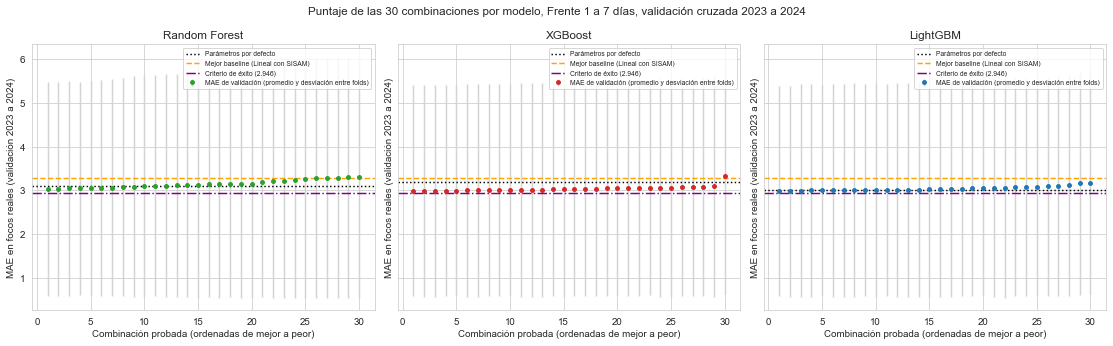

In [13]:
t7 = pd.concat(TUNING, ignore_index=True).query("tarea == 'f1_7d'").reset_index(drop=True)
t2 = pd.concat(TUNING, ignore_index=True).query("tarea == 'f2'").reset_index(drop=True)
colores = {"rf": "tab:green", "xgb": "tab:red", "lgbm": "tab:blue"}
fig, ejes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
for eje, nombre in zip(ejes, NOMBRES_MODELO):
    d = t7[t7["modelo"] == nombre].sort_values("puntaje_validacion").reset_index(drop=True)
    eje.errorbar(d.index + 1, d["puntaje_validacion"], yerr=d["desv_validacion"], fmt="o", color=colores[nombre], ecolor="lightgray", markersize=4,
                 label="MAE de validación (promedio y desviación entre folds)")
    eje.axhline(float(defecto_7d.loc[nombre]), color="black", linestyle=":", label="Parámetros por defecto")
    eje.axhline(3.274, color="orange", linestyle="--", label="Mejor baseline (Lineal con SISAM)")
    eje.axhline(2.946, color="purple", linestyle="-.", label="Criterio de éxito (2.946)")
    eje.set_title(NOMBRES_MODELO[nombre])
    eje.set_xlabel("Combinación probada (ordenadas de mejor a peor)")
    eje.set_ylabel("MAE en focos reales (validación 2023 a 2024)")
    eje.legend(fontsize=7)
fig.suptitle("Puntaje de las 30 combinaciones por modelo, Frente 1 a 7 días, validación cruzada 2023 a 2024")
plt.tight_layout()
plt.show()


**Figura 1.** MAE de validación (promedio y desviación entre folds) de las 30 combinaciones probadas de cada modelo a 7 días, con la referencia de los parámetros por defecto, el mejor baseline y el criterio de éxito. Búsqueda aleatoria con los 4 folds.


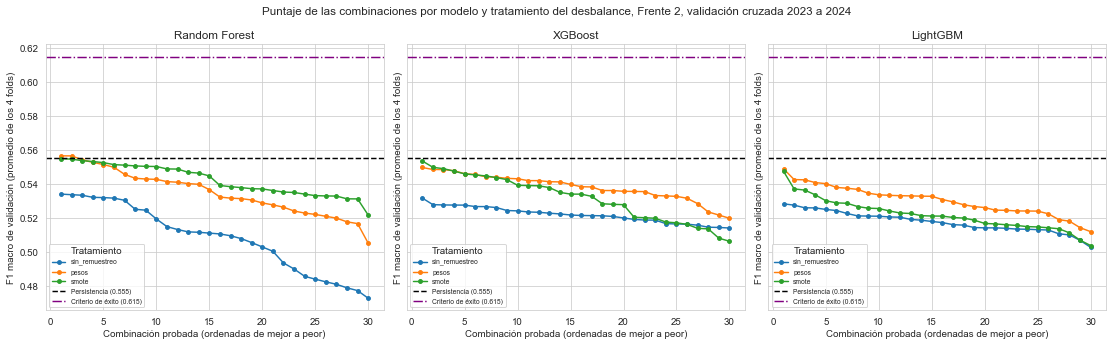

In [14]:
fig, ejes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
estilos = {"sin_remuestreo": "tab:blue", "pesos": "tab:orange", "smote": "tab:green"}
for eje, nombre in zip(ejes, NOMBRES_MODELO):
    for tratamiento, color in estilos.items():
        d = t2[(t2["modelo"] == nombre) & (t2["tratamiento"] == tratamiento)].sort_values("puntaje_validacion", ascending=False).reset_index(drop=True)
        eje.plot(d.index + 1, d["puntaje_validacion"], marker="o", markersize=4, color=color, label=tratamiento)
    eje.axhline(0.555, color="black", linestyle="--", label="Persistencia (0.555)")
    eje.axhline(0.615, color="purple", linestyle="-.", label="Criterio de éxito (0.615)")
    eje.set_title(NOMBRES_MODELO[nombre])
    eje.set_xlabel("Combinación probada (ordenadas de mejor a peor)")
    eje.set_ylabel("F1 macro de validación (promedio de los 4 folds)")
    eje.legend(fontsize=7, title="Tratamiento")
fig.suptitle("Puntaje de las combinaciones por modelo y tratamiento del desbalance, Frente 2, validación cruzada 2023 a 2024")
plt.tight_layout()
plt.show()


**Figura 2.** F1 macro de validación de las combinaciones probadas de cada modelo del Frente 2 con tres tratamientos del desbalance (sin remuestreo, pesos de clase y SMOTE), con la persistencia y el criterio de éxito.


In [15]:
# 30 dias: se reutilizan los parametros de 7 dias; si no se llega al criterio, se busca aparte solo ese horizonte
def parametros_de(fila):
    return json.loads(fila["parametros"])


PARAMS_AJUSTADOS = {"f1_7d": {n: parametros_de(MEJORES["f1_7d"].set_index("modelo").loc[n]) for n in NOMBRES_MODELO}}
for nombre in NOMBRES_MODELO:
    evaluar_cv("f1_30d", nombre, "ajustado_con_parametros_de_7d", "no aplica", "con", PARAMS_AJUSTADOS["f1_7d"][nombre])
res = pd.DataFrame(REGISTROS)
mae30_fold = res[(res["frente"] == "f1_30d") & (res["variante"] == "ajustado_con_parametros_de_7d") & (res["metrica"] == "MAE")].pivot_table(index="fold", columns="modelo", values="valor")
base30 = res[(res["frente"] == "f1_30d") & (res["modelo"] == "arbol") & (res["variante"] == "baseline") & (res["metrica"] == "MAE")].set_index("fold")["valor"]
resumen30 = pd.DataFrame({"MAE_cv": mae30_fold.mean(), "desv": mae30_fold.std(), "folds_mejor_que_baseline": (mae30_fold.lt(base30, axis=0)).sum()})
print("30 días con los parámetros ajustados a 7 días (MAE de validación) y comparación con el mejor baseline (árbol sin SISAM, MAE medio", f"{base30.mean():.3f}):")
mostrar(resumen30, 3)
CRITERIO_30D_CV = 11.044
cumple_30d = bool(((resumen30["MAE_cv"] <= CRITERIO_30D_CV) & (resumen30["folds_mejor_que_baseline"] >= 3)).any())
print(f"\n¿Algún modelo cumple el criterio a 30 días en validación (MAE <= {CRITERIO_30D_CV} y mejor que el baseline en al menos 3 de 4 folds)? {cumple_30d}")


30 días con los parámetros ajustados a 7 días (MAE de validación) y comparación con el mejor baseline (árbol sin SISAM, MAE medio 12.271):
        MAE_cv  desv  folds_mejor_que_baseline
modelo                                        
lgbm    10.031 9.053                         4
rf      10.361 9.295                         4
xgb      9.942 8.904                         4

¿Algún modelo cumple el criterio a 30 días en validación (MAE <= 11.044 y mejor que el baseline en al menos 3 de 4 folds)? True


In [16]:
if cumple_30d:
    print("El criterio se cumple con los parámetros de 7 días: no se hace una búsqueda aparte para 30 días.")
    PARAMS_AJUSTADOS["f1_30d"] = PARAMS_AJUSTADOS["f1_7d"]
    ORIGEN_30D = "parámetros ajustados a 7 días"
else:
    print("El criterio NO se cumple con los parámetros de 7 días: se ajusta aparte solo el horizonte de 30 días (misma búsqueda, 30 combinaciones por modelo).")
    for nombre in NOMBRES_MODELO:
        buscar("f1_30d", nombre, "no aplica", LISTAS["f1"]["con"])
    MEJORES["f1_30d"] = mejores_combinaciones("f1_30d")
    PARAMS_AJUSTADOS["f1_30d"] = {n: parametros_de(MEJORES["f1_30d"].set_index("modelo").loc[n]) for n in NOMBRES_MODELO}
    ORIGEN_30D = "búsqueda aparte para 30 días"
    print("\nMejor combinación por modelo, Frente 1 a 30 días (MAE de validación):")
    mostrar(MEJORES["f1_30d"][["modelo", "combinacion", "puntaje_validacion", "desv_validacion", "puntaje_entrenamiento", "folds_que_superan_persistencia"]].set_index("modelo"), 3)
PARAMS_AJUSTADOS["f2"] = {(r["modelo"], r["tratamiento"]): parametros_de(r) for _, r in MEJORES["f2"].iterrows()}

tuning_total = pd.concat(TUNING, ignore_index=True)
RUTA_TUNING = DIR_RESULTADOS / "avanzado_tuning.csv"
tuning_total.to_csv(RUTA_TUNING, index=False, encoding="utf-8", float_format="%.6g")
print("\nGuardado:", RUTA_TUNING.relative_to(BASE), tuning_total.shape, "| combinaciones por tarea:", tuning_total.groupby("tarea").size().to_dict())
print("Parámetros de 30 días:", ORIGEN_30D)


El criterio se cumple con los parámetros de 7 días: no se hace una búsqueda aparte para 30 días.

Guardado: resultados\avanzado_tuning.csv (360, 13) | combinaciones por tarea: {'f1_7d': 90, 'f2': 270}
Parámetros de 30 días: parámetros ajustados a 7 días


### Hallazgos de esta etapa

**Qué se observa**
- **A 7 días** (ver Figura 1), el mejor MAE de las 30 combinaciones es **2.982** (LightGBM), **2.992** (XGBoost) y **3.040** (Random Forest). El ajuste mejora el MAE por defecto en **6.495 %** (XGBoost), **1.906 %** (Random Forest) y **1.091 %** (LightGBM). El error de entrenamiento de la mejor combinación es **1.708**, **1.537** y **1.833**: la brecha con la validación es de **1.274**, **1.455** y **1.206**.
- **Frente 2** (ver Figura 2): los mejores F1 macro son **0.557** (Random Forest con pesos), **0.555** (Random Forest con SMOTE), **0.554** (XGBoost con SMOTE) y **0.550** (XGBoost con pesos). Sin remuestreo quedan en **0.534**, **0.532** y **0.528**. Respecto de los parámetros por defecto, pesos y SMOTE suben el F1 macro hasta **0.053** (Random Forest con pesos), mientras que sin remuestreo la mejora es de **0.001** a **0.030**.
- La brecha entre entrenamiento y validación del Frente 2 va de **0.126** a **0.451** (la mayor, LightGBM sin remuestreo): hay sobreajuste.
- **A 30 días**, con los parámetros ajustados a 7 días, el MAE de validación es **9.942** (XGBoost), **10.031** (LightGBM) y **10.361** (Random Forest), y los tres superan al baseline en **4** de 4 folds. Como se cumple el criterio (**11.044**), no se hizo una búsqueda aparte para 30 días.

**Por qué importa**
- Para los tres modelos las diferencias de MAE entre las mejores combinaciones son pequeñas, así que el modelo importa menos que el tratamiento del desbalance en el Frente 2.
- El sobreajuste se controla con la validación temporal, pero queda una brecha importante entre entrenamiento y validación.

**Qué implica para el modelado**
- En el Frente 2 conviene usar pesos de clase o SMOTE y no el entrenamiento sin remuestreo.
- **Limitación:** los parámetros de 7 días se reutilizan a 30 días; SMOTE sobre variables binarias (`uf_*`) genera valores intermedios sin sentido físico; y 30 combinaciones por modelo es una búsqueda acotada.


## 4. Evaluación en validación cruzada

Con los mejores parámetros de cada modelo se evalúan los 4 folds con todas las métricas del baseline. En el Frente 2 se evalúan los tres tratamientos del desbalance de cada modelo. Se agrega el **ROC-AUC uno contra el resto** por clase. Luego se compara con el mejor baseline de `baseline_metricas.csv`.


In [17]:
for tarea in ["f1_7d", "f1_30d"]:
    for nombre in NOMBRES_MODELO:
        evaluar_cv(tarea, nombre, "ajustado", "no aplica", "con", PARAMS_AJUSTADOS[tarea][nombre])
for (nombre, tratamiento), params in PARAMS_AJUSTADOS["f2"].items():
    evaluar_cv("f2", nombre, "ajustado", tratamiento, "con", params)
res = pd.DataFrame(REGISTROS)

for tarea, titulo in [("f1_7d", "Frente 1 a 7 días"), ("f1_30d", "Frente 1 a 30 días")]:
    print(f"{titulo}, modelos ajustados (con SISAM). Promedio +/- desviación entre folds:")
    print(como_texto(resumen_cv(tarea, "todas", ["MAE", "RMSE", "MAE_con_focos", "R2_log1p", "sesgo"], variante="ajustado")).to_string())
    print()
print("Frente 1 a 7 días: KPI de alerta de los modelos ajustados:")
print(como_texto(resumen_cv("f1_7d", "todas", ["recall_alerta", "precision_alerta", "tasa_falsas_alarmas"], variante="ajustado")).to_string())


Frente 1 a 7 días, modelos ajustados (con SISAM). Promedio +/- desviación entre folds:
                                               MAE               RMSE    MAE_con_focos         R2_log1p             sesgo
variante modelo tratamiento sisam                                                                                        
ajustado lgbm   no aplica   con    2.982 +/- 2.767  14.102 +/- 13.883  6.487 +/- 3.874  0.592 +/- 0.077  -1.549 +/- 1.606
         rf     no aplica   con    3.040 +/- 2.812  14.027 +/- 13.501  6.547 +/- 3.954  0.587 +/- 0.077  -1.694 +/- 1.715
         xgb    no aplica   con    3.004 +/- 2.803  14.204 +/- 13.997  6.515 +/- 3.946  0.588 +/- 0.076  -1.518 +/- 1.537

Frente 1 a 30 días, modelos ajustados (con SISAM). Promedio +/- desviación entre folds:
                                                MAE               RMSE     MAE_con_focos         R2_log1p             sesgo
variante modelo tratamiento sisam                                                         

In [18]:
for subconjunto, texto in [("con_clase_t", "filas con clase de la semana actual (comparable con la persistencia)"), ("todas", "todas las filas con valido_f2")]:
    print(f"Frente 2, modelos ajustados (con SISAM), {texto}:")
    print(como_texto(resumen_cv("f2", subconjunto, ["accuracy", "F1_macro", "recall_critico", "error_ordinal", "AUC_macro"], variante="ajustado")).to_string())
    print()
print("Frente 2 (todas las filas), F1 y recall por clase y ROC-AUC por clase, promedio entre folds:")
por_clase = resumen_cv("f2", "todas", [f"{p}_{c}" for c in CLASES for p in ["F1", "recall", "AUC"]], variante="ajustado")
mostrar(por_clase.xs("mean", axis=1, level=0), 3)


Frente 2, modelos ajustados (con SISAM), filas con clase de la semana actual (comparable con la persistencia):
                                             accuracy         F1_macro   recall_critico    error_ordinal        AUC_macro
variante modelo tratamiento    sisam                                                                                     
ajustado lgbm   pesos          con    0.667 +/- 0.056  0.560 +/- 0.066  0.507 +/- 0.262  0.399 +/- 0.068  0.866 +/- 0.029
                sin_remuestreo con    0.678 +/- 0.074  0.540 +/- 0.040  0.511 +/- 0.216  0.427 +/- 0.116  0.864 +/- 0.031
                smote          con    0.678 +/- 0.059  0.562 +/- 0.056  0.530 +/- 0.238  0.397 +/- 0.072  0.866 +/- 0.028
         rf     pesos          con    0.686 +/- 0.060  0.570 +/- 0.065  0.509 +/- 0.278  0.380 +/- 0.072  0.871 +/- 0.027
                sin_remuestreo con    0.689 +/- 0.065  0.546 +/- 0.056  0.543 +/- 0.274  0.409 +/- 0.097  0.870 +/- 0.027
                smote          con 

In [19]:
def mejor_baseline_csv(tarea, subconjunto, metrica, sentido):
    # mejor valor de validacion (promedio) entre la persistencia y los modelos base de baseline_metricas.csv
    r = BASE_METRICAS[(BASE_METRICAS["frente"] == tarea) & (BASE_METRICAS["evaluacion"] == "cv_promedio") & (BASE_METRICAS["subconjunto"] == subconjunto)
                      & (BASE_METRICAS["metrica"] == metrica)]
    fila = r.loc[r["valor"].idxmin()] if sentido == "menor" else r.loc[r["valor"].idxmax()]
    return f"{fila['modelo']} {fila['sisam']}".replace(" no aplica", ""), float(fila["valor"])


def mejor_avanzado(tarea, subconjunto, metrica, sentido, variante="ajustado"):
    t = res[(res["frente"] == tarea) & (res["evaluacion"] == "cv_fold") & (res["subconjunto"] == subconjunto) & (res["metrica"] == metrica) & (res["variante"] == variante)]
    t = t.groupby(["modelo", "tratamiento", "sisam"])["valor"].mean()
    clave = t.idxmin() if sentido == "menor" else t.idxmax()
    return clave, float(t.loc[clave])


filas = []
for tarea, subconjunto, metrica, sentido in [("f1_7d", "todas", "MAE", "menor"), ("f1_7d", "todas", "RMSE", "menor"), ("f1_7d", "todas", "MAE_con_focos", "menor"),
                                             ("f1_7d", "todas", "R2_log1p", "mayor"), ("f1_30d", "todas", "MAE", "menor"), ("f1_30d", "todas", "RMSE", "menor"),
                                             ("f1_7d", "todas", "recall_alerta", "mayor"), ("f1_7d", "todas", "tasa_falsas_alarmas", "menor"),
                                             ("f2", "con_clase_t", "F1_macro", "mayor"), ("f2", "con_clase_t", "recall_critico", "mayor"),
                                             ("f2", "con_clase_t", "accuracy", "mayor"), ("f2", "con_clase_t", "error_ordinal", "menor")]:
    nombre_base, valor_base = mejor_baseline_csv(tarea, subconjunto, metrica, sentido)
    clave, valor_avanzado = mejor_avanzado(tarea, subconjunto, metrica, sentido)
    filas.append({"tarea": tarea, "metrica": metrica, "mejor_baseline": nombre_base, "valor_baseline": valor_base,
                  "mejor_avanzado": f"{clave[0]} {clave[1]}".replace(" no aplica", ""), "valor_avanzado": valor_avanzado, "mejor_es": sentido})
comparacion_baseline = pd.DataFrame(filas)
comparacion_baseline["cambio_pct"] = (comparacion_baseline["valor_avanzado"] / comparacion_baseline["valor_baseline"] - 1) * 100
print("Mejor baseline (baseline_metricas.csv) frente al mejor modelo avanzado ajustado, en validación (promedio de los 4 folds):")
print(comparacion_baseline.to_string(index=False, float_format=lambda v: f"{v:,.3f}"))


Mejor baseline (baseline_metricas.csv) frente al mejor modelo avanzado ajustado, en validación (promedio de los 4 folds):
 tarea             metrica mejor_baseline  valor_baseline    mejor_avanzado  valor_avanzado mejor_es  cambio_pct
 f1_7d                 MAE     lineal con           3.274              lgbm           2.982    menor      -8.893
 f1_7d                RMSE   persistencia          14.205                rf          14.027    menor      -1.252
 f1_7d       MAE_con_focos     lineal sin           7.015              lgbm           6.487    menor      -7.528
 f1_7d            R2_log1p     lineal sin           0.562              lgbm           0.592    mayor       5.292
f1_30d                 MAE      arbol sin          12.271               xgb           9.942    menor     -18.979
f1_30d                RMSE      arbol sin          52.938               xgb          45.434    menor     -14.176
 f1_7d       recall_alerta   persistencia           0.579              lgbm           0

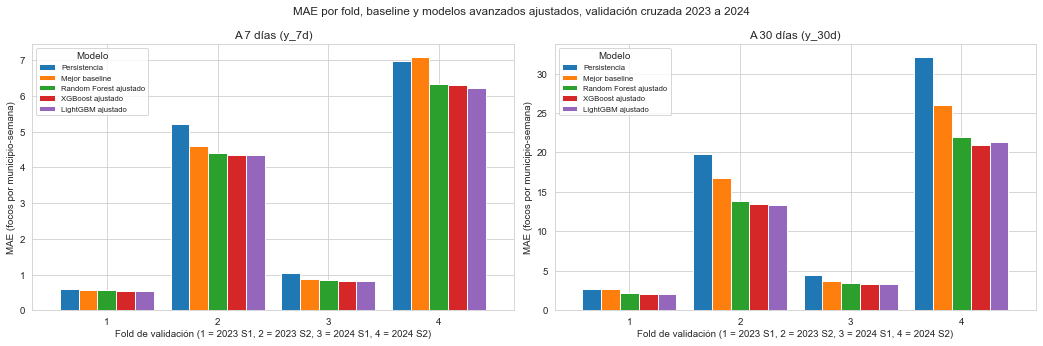

In [20]:
mae_f = res[(res["metrica"] == "MAE") & (res["evaluacion"] == "cv_fold") & res["frente"].isin(["f1_7d", "f1_30d"])]
fig, ejes = plt.subplots(1, 2, figsize=(15, 5))
orden = ["Persistencia", "Mejor baseline", "Random Forest ajustado", "XGBoost ajustado", "LightGBM ajustado"]
for eje, tarea, titulo, (bm, bs) in [(ejes[0], "f1_7d", "A 7 días (y_7d)", ("lineal", "con")), (ejes[1], "f1_30d", "A 30 días (y_30d)", ("arbol", "sin"))]:
    d = mae_f[mae_f["frente"] == tarea]
    partes = [d[d["modelo"] == "persistencia"].assign(etiqueta="Persistencia"),
              d[(d["variante"] == "baseline") & (d["modelo"] == bm) & (d["sisam"] == bs)].assign(etiqueta="Mejor baseline"),
              d[(d["variante"] == "ajustado") & (d["sisam"] == "con")].assign(etiqueta=lambda x: x["modelo"].map(NOMBRES_MODELO) + " ajustado")]
    pd.concat(partes).pivot_table(index="fold", columns="etiqueta", values="valor")[orden].plot(kind="bar", ax=eje, width=0.85)
    eje.set_title(titulo)
    eje.set_xlabel("Fold de validación (1 = 2023 S1, 2 = 2023 S2, 3 = 2024 S1, 4 = 2024 S2)")
    eje.set_ylabel("MAE (focos por municipio-semana)")
    eje.legend(title="Modelo", fontsize=8)
    plt.setp(eje.get_xticklabels(), rotation=0)
fig.suptitle("MAE por fold, baseline y modelos avanzados ajustados, validación cruzada 2023 a 2024")
plt.tight_layout()
plt.show()


**Figura 3.** MAE en focos reales de la persistencia, el mejor baseline y los tres modelos avanzados ajustados en cada fold de validación, a 7 y a 30 días.


### Hallazgos de esta etapa

**Qué se observa**
- **A 7 días** (ver Figura 3), los modelos ajustados dan MAE de **2.982** (LightGBM), **3.004** (XGBoost) y **3.040** (Random Forest), frente a **3.274** del mejor baseline (**-8.893 %**). El RMSE mejora poco (**14.027** frente a **14.205** de la persistencia, **-1.252 %**) y el R² en `log1p` sube de **0.562** a **0.592**. El sesgo es negativo (por ejemplo **-1.549** en LightGBM): subestiman.
- **A 30 días**, el mejor es XGBoost con MAE **9.942** frente a **12.271** (**-18.979 %**) y RMSE **45.434** frente a **52.938** (**-14.176 %**).
- **KPI de alerta a 7 días:** el recall de LightGBM es **0.477** (persistencia **0.579**, Regresión Lineal **0.436**) con precisión de **0.761** y falsas alarmas de **0.014**.
- **Frente 2** (filas con clase de la semana actual): el mejor F1 macro es **0.573** (Random Forest con SMOTE) frente a **0.555** de la persistencia (**+3.094 %**); el recall de Crítico es **0.543** (Random Forest sin remuestreo) frente a **0.545**; el error ordinal baja de **0.393** a **0.380**; el ROC-AUC macro es **0.871**.

**Por qué importa**
- A 7 días la mejora es real pero menor que el 10 % exigido; a 30 días es mayor porque hay más señal acumulada.
- En el Frente 2 los modelos apenas mejoran a la persistencia de clase, y no superan su recall de Crítico.

**Qué implica para el modelado**
- El criterio de 7 días queda cerca, pero no se alcanza en validación. La subestimación de los picos es el principal límite.


## 5. Ablación con y sin SISAM

Con los **mejores parámetros de cada modelo** (sin volver a buscar) se evalúa con `features_sin_sisam` y se compara con la versión con SISAM, **en validación**. La decisión sobre la lista de variables se toma con la validación; la comparación en 2025 aparece en la sección 6, junto con la evaluación única de 2025, y no interviene en la decisión.

**Regla de decisión:** SISAM entra a la lista final de una tarea solo si, con el mejor modelo de esa tarea, mejora el promedio de validación (MAE al menos 1 % menor, o F1 macro al menos 0.01 mayor) **y** lo hace en al menos 3 de 4 folds. Si no, se usa la lista sin SISAM, que es más simple y no depende de un pronóstico de 2026 sin calibrar.


In [21]:
for tarea in ["f1_7d", "f1_30d"]:
    for nombre in NOMBRES_MODELO:
        evaluar_cv(tarea, nombre, "ajustado", "no aplica", "sin", PARAMS_AJUSTADOS[tarea][nombre])
for (nombre, tratamiento), params in PARAMS_AJUSTADOS["f2"].items():
    evaluar_cv("f2", nombre, "ajustado", tratamiento, "sin", params)
res = pd.DataFrame(REGISTROS)

def por_fold(tarea, metrica, subconjunto="todas"):
    # metrica por fold de los modelos avanzados ajustados (columnas: modelo, tratamiento, lista de variables)
    r = res[(res["frente"] == tarea) & (res["evaluacion"] == "cv_fold") & (res["variante"] == "ajustado") & (res["metrica"] == metrica) & (res["subconjunto"] == subconjunto)]
    return r.pivot_table(index="fold", columns=["modelo", "tratamiento", "sisam"], values="valor")


filas = []
for tarea, metrica in [("f1_7d", "MAE"), ("f1_30d", "MAE"), ("f2", "F1_macro")]:
    t = por_fold(tarea, metrica)
    for (modelo, tratamiento, sisam) in [c for c in t.columns if c[2] == "con"]:
        con, sin = t[(modelo, tratamiento, "con")], t[(modelo, tratamiento, "sin")]
        mejora = (1 - con / sin) * 100 if tarea != "f2" else (con - sin)
        folds_ok = int((con < sin).sum()) if tarea != "f2" else int((con > sin).sum())
        filas.append({"tarea": tarea, "modelo": NOMBRES_MODELO[modelo], "tratamiento": tratamiento, "metrica": metrica, "con_SISAM": con.mean(), "sin_SISAM": sin.mean(),
                      "mejora_con_SISAM": mejora.mean(), "folds_donde_SISAM_mejora": folds_ok})
ablacion = pd.DataFrame(filas)
print("Ablación en validación (promedio de los 4 folds). Mejora con SISAM: en % del MAE (Frente 1) o en puntos de F1 macro (Frente 2):")
print(ablacion.to_string(index=False, float_format=lambda v: f"{v:,.3f}"))


Ablación en validación (promedio de los 4 folds). Mejora con SISAM: en % del MAE (Frente 1) o en puntos de F1 macro (Frente 2):
 tarea        modelo    tratamiento  metrica  con_SISAM  sin_SISAM  mejora_con_SISAM  folds_donde_SISAM_mejora
 f1_7d      LightGBM      no aplica      MAE      2.982      3.001             0.599                         3
 f1_7d Random Forest      no aplica      MAE      3.040      3.041            -0.050                         2
 f1_7d       XGBoost      no aplica      MAE      3.004      3.026             0.452                         3
f1_30d      LightGBM      no aplica      MAE     10.031     10.040             0.215                         3
f1_30d Random Forest      no aplica      MAE     10.361     10.410             0.337                         3
f1_30d       XGBoost      no aplica      MAE      9.942     10.172             1.675                         4
    f2      LightGBM          pesos F1_macro      0.549      0.547             0.002           

In [22]:
# mejor modelo de cada tarea (segun validacion con SISAM) y regla de decision sobre SISAM
def decidir_sisam(tarea):
    metrica, mayor = ("F1_macro", True) if tarea == "f2" else ("MAE", False)
    t = por_fold(tarea, metrica)
    con = t.xs("con", axis=1, level="sisam")
    clave = con.mean().idxmax() if mayor else con.mean().idxmin()
    c, s = t[(*clave, "con")], t[(*clave, "sin")]
    if mayor:
        mejora, folds, entra = float((c - s).mean()), int((c > s).sum()), (c - s).mean() >= 0.01 and (c > s).sum() >= 3
    else:
        mejora, folds, entra = float((1 - c / s).mean() * 100), int((c < s).sum()), (1 - c / s).mean() >= 0.01 and (c < s).sum() >= 3
    return {"tarea": tarea, "mejor_modelo_con_SISAM": f"{NOMBRES_MODELO[clave[0]]} {clave[1]}".replace(" no aplica", ""), "metrica": metrica,
            "con_SISAM": float(c.mean()), "sin_SISAM": float(s.mean()), "mejora": mejora, "folds_donde_mejora": folds, "SISAM_entra": bool(entra)}


decision_sisam = pd.DataFrame([decidir_sisam(t) for t in TAREAS])
print("Decisión sobre SISAM por tarea (validación):")
print(decision_sisam.to_string(index=False, float_format=lambda v: f"{v:,.3f}"))
LISTA_FINAL = {t: ("con" if d else "sin") for t, d in zip(decision_sisam["tarea"], decision_sisam["SISAM_entra"])}
print("\nLista de variables final por tarea:", LISTA_FINAL)
print("Features por lista:", {f"{f}_{s}": len(l) for f, d in LISTAS.items() for s, l in d.items()})


Decisión sobre SISAM por tarea (validación):
 tarea mejor_modelo_con_SISAM  metrica  con_SISAM  sin_SISAM  mejora  folds_donde_mejora  SISAM_entra
 f1_7d               LightGBM      MAE      2.982      3.001   0.599                   3        False
f1_30d                XGBoost      MAE      9.942     10.172   1.675                   4         True
    f2    Random Forest pesos F1_macro      0.557      0.551   0.006                   2        False

Lista de variables final por tarea: {'f1_7d': 'sin', 'f1_30d': 'con', 'f2': 'sin'}
Features por lista: {'f1_con': 42, 'f1_sin': 37, 'f2_con': 44, 'f2_sin': 39}


### Hallazgos de esta etapa

**Qué se observa**
- **A 7 días**, con SISAM el MAE es **2.982** (LightGBM) frente a **3.001** sin SISAM (mejora de **0.599 %** en **3** de 4 folds); en Random Forest es **3.040** y **3.041**; en XGBoost **3.004** y **3.026** (**0.452 %**).
- **A 30 días**, XGBoost mejora **1.675 %** con SISAM (**9.942** frente a **10.172**) en **4** de 4 folds; LightGBM **10.031** frente a **10.040** y Random Forest **10.361** frente a **10.410**.
- **Frente 2:** las diferencias de F1 macro entre con y sin SISAM van de **-0.003** a **0.008**; con el mejor modelo, **0.557** frente a **0.551**, en **2** de 4 folds.
- **Decisión por la regla** (mejora de al menos 1 % del MAE o 0.01 de F1 macro y en al menos 3 de 4 folds): **a 7 días no entra SISAM** (0.599 %), **a 30 días sí entra** (1.675 % y 4 de 4 folds) y **en el Frente 2 no entra** (0.006).

**Por qué importa**
- El aporte de SISAM es pequeño. La mejora a 30 días supera el umbral, pero es del orden de 0.2 puntos de MAE.

**Qué implica para el modelado**
- **Limitación:** SISAM de 2026 es un pronóstico sin calibrar, con otro nivel que el reanálisis (ver el EDA). El modelo a 30 días con SISAM depende de esa fuente en línea; si se prefiere un pipeline sin esa dependencia, se puede usar la versión sin SISAM, cuyo MAE de validación es **10.172**.
- Para los pronósticos a 7 días y la clase de riesgo, la lista final es **sin SISAM**.


## 6. Modelo final y prueba 2025 (una sola vez)

**Reglas de elección** (cerradas con la validación): para cada tarea se elige el modelo con el menor MAE promedio de los 4 folds (mayor F1 macro en el Frente 2), con la lista de variables decidida en la sección 5; en empate, el que supera a la persistencia en más folds. Después se **reajusta con todo el entrenamiento** y se evalúa 2025 **una sola vez**.

En esa única pasada por 2025 se evalúan, ajustados con todo el entrenamiento, los modelos por defecto y los ajustados (con y sin SISAM) para completar la tabla comparativa; **ninguno de esos resultados se usó para elegir nada**.


In [23]:
def elegir_modelo(tarea, lista):
    # modelo (y tratamiento) ganador de la tarea con la lista de variables decidida
    metrica, mayor = ("F1_macro", True) if tarea == "f2" else ("MAE", False)
    t = por_fold(tarea, metrica).xs(lista, axis=1, level="sisam")
    pers = res[(res["frente"] == tarea) & (res["modelo"] == "persistencia") & (res["metrica"] == metrica)].set_index("fold")["valor"]
    resumen = pd.DataFrame({"media": t.mean(), "folds": [(t[c] > pers).sum() if mayor else (t[c] < pers).sum() for c in t.columns]})
    resumen["_r"] = resumen["media"].round(4)
    resumen = resumen.sort_values(["_r", "folds"], ascending=[not mayor, False])
    return resumen.index[0], resumen


ELEGIDOS = {}
for tarea in TAREAS:
    clave, tabla = elegir_modelo(tarea, LISTA_FINAL[tarea])
    ELEGIDOS[tarea] = {"modelo": clave[0], "tratamiento": clave[1], "sisam": LISTA_FINAL[tarea]}
    print(f"{tarea}: modelo elegido = {NOMBRES_MODELO[clave[0]]}" + (f" con {clave[1]}" if tarea == 'f2' else "") + f" | lista {'con' if LISTA_FINAL[tarea] == 'con' else 'sin'} SISAM")
    tabla.index = [f"{NOMBRES_MODELO[a]} {b}".replace(" no aplica", "") for a, b in tabla.index]
    mostrar(tabla[["media", "folds"]].rename(columns={"media": "metrica_validacion", "folds": "folds_que_superan_persistencia"}), 3)


f1_7d: modelo elegido = LightGBM | lista sin SISAM
               metrica_validacion  folds_que_superan_persistencia
LightGBM                    3.001                               4
XGBoost                     3.026                               4
Random Forest               3.041                               4
f1_30d: modelo elegido = XGBoost | lista con SISAM
               metrica_validacion  folds_que_superan_persistencia
XGBoost                     9.942                               4
LightGBM                   10.031                               4
Random Forest              10.361                               4
f2: modelo elegido = Random Forest con smote | lista sin SISAM
                              metrica_validacion  folds_que_superan_persistencia
Random Forest smote                        0.554                               2
Random Forest pesos                        0.551                               1
LightGBM smote                             0.550                

In [24]:
# UNICA evaluacion en 2025: modelos ajustados con todo el entrenamiento
MODELOS_AJUSTADOS = {}      # (tarea, variante, modelo, tratamiento, sisam) -> modelo ajustado con todo el entrenamiento
PRED_2025 = {}              # (tarea, variante, modelo, tratamiento, sisam) -> (indices, real, pred)
idx_prueba = panel.index[es_prueba]


def ajustar_y_evaluar_2025(tarea, nombre, variante, tratamiento, sisam, params):
    columnas = LISTAS[frente_de(tarea)][sisam]
    tr, te = IDX_BASE[tarea], filas_validas(tarea, idx_prueba)
    if tarea == "f2":
        modelo = crear_f2(nombre, tratamiento, params).fit(panel.loc[tr, columnas], panel.loc[tr, "clase_t1_ord"].astype(int))
        pred = modelo.predict(panel.loc[te, columnas]).astype(float)
        proba = modelo.predict_proba(panel.loc[te, columnas])
        real = panel.loc[te, "clase_t1_ord"].to_numpy(float)
        registrar(tarea, nombre, variante, tratamiento, sisam, "prueba_2025", 0, "todas", metricas_f2(real, pred, proba))
        con = panel.loc[te, "clase_t_ord"].notna().to_numpy()
        registrar(tarea, nombre, variante, tratamiento, sisam, "prueba_2025", 0, "con_clase_t", metricas_f2(real[con], pred[con], proba[con]))
    else:
        modelo = crear_f1(nombre, params).fit(panel.loc[tr, columnas], panel.loc[tr, OBJETIVO[tarea]])
        pred = modelo.predict(panel.loc[te, columnas])
        real = panel.loc[te, OBJETIVO[tarea]].to_numpy(float)
        m = metricas_f1(real, pred)
        if tarea == "f1_7d":
            m.update(metricas_alerta(real, pred, panel.loc[te, "objetivo_seca"]))
        registrar(tarea, nombre, variante, tratamiento, sisam, "prueba_2025", 0, "todas", m)
    MODELOS_AJUSTADOS[(tarea, variante, nombre, tratamiento, sisam)] = modelo
    PRED_2025[(tarea, variante, nombre, tratamiento, sisam)] = (te, real, pred)


inicio = time.time()
for tarea in ["f1_7d", "f1_30d"]:
    for nombre in NOMBRES_MODELO:
        ajustar_y_evaluar_2025(tarea, nombre, "defecto", "no aplica", "con", None)
        for sisam in ["con", "sin"]:
            ajustar_y_evaluar_2025(tarea, nombre, "ajustado", "no aplica", sisam, PARAMS_AJUSTADOS[tarea][nombre])
for nombre in NOMBRES_MODELO:
    ajustar_y_evaluar_2025("f2", nombre, "defecto", "sin_remuestreo", "con", None)
for (nombre, tratamiento), params in PARAMS_AJUSTADOS["f2"].items():
    for sisam in ["con", "sin"]:
        ajustar_y_evaluar_2025("f2", nombre, "ajustado", tratamiento, sisam, params)
# persistencia en 2025
for tarea in TAREAS:
    te = filas_validas(tarea, idx_prueba)
    pred = persistencia(tarea, te)
    if tarea == "f2":
        con = ~np.isnan(pred)
        real = panel.loc[te, "clase_t1_ord"].to_numpy(float)
        registrar(tarea, "persistencia", "baseline", "no aplica", "no aplica", "prueba_2025", 0, "con_clase_t", metricas_f2(real[con], pred[con]))
    else:
        real = panel.loc[te, OBJETIVO[tarea]].to_numpy(float)
        m = metricas_f1(real, pred)
        if tarea == "f1_7d":
            m.update(metricas_alerta(real, pred, panel.loc[te, "objetivo_seca"]))
        registrar(tarea, "persistencia", "baseline", "no aplica", "no aplica", "prueba_2025", 0, "todas", m)
res = pd.DataFrame(REGISTROS)
print(f"Evaluación única de 2025 completa: {len(MODELOS_AJUSTADOS)} modelos ajustados con todo el entrenamiento ({time.time() - inicio:,.0f} s)")
print("Filas evaluadas en 2025:", {t: len(filas_validas(t, idx_prueba)) for t in TAREAS})


Evaluación única de 2025 completa: 39 modelos ajustados con todo el entrenamiento (222 s)
Filas evaluadas en 2025: {'f1_7d': 27693, 'f1_30d': 27693, 'f2': 6601}


In [25]:
def valor_2025(tarea, subconjunto, metrica, modelo, variante, tratamiento, sisam):
    r = res[(res["frente"] == tarea) & (res["evaluacion"] == "prueba_2025") & (res["subconjunto"] == subconjunto) & (res["metrica"] == metrica) & (res["modelo"] == modelo)
            & (res["variante"] == variante) & (res["tratamiento"] == tratamiento) & (res["sisam"] == sisam)]
    return float(r["valor"].iloc[0])


def valor_cv(tarea, subconjunto, metrica, modelo, variante, tratamiento, sisam):
    r = res[(res["frente"] == tarea) & (res["evaluacion"] == "cv_fold") & (res["subconjunto"] == subconjunto) & (res["metrica"] == metrica) & (res["modelo"] == modelo)
            & (res["variante"] == variante) & (res["tratamiento"] == tratamiento) & (res["sisam"] == sisam)]
    return float(r["valor"].mean()), float(r["valor"].std())


filas = []
for tarea in ["f1_7d", "f1_30d"]:
    e = ELEGIDOS[tarea]
    cv_media, cv_desv = valor_cv(tarea, "todas", "MAE", e["modelo"], "ajustado", "no aplica", e["sisam"])
    base_nombre, base_modelo = {"f1_7d": ("Lineal con SISAM", ("lineal", "con")), "f1_30d": ("Árbol sin SISAM", ("arbol", "sin"))}[tarea]
    mae_base = res[(res["frente"] == tarea) & (res["variante"] == "baseline") & (res["modelo"] == base_modelo[0]) & (res["sisam"] == base_modelo[1]) & (res["metrica"] == "MAE")].set_index("fold")["valor"]
    mae_av = res[(res["frente"] == tarea) & (res["modelo"] == e["modelo"]) & (res["variante"] == "ajustado") & (res["sisam"] == e["sisam"]) & (res["metrica"] == "MAE")
                 & (res["evaluacion"] == "cv_fold")].set_index("fold")["valor"]
    folds_mejor = int((mae_av < mae_base).sum())
    umbral_cv, umbral_25 = {"f1_7d": (2.946, 1.165), "f1_30d": (11.044, 4.523)}[tarea]
    mae25 = valor_2025(tarea, "todas", "MAE", e["modelo"], "ajustado", "no aplica", e["sisam"])
    filas.append({"criterio": f"{tarea}: MAE de validación <= {umbral_cv}", "valor": cv_media, "umbral": umbral_cv, "cumple": cv_media <= umbral_cv})
    filas.append({"criterio": f"{tarea}: MAE de 2025 <= {umbral_25}", "valor": mae25, "umbral": umbral_25, "cumple": mae25 <= umbral_25})
    filas.append({"criterio": f"{tarea}: mejor que {base_nombre} en al menos 3 de 4 folds", "valor": folds_mejor, "umbral": 3, "cumple": folds_mejor >= 3})
for subconjunto in ["con_clase_t", "todas"]:
    e = ELEGIDOS["f2"]
    f1_cv, _ = valor_cv("f2", subconjunto, "F1_macro", e["modelo"], "ajustado", e["tratamiento"], e["sisam"])
    rc_cv, _ = valor_cv("f2", subconjunto, "recall_critico", e["modelo"], "ajustado", e["tratamiento"], e["sisam"])
    f1_25 = valor_2025("f2", subconjunto, "F1_macro", e["modelo"], "ajustado", e["tratamiento"], e["sisam"])
    rc_25 = valor_2025("f2", subconjunto, "recall_critico", e["modelo"], "ajustado", e["tratamiento"], e["sisam"])
    filas += [{"criterio": f"f2 ({subconjunto}): F1 macro de validación >= 0.615", "valor": f1_cv, "umbral": 0.615, "cumple": f1_cv >= 0.615},
              {"criterio": f"f2 ({subconjunto}): recall de Crítico de validación >= 0.645", "valor": rc_cv, "umbral": 0.645, "cumple": rc_cv >= 0.645},
              {"criterio": f"f2 ({subconjunto}): F1 macro de 2025 >= 0.615 (referencia)", "valor": f1_25, "umbral": 0.615, "cumple": f1_25 >= 0.615},
              {"criterio": f"f2 ({subconjunto}): recall de Crítico de 2025 >= 0.645 (referencia)", "valor": rc_25, "umbral": 0.645, "cumple": rc_25 >= 0.645}]
tabla_criterios = pd.DataFrame(filas)
tabla_criterios["resultado"] = np.where(tabla_criterios["cumple"], "CUMPLE", "NO CUMPLE")
print("Criterios de éxito del modelo final de cada tarea:")
print(tabla_criterios[["criterio", "valor", "umbral", "resultado"]].to_string(index=False, float_format=lambda v: f"{v:,.3f}"))
pers_f2 = {s: (valor_cv("f2", s, "F1_macro", "persistencia", "baseline", "no aplica", "no aplica") if s == "con_clase_t" else None) for s in ["con_clase_t"]}
print("\nPersistencia en el mismo subconjunto (filas con clase_t): F1 macro de validación", f"{pers_f2['con_clase_t'][0]:.3f}",
      "| recall de Crítico", f"{valor_cv('f2', 'con_clase_t', 'recall_critico', 'persistencia', 'baseline', 'no aplica', 'no aplica')[0]:.3f}")


Criterios de éxito del modelo final de cada tarea:
                                                         criterio  valor  umbral resultado
                                f1_7d: MAE de validación <= 2.946  3.001   2.946 NO CUMPLE
                                      f1_7d: MAE de 2025 <= 1.165  1.270   1.165 NO CUMPLE
       f1_7d: mejor que Lineal con SISAM en al menos 3 de 4 folds  4.000   3.000    CUMPLE
                              f1_30d: MAE de validación <= 11.044  9.942  11.044    CUMPLE
                                     f1_30d: MAE de 2025 <= 4.523  4.616   4.523 NO CUMPLE
       f1_30d: mejor que Árbol sin SISAM en al menos 3 de 4 folds  4.000   3.000    CUMPLE
                f2 (con_clase_t): F1 macro de validación >= 0.615  0.572   0.615 NO CUMPLE
       f2 (con_clase_t): recall de Crítico de validación >= 0.645  0.503   0.645 NO CUMPLE
         f2 (con_clase_t): F1 macro de 2025 >= 0.615 (referencia)  0.591   0.615 NO CUMPLE
f2 (con_clase_t): recall de Crítico de 

In [26]:
# tabla unica del modelo elegido por tarea: parametros, lista de variables y metricas de validacion y de 2025
def abreviar(params):
    return ", ".join(f"{k}={v:.4g}" if isinstance(v, float) else f"{k}={v}" for k, v in params.items())


filas = {}
for tarea in TAREAS:
    e = ELEGIDOS[tarea]
    params = PARAMS_AJUSTADOS[tarea][(e["modelo"], e["tratamiento"])] if tarea == "f2" else PARAMS_AJUSTADOS[tarea][e["modelo"]]
    lista = LISTAS[frente_de(tarea)][e["sisam"]]
    sub, trat = ("con_clase_t", e["tratamiento"]) if tarea == "f2" else ("todas", "no aplica")
    metricas = ["accuracy", "F1_macro", "recall_critico", "error_ordinal"] if tarea == "f2" else ["MAE", "RMSE", "MAE_con_focos", "R2_log1p"]
    validacion = "; ".join(f"{m} {valor_cv(tarea, sub, m, e['modelo'], 'ajustado', trat, e['sisam'])[0]:.3f} +/- {valor_cv(tarea, sub, m, e['modelo'], 'ajustado', trat, e['sisam'])[1]:.3f}" for m in metricas)
    prueba = "; ".join(f"{m} {valor_2025(tarea, sub, m, e['modelo'], 'ajustado', trat, e['sisam']):.3f}" for m in metricas)
    filas[tarea] = {"modelo": NOMBRES_MODELO[e["modelo"]], "tratamiento del desbalance": e["tratamiento"] if tarea == "f2" else "no aplica",
                    "lista de variables": f"{'con' if e['sisam'] == 'con' else 'sin'} SISAM ({len(lista)} variables)", "parámetros": abreviar(params),
                    "métricas de validación (promedio +/- desviación)": validacion, "métricas de 2025": prueba}
tabla_elegidos = pd.DataFrame(filas)
with pd.option_context("display.max_colwidth", None, "display.width", 400):
    print(tabla_elegidos.to_string())


                                                                                                                                                                                                         f1_7d                                                                                                                                                   f1_30d                                                                                                                 f2
modelo                                                                                                                                                                                                LightGBM                                                                                                                                                  XGBoost                                                                                                      Random Forest
tratamiento del desbalance                        

In [27]:
# tabla comparativa unica por frente: persistencia, baseline reajustado (baseline_metricas.csv), avanzado por defecto y avanzado ajustado
def fila_baseline(tarea, subconjunto, modelo, sisam, metricas):
    b = BASE_METRICAS[(BASE_METRICAS["frente"] == tarea) & (BASE_METRICAS["modelo"] == modelo) & (BASE_METRICAS["sisam"] == sisam) & (BASE_METRICAS["subconjunto"] == subconjunto)]
    out = {}
    for m in metricas:
        a = b[(b["evaluacion"] == "cv_promedio") & (b["metrica"] == m)]["valor"].iloc[0]
        s = b[(b["evaluacion"] == "cv_desviacion") & (b["metrica"] == m)]["valor"].iloc[0]
        p = b[(b["evaluacion"] == "prueba_2025") & (b["metrica"] == m)]["valor"].iloc[0]
        out[f"{m} validacion"], out[f"{m} 2025"] = f"{a:.3f} +/- {s:.3f}", f"{p:.3f}"
    return out


def fila_avanzada(tarea, subconjunto, modelo, variante, tratamiento, sisam, metricas):
    out = {}
    for m in metricas:
        a, s = valor_cv(tarea, subconjunto, m, modelo, variante, tratamiento, sisam)
        out[f"{m} validacion"], out[f"{m} 2025"] = f"{a:.3f} +/- {s:.3f}", f"{valor_2025(tarea, subconjunto, m, modelo, variante, tratamiento, sisam):.3f}"
    return out


def tabla_frente(tarea, subconjunto, metricas, baselines):
    filas = {}
    for etiqueta, modelo, sisam in baselines:
        filas[etiqueta] = fila_baseline(tarea, subconjunto, modelo, sisam, metricas)
    for nombre in NOMBRES_MODELO:
        filas[f"{NOMBRES_MODELO[nombre]} por defecto (con SISAM)"] = fila_avanzada(tarea, subconjunto, nombre, "defecto", "sin_remuestreo" if tarea == "f2" else "no aplica", "con", metricas)
    for nombre in NOMBRES_MODELO:
        if tarea == "f2":
            trat = MEJORES["f2"][MEJORES["f2"]["modelo"] == nombre].sort_values("puntaje_validacion", ascending=False)["tratamiento"].iloc[0]
        else:
            trat = "no aplica"
        for sisam in ["con", "sin"]:
            filas[f"{NOMBRES_MODELO[nombre]} ajustado{' (' + trat + ')' if tarea == 'f2' else ''} ({sisam} SISAM)"] = fila_avanzada(tarea, subconjunto, nombre, "ajustado", trat, sisam, metricas)
    return pd.DataFrame(filas).T


M1 = ["MAE", "RMSE", "R2_log1p"]
print("FRENTE 1 A 7 DÍAS (validación: promedio +/- desviación entre folds; 2025: una sola evaluación)")
print(tabla_frente("f1_7d", "todas", M1, [("Persistencia", "persistencia", "no aplica"), ("Lineal base con SISAM", "lineal", "con"), ("Lineal base sin SISAM", "lineal", "sin"),
                                         ("Árbol base con SISAM", "arbol", "con"), ("Árbol base sin SISAM", "arbol", "sin")]).to_string())
print("\nFRENTE 1 A 30 DÍAS")
print(tabla_frente("f1_30d", "todas", M1, [("Persistencia", "persistencia", "no aplica"), ("Lineal base con SISAM", "lineal", "con"), ("Lineal base sin SISAM", "lineal", "sin"),
                                          ("Árbol base con SISAM", "arbol", "con"), ("Árbol base sin SISAM", "arbol", "sin")]).to_string())


FRENTE 1 A 7 DÍAS (validación: promedio +/- desviación entre folds; 2025: una sola evaluación)


                                        MAE validacion MAE 2025    RMSE validacion RMSE 2025 R2_log1p validacion R2_log1p 2025
Persistencia                           3.461 +/- 3.130    1.451  14.205 +/- 11.899     5.291     0.399 +/- 0.113         0.357
Lineal base con SISAM                  3.274 +/- 3.134    1.295  15.376 +/- 15.049     4.849     0.561 +/- 0.073         0.533
Lineal base sin SISAM                  3.281 +/- 3.160    1.299  15.728 +/- 15.873     4.823     0.562 +/- 0.076         0.532
Árbol base con SISAM                   3.383 +/- 3.115    1.382  15.094 +/- 13.672     5.611     0.490 +/- 0.105         0.502
Árbol base sin SISAM                   3.357 +/- 3.098    1.376  14.980 +/- 13.690     5.475     0.493 +/- 0.103         0.505
Random Forest por defecto (con SISAM)  3.099 +/- 2.828    1.357  14.115 +/- 13.429     5.346     0.559 +/- 0.087         0.522
XGBoost por defecto (con SISAM)        3.200 +/- 2.979    1.364  15.198 +/- 14.363     6.024     0.548 +/- 0.07

                                          MAE validacion MAE 2025    RMSE validacion RMSE 2025 R2_log1p validacion R2_log1p 2025
Persistencia                           14.752 +/- 13.881    5.802  63.183 +/- 60.743    20.373     0.324 +/- 0.049         0.302
Lineal base con SISAM                  12.451 +/- 12.168    4.655  53.254 +/- 54.313    16.377     0.594 +/- 0.074         0.597
Lineal base sin SISAM                  12.471 +/- 12.126    4.651  53.688 +/- 54.285    16.304     0.593 +/- 0.073         0.596
Árbol base con SISAM                   12.444 +/- 11.211    5.118  53.215 +/- 48.882    22.765     0.548 +/- 0.114         0.590
Árbol base sin SISAM                   12.271 +/- 11.134    5.025  52.938 +/- 48.826    21.429     0.568 +/- 0.085         0.595
Random Forest por defecto (con SISAM)   10.465 +/- 9.301    4.566  46.587 +/- 44.972    18.141     0.646 +/- 0.066         0.641
XGBoost por defecto (con SISAM)        11.157 +/- 10.136    4.825  54.435 +/- 51.564    21.285   

In [28]:
M2 = ["accuracy", "F1_macro", "recall_critico", "error_ordinal"]
print("FRENTE 2 (filas con clase de la semana actual; aquí la persistencia está definida)")
print(tabla_frente("f2", "con_clase_t", M2, [("Persistencia", "persistencia", "no aplica"), ("Árbol base con SISAM", "arbol", "con"), ("Árbol base sin SISAM", "arbol", "sin"),
                                            ("Árbol balanceado base con SISAM", "arbol_balanceado", "con"), ("Árbol balanceado base sin SISAM", "arbol_balanceado", "sin")]).to_string())
print("\nFRENTE 2 (todas las filas con valido_f2; solo modelos avanzados)")
print(tabla_frente("f2", "todas", M2, []).to_string())


FRENTE 2 (filas con clase de la semana actual; aquí la persistencia está definida)


                                           accuracy validacion accuracy 2025 F1_macro validacion F1_macro 2025 recall_critico validacion recall_critico 2025 error_ordinal validacion error_ordinal 2025
Persistencia                                   0.686 +/- 0.064         0.582     0.555 +/- 0.060         0.562           0.545 +/- 0.261               0.635          0.393 +/- 0.072              0.527
Árbol base con SISAM                           0.651 +/- 0.076         0.579     0.519 +/- 0.058         0.541           0.456 +/- 0.203               0.635          0.450 +/- 0.105              0.561
Árbol base sin SISAM                           0.650 +/- 0.079         0.582     0.521 +/- 0.059         0.544           0.457 +/- 0.198               0.649          0.449 +/- 0.108              0.566
Árbol balanceado base con SISAM                0.615 +/- 0.084         0.560     0.511 +/- 0.053         0.553           0.425 +/- 0.251               0.578          0.477 +/- 0.113              0

                                           accuracy validacion accuracy 2025 F1_macro validacion F1_macro 2025 recall_critico validacion recall_critico 2025 error_ordinal validacion error_ordinal 2025
Random Forest por defecto (con SISAM)          0.694 +/- 0.095         0.611     0.504 +/- 0.036         0.520           0.534 +/- 0.213               0.607          0.427 +/- 0.140              0.567
XGBoost por defecto (con SISAM)                0.687 +/- 0.095         0.619     0.508 +/- 0.043         0.544           0.521 +/- 0.172               0.620          0.436 +/- 0.138              0.544
LightGBM por defecto (con SISAM)               0.699 +/- 0.095         0.628     0.528 +/- 0.039         0.552           0.575 +/- 0.133               0.624          0.418 +/- 0.134              0.528
Random Forest ajustado (pesos) (con SISAM)     0.701 +/- 0.086         0.618     0.557 +/- 0.054         0.563           0.571 +/- 0.217               0.605          0.384 +/- 0.114              0

### Hallazgos de esta etapa

**Qué se observa**
- **Modelos elegidos:** a 7 días, LightGBM sin SISAM (MAE de validación **3.001**); a 30 días, XGBoost con SISAM (**9.942**); en el Frente 2, Random Forest con SMOTE sin SISAM (F1 macro **0.554** en todas las filas). Se reajustaron con todo el entrenamiento y se evaluó 2025 una sola vez, con **39** modelos.
- **En 2025**, el MAE a 7 días es **1.270** (baseline lineal **1.295**, persistencia **1.451**); a 30 días **4.616** (árbol sin SISAM **5.025**); en el Frente 2 el F1 macro es **0.591** y el recall de Crítico **0.627** (filas con clase de la semana actual).
- **Criterios de éxito:**
  - 7 días: MAE de validación **3.001** frente a **2.946** (**NO CUMPLE**); MAE de 2025 **1.270** frente a **1.165** (**NO CUMPLE**); mejor que el baseline en **4** de 4 folds (**CUMPLE**).
  - 30 días: MAE de validación **9.942** frente a **11.044** (**CUMPLE**); MAE de 2025 **4.616** frente a **4.523** (**NO CUMPLE**); mejor que el baseline en **4** de 4 folds (**CUMPLE**).
  - Frente 2: F1 macro de validación **0.572** y recall de Crítico **0.503** (filas con clase de la semana actual), y **0.554** y **0.555** (todas las filas), frente a **0.615** y **0.645**: **NO CUMPLE**. En 2025: **0.591** y **0.627** (con clase de la semana actual) y **0.566** y **0.619** (todas): tampoco.

**Por qué importa**
- El criterio de **10 %** de mejora a 7 días es exigente: la mejora real es de **8.893 %**. La alta variabilidad entre folds (desviación de **2.786**) hace que las diferencias sean difíciles de separar del ruido.
- **Explicación propuesta para el Frente 2:** `riesgo_fuego_promedio` es un índice que INPE calcula a partir de lluvia, días sin lluvia y humedad, así que la clase de la semana actual ya contiene casi toda la información y la persistencia es un rival muy duro. Por eso un modelo con datos de clima mejora poco al baseline.

**Qué implica para el modelado**
- Los criterios se reportan tal cual: **no se cumplen**, salvo el de 30 días en validación y las reglas de folds. No se ajustó nada con 2025 para acercarse al criterio.
- **Limitación:** una fuerte asociación entre clima y clase del Frente 2 es esperable y no demuestra por sí sola capacidad predictiva.


## 7. Análisis de errores del modelo final

El análisis usa las **predicciones de 2025 ya calculadas** del modelo final de cada tarea (no se vuelve a ajustar ni a elegir nada) y las compara con el baseline, cuyas predicciones están en `resultados/baseline_predicciones_2025.csv`.


In [29]:
PRED_BASE = pd.read_csv(DIR_RESULTADOS / "baseline_predicciones_2025.csv", parse_dates=["semana"])
f = ELEGIDOS["f1_7d"]
clave_7d = ("f1_7d", "ajustado", f["modelo"], "no aplica", f["sisam"])
te7, real7, pred7 = PRED_2025[clave_7d]
d7 = panel.loc[te7, ["semana", "municipio_norm", "uf", "objetivo_seca"]].copy()
d7["real"], d7["final"] = real7, pred7
base7 = PRED_BASE[PRED_BASE["frente"] == "f1_7d"].pivot_table(index=["semana", "municipio_norm", "uf"], columns="modelo", values="predicho")
d7 = d7.merge(base7[["persistencia", "lineal_con_sisam"]].reset_index(), on=["semana", "municipio_norm", "uf"], how="left")
real_base = PRED_BASE[(PRED_BASE["frente"] == "f1_7d") & (PRED_BASE["modelo"] == "persistencia")][["semana", "municipio_norm", "uf", "real"]].rename(columns={"real": "real_baseline"})
d7 = d7.merge(real_base, on=["semana", "municipio_norm", "uf"], how="left")
assert d7[["persistencia", "lineal_con_sisam", "real_baseline"]].notna().all().all()
assert np.allclose(d7["real"], d7["real_baseline"]), "El real de 2025 no coincide con el del baseline"
d7["temporada"] = np.where(d7["objetivo_seca"] == 1, "seca", "humeda")
MODELOS_7D = {"persistencia": "Persistencia", "lineal_con_sisam": "Mejor baseline (Lineal con SISAM)", "final": f"Final ({NOMBRES_MODELO[f['modelo']]}, {f['sisam']} SISAM)"}
print("Modelo final a 7 días:", MODELOS_7D["final"], "| filas de 2025:", len(d7))
print("MAE en 2025 (focos reales):", {v: round(float((d7[k] - d7["real"]).abs().mean()), 3) for k, v in MODELOS_7D.items()})


Modelo final a 7 días: Final (LightGBM, sin SISAM) | filas de 2025: 27693
MAE en 2025 (focos reales): {'Persistencia': 1.451, 'Mejor baseline (Lineal con SISAM)': 1.295, 'Final (LightGBM, sin SISAM)': 1.27}


Error por rango de focos reales a 7 días, 2025:
                                  MAE                                                                      filas                                                                      sesgo                                               
modelo    Final (LightGBM, sin SISAM) Mejor baseline (Lineal con SISAM) Persistencia Final (LightGBM, sin SISAM) Mejor baseline (Lineal con SISAM) Persistencia Final (LightGBM, sin SISAM) Mejor baseline (Lineal con SISAM) Persistencia
rango                                                                                                                                                                                                                                     
0 focos                         0.309                             0.309        0.321                  20,767.000                        20,767.000   20,767.000                       0.309                             0.309        0.321
1 a 5       

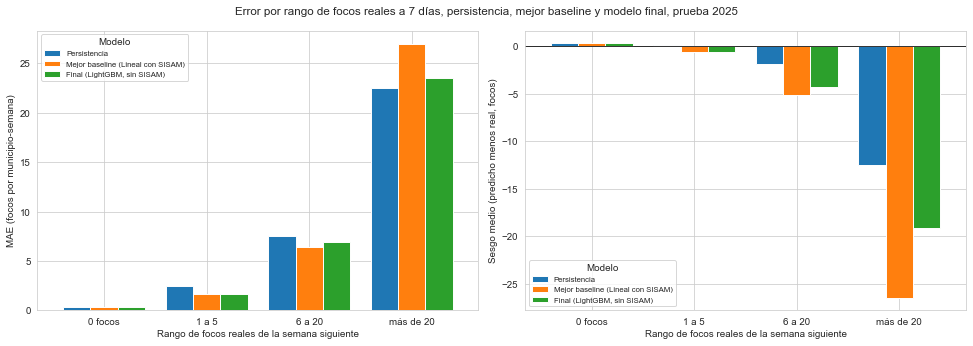

In [30]:
d7["rango"] = pd.cut(d7["real"], [-0.5, 0.5, 5.5, 20.5, np.inf], labels=["0 focos", "1 a 5", "6 a 20", "más de 20"])
filas = []
for k, etiqueta in MODELOS_7D.items():
    error = d7[k] - d7["real"]
    t = pd.DataFrame({"rango": d7["rango"], "e": error, "ea": error.abs()}).groupby("rango", observed=True).agg(filas=("e", "size"), MAE=("ea", "mean"), sesgo=("e", "mean")).reset_index()
    t["modelo"] = etiqueta
    filas.append(t)
error_rango = pd.concat(filas, ignore_index=True)
print("Error por rango de focos reales a 7 días, 2025:")
print(error_rango.pivot_table(index="rango", columns="modelo", values=["filas", "MAE", "sesgo"], observed=True).to_string(float_format=lambda v: f"{v:,.3f}"))

fig, ejes = plt.subplots(1, 2, figsize=(14, 5))
for eje, metrica, etiqueta in [(ejes[0], "MAE", "MAE (focos por municipio-semana)"), (ejes[1], "sesgo", "Sesgo medio (predicho menos real, focos)")]:
    error_rango.pivot_table(index="rango", columns="modelo", values=metrica, observed=True)[list(MODELOS_7D.values())].plot(kind="bar", ax=eje, width=0.8)
    eje.axhline(0, color="black", linewidth=0.8)
    eje.set_xlabel("Rango de focos reales de la semana siguiente")
    eje.set_ylabel(etiqueta)
    eje.legend(title="Modelo", fontsize=8)
    plt.setp(eje.get_xticklabels(), rotation=0)
fig.suptitle("Error por rango de focos reales a 7 días, persistencia, mejor baseline y modelo final, prueba 2025")
plt.tight_layout()
plt.show()


**Figura 4.** MAE y sesgo medio por rango de focos reales de la semana siguiente (0, 1 a 5, 6 a 20 y más de 20) para la persistencia, el mejor baseline y el modelo final. Prueba 2025.


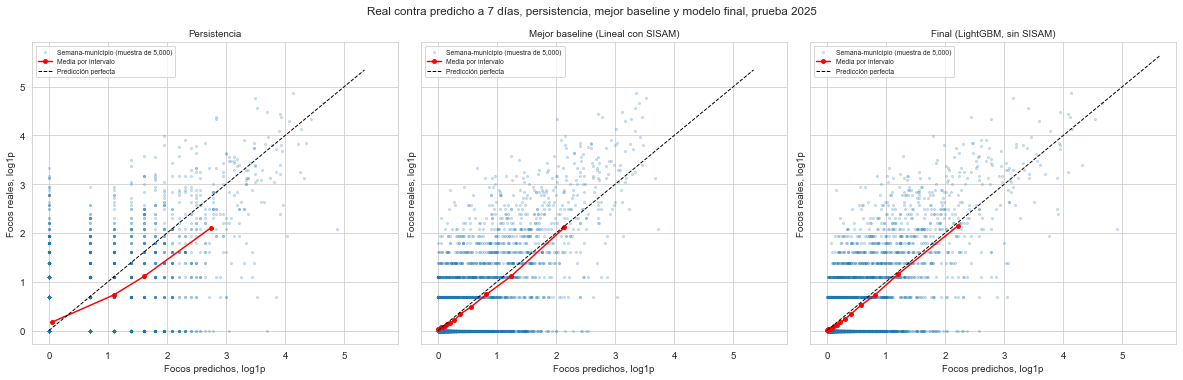

In [31]:
fig, ejes = plt.subplots(1, 3, figsize=(17, 5.5), sharex=True, sharey=True)
muestra = d7.sample(5000, random_state=SEMILLA)
for eje, (k, etiqueta) in zip(ejes, MODELOS_7D.items()):
    x, y = np.log1p(d7[k]), np.log1p(d7["real"])
    eje.scatter(np.log1p(muestra[k]), np.log1p(muestra["real"]), s=5, alpha=0.2, color="tab:blue", label="Semana-municipio (muestra de 5,000)")
    intervalos = pd.qcut(x, 15, duplicates="drop")
    medias = pd.DataFrame({"x": x, "y": y}).groupby(intervalos, observed=True).mean()
    eje.plot(medias["x"], medias["y"], color="red", marker="o", markersize=4, label="Media por intervalo")
    limite = max(x.max(), y.max())
    eje.plot([0, limite], [0, limite], color="black", linestyle="--", linewidth=1, label="Predicción perfecta")
    eje.set_title(etiqueta, fontsize=10)
    eje.set_xlabel("Focos predichos, log1p")
    eje.set_ylabel("Focos reales, log1p")
    eje.legend(fontsize=7, loc="upper left")
fig.suptitle("Real contra predicho a 7 días, persistencia, mejor baseline y modelo final, prueba 2025")
plt.tight_layout()
plt.show()


**Figura 5.** Dispersión de focos reales contra predichos (escala log1p) con la diagonal de predicción perfecta y la media por intervalos. Muestra de 5,000 filas de la prueba 2025.


In [32]:
def error_por(grupo):
    filas = []
    for k, etiqueta in MODELOS_7D.items():
        e = (d7[k] - d7["real"])
        t = pd.DataFrame({"g": d7[grupo], "ea": e.abs(), "e": e}).groupby("g").agg(filas=("e", "size"), MAE=("ea", "mean"), sesgo=("e", "mean"), error_total=("ea", "sum"))
        t["aporte_error_pct"] = t["error_total"] / t["error_total"].sum() * 100
        t["modelo"] = etiqueta
        filas.append(t.reset_index())
    return pd.concat(filas, ignore_index=True)


por_uf = error_por("uf")
por_temp = error_por("temporada")
print("Error por estado, 2025 (MAE y aporte al error total):")
print(por_uf.pivot_table(index="g", columns="modelo", values=["MAE", "aporte_error_pct"]).to_string(float_format=lambda v: f"{v:,.3f}"))
print("\nError por temporada de la semana objetivo, 2025:")
print(por_temp.pivot_table(index="g", columns="modelo", values=["MAE", "sesgo", "aporte_error_pct"]).to_string(float_format=lambda v: f"{v:,.3f}"))

e_final = (d7["final"] - d7["real"]).abs()
top = d7.assign(error_abs=e_final).groupby(["municipio_norm", "uf"]).agg(error_total=("error_abs", "sum"), focos_reales=("real", "sum"), MAE=("error_abs", "mean")).sort_values("error_total", ascending=False).head(10)
top["aporte_error_pct"] = top["error_total"] / e_final.sum() * 100
print("\n10 municipios con mayor error absoluto acumulado del modelo final, 2025:")
mostrar(top, 2)
print(f"\nLos 10 municipios principales aportan {top['aporte_error_pct'].sum():.1f} % del error absoluto.")
orden_e = e_final.sort_values(ascending=False)
print(f"El 1 % de las filas con mayor error aporta {orden_e.head(int(len(orden_e) * 0.01)).sum() / e_final.sum() * 100:.1f} % del error absoluto del modelo final.")


Error por estado, 2025 (MAE y aporte al error total):
                               MAE                                                           aporte_error_pct                                               
modelo Final (LightGBM, sin SISAM) Mejor baseline (Lineal con SISAM) Persistencia Final (LightGBM, sin SISAM) Mejor baseline (Lineal con SISAM) Persistencia
g                                                                                                                                                           
AC                           1.659                             1.738        2.111                       5.293                             5.437        5.892
AM                           1.408                             1.322        1.509                      12.655                            11.660       11.876
AP                           0.897                             0.936        1.025                       2.081                             2.130        2.080
MA  

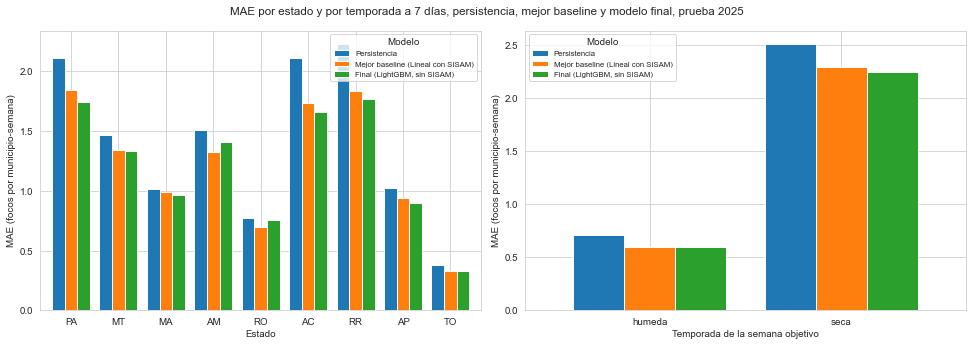

In [33]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 5))
t = por_uf.pivot_table(index="g", columns="modelo", values="MAE")[list(MODELOS_7D.values())]
t.loc[por_uf[por_uf["modelo"] == MODELOS_7D["final"]].sort_values("error_total", ascending=False)["g"]].plot(kind="bar", ax=ejes[0], width=0.8)
ejes[0].set_xlabel("Estado")
ejes[0].set_ylabel("MAE (focos por municipio-semana)")
ejes[0].legend(title="Modelo", fontsize=8)
t2_ = por_temp.pivot_table(index="g", columns="modelo", values="MAE")[list(MODELOS_7D.values())]
t2_.plot(kind="bar", ax=ejes[1], width=0.8)
ejes[1].set_xlabel("Temporada de la semana objetivo")
ejes[1].set_ylabel("MAE (focos por municipio-semana)")
ejes[1].legend(title="Modelo", fontsize=8)
for eje in ejes:
    plt.setp(eje.get_xticklabels(), rotation=0)
fig.suptitle("MAE por estado y por temporada a 7 días, persistencia, mejor baseline y modelo final, prueba 2025")
plt.tight_layout()
plt.show()


**Figura 6.** MAE por estado (izquierda) y por temporada de la semana objetivo (derecha) de la persistencia, el mejor baseline y el modelo final. Prueba 2025.


MAE móvil de 4 semanas en 2025, modelo final: mediana 0.801 | máximo 3.049
Semanas de 2025 con MAE móvil sobre 6.408: 0 de 48 (0.0 %)
Mejor baseline: mediana 0.847 | máximo 3.008 | semanas sobre el umbral: 0 (0.0 %)


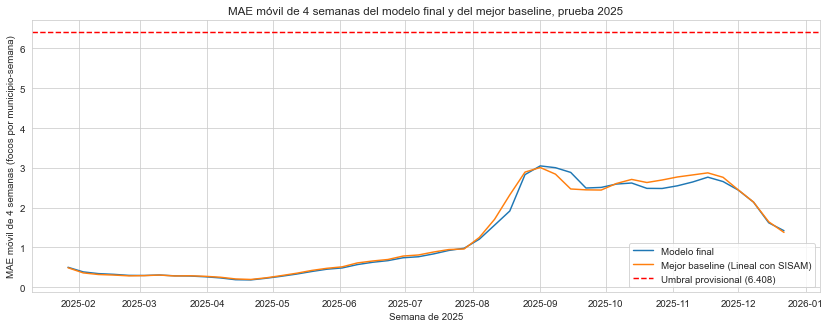

In [34]:
UMBRAL_MAE_MOVIL = 6.408      # umbrales provisionales del notebook baseline
UMBRAL_RECALL_ALERTA = 0.360
UMBRAL_FALSAS_ALARMAS = 0.026
d7["error_abs_final"] = e_final
mae_semanal = d7.groupby("semana")["error_abs_final"].mean().sort_index()
mae_semanal_base = (d7["lineal_con_sisam"] - d7["real"]).abs().groupby(d7["semana"]).mean().sort_index()
mae_movil = mae_semanal.rolling(4).mean().dropna()
mae_movil_base = mae_semanal_base.rolling(4).mean().dropna()
print(f"MAE móvil de 4 semanas en 2025, modelo final: mediana {mae_movil.median():.3f} | máximo {mae_movil.max():.3f}")
print(f"Semanas de 2025 con MAE móvil sobre {UMBRAL_MAE_MOVIL}: {(mae_movil > UMBRAL_MAE_MOVIL).sum()} de {len(mae_movil)} ({(mae_movil > UMBRAL_MAE_MOVIL).mean() * 100:.1f} %)")
print(f"Mejor baseline: mediana {mae_movil_base.median():.3f} | máximo {mae_movil_base.max():.3f} | semanas sobre el umbral: {(mae_movil_base > UMBRAL_MAE_MOVIL).sum()} ({(mae_movil_base > UMBRAL_MAE_MOVIL).mean() * 100:.1f} %)")

fig, ax = plt.subplots(figsize=(12, 4.8))
ax.plot(mae_movil.index, mae_movil.values, color="tab:blue", label="Modelo final")
ax.plot(mae_movil_base.index, mae_movil_base.values, color="tab:orange", label="Mejor baseline (Lineal con SISAM)")
ax.axhline(UMBRAL_MAE_MOVIL, color="red", linestyle="--", label=f"Umbral provisional ({UMBRAL_MAE_MOVIL})")
ax.set_xlabel("Semana de 2025")
ax.set_ylabel("MAE móvil de 4 semanas (focos por municipio-semana)")
ax.set_title("MAE móvil de 4 semanas del modelo final y del mejor baseline, prueba 2025")
ax.legend()
plt.tight_layout()
plt.show()


**Figura 7.** Serie semanal de 2025 del MAE móvil de 4 semanas del modelo final y del mejor baseline, con el umbral provisional del notebook base.


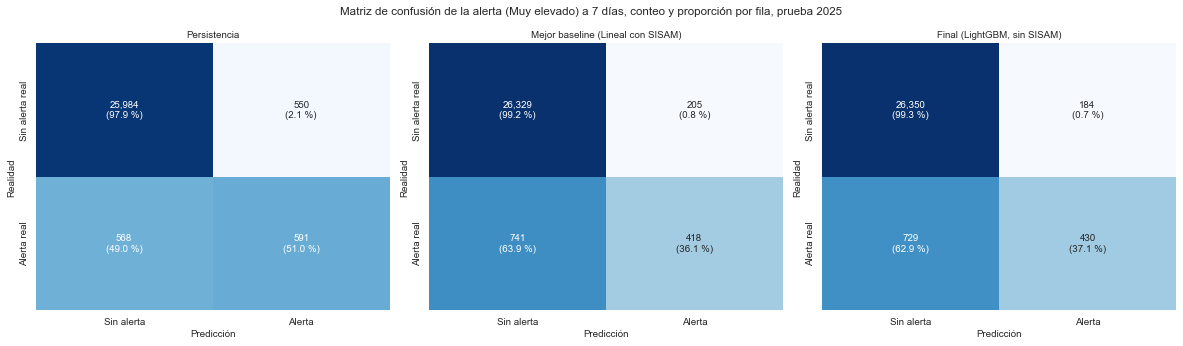

KPI de alerta en 2025 (VN, FP, FN, VP, recall, precisión, tasa de falsas alarmas):
Persistencia: VN 25,984 | FP 550 | FN 568 | VP 591 | recall 0.510 | precisión 0.518 | falsas alarmas 0.021
Mejor baseline (Lineal con SISAM): VN 26,329 | FP 205 | FN 741 | VP 418 | recall 0.361 | precisión 0.671 | falsas alarmas 0.008
Final (LightGBM, sin SISAM): VN 26,350 | FP 184 | FN 729 | VP 430 | recall 0.371 | precisión 0.700 | falsas alarmas 0.007


In [35]:
def matriz_alerta(real, pred, es_seca):
    umbral = np.where(np.asarray(es_seca) == 1, UMBRAL_SECA, UMBRAL_HUMEDA)
    r, p = np.asarray(real) > umbral, np.asarray(pred) > umbral
    return np.array([[(~r & ~p).sum(), (~r & p).sum()], [(r & ~p).sum(), (r & p).sum()]])


fig, ejes = plt.subplots(1, 3, figsize=(17, 5))
for eje, (k, etiqueta) in zip(ejes, MODELOS_7D.items()):
    conteos = matriz_alerta(d7["real"], d7[k], d7["objetivo_seca"])
    prop = conteos / conteos.sum(axis=1, keepdims=True)
    etiquetas = np.array([[f"{conteos[i, j]:,}\n({prop[i, j] * 100:.1f} %)" for j in range(2)] for i in range(2)])
    sns.heatmap(prop, annot=etiquetas, fmt="", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=eje, xticklabels=["Sin alerta", "Alerta"], yticklabels=["Sin alerta real", "Alerta real"])
    eje.set_title(etiqueta, fontsize=10)
    eje.set_xlabel("Predicción")
    eje.set_ylabel("Realidad")
fig.suptitle("Matriz de confusión de la alerta (Muy elevado) a 7 días, conteo y proporción por fila, prueba 2025")
plt.tight_layout()
plt.show()

print("KPI de alerta en 2025 (VN, FP, FN, VP, recall, precisión, tasa de falsas alarmas):")
for k, etiqueta in MODELOS_7D.items():
    (vn, fp), (fn, vp) = matriz_alerta(d7["real"], d7[k], d7["objetivo_seca"])
    print(f"{etiqueta}: VN {vn:,} | FP {fp:,} | FN {fn:,} | VP {vp:,} | recall {vp / (vp + fn):.3f} | precisión {vp / (vp + fp):.3f} | falsas alarmas {fp / (fp + vn):.3f}")


**Figura 8.** Matriz de confusión binaria de la alerta (nivel Muy elevado por temporada) para la persistencia, el mejor baseline y el modelo final. Prueba 2025.


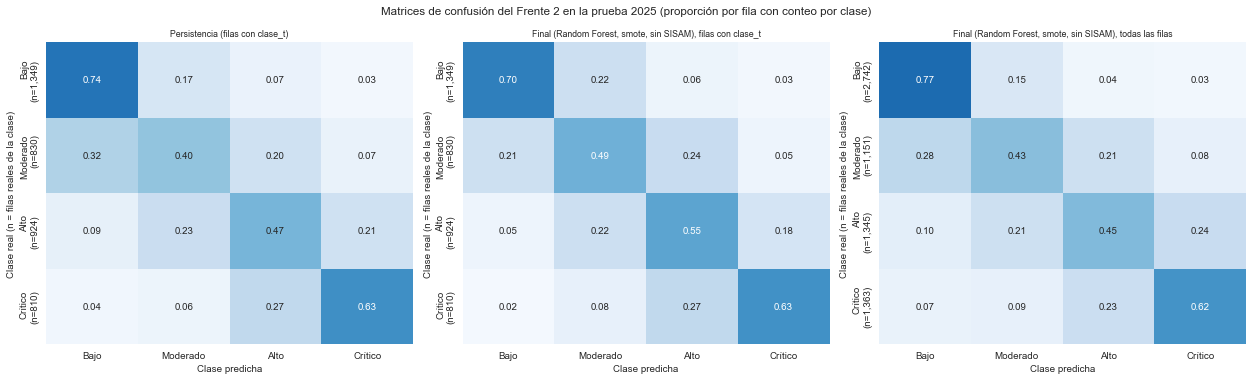

Errores del Frente 2 en 2025 (filas con clase_t para la persistencia; todas las filas para el final):
Persistencia (filas con clase_t): error ordinal medio 0.527 | errores 1,635 (41.8 %) | entre clases vecinas 78.4 % de los errores | a 2 o más clases 21.6 %
Final (Random Forest, smote, sin SISAM), filas con clase_t: error ordinal medio 0.487 | errores 1,556 (39.8 %) | entre clases vecinas 81.2 % de los errores | a 2 o más clases 18.8 %
Final (Random Forest, smote, sin SISAM), todas las filas: error ordinal medio 0.512 | errores 2,549 (38.6 %) | entre clases vecinas 74.7 % de los errores | a 2 o más clases 25.3 %


In [36]:
# Frente 2: matrices de confusion del modelo final en 2025 (proporcion por fila con conteo por clase) y errores entre clases vecinas
e2 = ELEGIDOS["f2"]
clave2 = ("f2", "ajustado", e2["modelo"], e2["tratamiento"], e2["sisam"])
te2, real2, pred2 = PRED_2025[clave2]
d2 = panel.loc[te2, ["semana", "municipio_norm", "uf", "clase_t_ord"]].copy()
d2["real"], d2["final"] = real2, pred2
d2["persistencia"] = d2["clase_t_ord"]
ETIQUETA_F2 = f"Final ({NOMBRES_MODELO[e2['modelo']]}, {e2['tratamiento']}, {e2['sisam']} SISAM)"


def matriz_f2(real, pred):
    m = confusion_matrix(np.asarray(real, int), np.asarray(pred, int), labels=[0, 1, 2, 3]).astype(float)
    return m, m / m.sum(axis=1, keepdims=True)


subconjuntos = [("Persistencia (filas con clase_t)", d2.dropna(subset=["clase_t_ord"]), "persistencia"), (f"{ETIQUETA_F2}, filas con clase_t", d2.dropna(subset=["clase_t_ord"]), "final"),
                (f"{ETIQUETA_F2}, todas las filas", d2, "final")]
fig, ejes = plt.subplots(1, 3, figsize=(18, 5.5))
for eje, (titulo, d, col) in zip(ejes, subconjuntos):
    m, prop = matriz_f2(d["real"], d[col])
    sns.heatmap(prop, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=eje, xticklabels=CLASES,
                yticklabels=[f"{c}\n(n={int(n):,})" for c, n in zip(CLASES, m.sum(axis=1))])
    eje.set_title(titulo, fontsize=9)
    eje.set_xlabel("Clase predicha")
    eje.set_ylabel("Clase real (n = filas reales de la clase)")
fig.suptitle("Matrices de confusión del Frente 2 en la prueba 2025 (proporción por fila con conteo por clase)")
plt.tight_layout()
plt.show()

print("Errores del Frente 2 en 2025 (filas con clase_t para la persistencia; todas las filas para el final):")
for titulo, d, col in subconjuntos:
    dif = (np.asarray(d["real"], float) - np.asarray(d[col], float))
    errores = dif != 0
    vecinas = (np.abs(dif) == 1).sum()
    print(f"{titulo}: error ordinal medio {np.abs(dif).mean():.3f} | errores {int(errores.sum()):,} ({errores.mean() * 100:.1f} %) | entre clases vecinas {vecinas / errores.sum() * 100:.1f} % de los errores | a 2 o más clases {(np.abs(dif) >= 2).sum() / errores.sum() * 100:.1f} %")


**Figura 9.** Matrices de confusión del Frente 2 de la persistencia (filas con clase de la semana actual) y del modelo final (con y sin esa restricción), con el número de filas reales por clase. Prueba 2025.


In [37]:
# lectura sencilla de los resultados del modelo elegido de cada tarea (importancia interna del modelo final, ajustado con todo el entrenamiento)
def principales_variables(modelo, columnas, filas_2025, n=5, tarea="f1"):
    # importancia interna del modelo y sentido: correlacion de Spearman entre la variable y la prediccion sobre las filas de 2025
    est = modelo.regressor_ if hasattr(modelo, "regressor_") else (modelo.named_steps["modelo"] if hasattr(modelo, "named_steps") else modelo)
    importancia = pd.Series(est.feature_importances_, index=columnas)
    top = (importancia / importancia.sum() * 100).sort_values(ascending=False).head(n)
    X = panel.loc[filas_2025, columnas]
    salida = modelo.predict_proba(X)[:, list(modelo.classes_).index(3)] if tarea == "f2" else modelo.predict(X)
    filas = []
    for variable, porcentaje in top.items():
        r = pd.Series(X[variable].to_numpy(float)).corr(pd.Series(np.asarray(salida, float)), method="spearman")
        filas.append((variable, porcentaje, r))
    return filas


def frase_sentido(r, destino):
    if np.isnan(r) or abs(r) < 0.05:
        return "sin una dirección clara"
    return f"al subir su valor, {'sube' if r > 0 else 'baja'} {destino}"


print("LECTURA SENCILLA DE LOS RESULTADOS DEL MODELO ELEGIDO (variables según la importancia interna del modelo; el sentido se mide sobre las filas de 2025, sin usarlas para decidir)")
for tarea, titulo, destino in [("f1_7d", "Frente 1 a 7 días", "la predicción de focos"), ("f1_30d", "Frente 1 a 30 días", "la predicción de focos"), ("f2", "Frente 2", "la probabilidad de clase Crítico")]:
    e = ELEGIDOS[tarea]
    clave = (tarea, "ajustado", e["modelo"], e["tratamiento"] if tarea == "f2" else "no aplica", e["sisam"])
    columnas = LISTAS[frente_de(tarea)][e["sisam"]]
    print(f"\n{titulo}: {NOMBRES_MODELO[e['modelo']]}" + (f" con {e['tratamiento']}" if tarea == "f2" else "") + f", {e['sisam']} SISAM. Las 5 variables que más influyen:")
    for i, (variable, porcentaje, r) in enumerate(principales_variables(MODELOS_AJUSTADOS[clave], columnas, filas_validas(tarea, idx_prueba), tarea=tarea), start=1):
        print(f"  {i}. {variable} ({porcentaje:.1f} % de la importancia): {frase_sentido(r, destino)} (correlación {r:+.2f}).")
    if tarea == "f2":
        for subconjunto in ["con_clase_t"]:
            a, s = valor_cv("f2", subconjunto, "F1_macro", e["modelo"], "ajustado", e["tratamiento"], e["sisam"])
            b, t = valor_cv("f2", subconjunto, "recall_critico", e["modelo"], "ajustado", e["tratamiento"], e["sisam"])
            print(f"  Métricas clave: F1 macro {a:.3f} (desviación {s:.3f}) y recall de Crítico {b:.3f} (desviación {t:.3f}) en validación; en 2025, {valor_2025('f2', subconjunto, 'F1_macro', e['modelo'], 'ajustado', e['tratamiento'], e['sisam']):.3f} y {valor_2025('f2', subconjunto, 'recall_critico', e['modelo'], 'ajustado', e['tratamiento'], e['sisam']):.3f}.")
    else:
        a, s = valor_cv(tarea, "todas", "MAE", e["modelo"], "ajustado", "no aplica", e["sisam"])
        print(f"  Métricas clave: MAE {a:.3f} (desviación {s:.3f}) en validación y {valor_2025(tarea, 'todas', 'MAE', e['modelo'], 'ajustado', 'no aplica', e['sisam']):.3f} en 2025; R2 en log1p {valor_cv(tarea, 'todas', 'R2_log1p', e['modelo'], 'ajustado', 'no aplica', e['sisam'])[0]:.3f} en validación.")


LECTURA SENCILLA DE LOS RESULTADOS DEL MODELO ELEGIDO (variables según la importancia interna del modelo; el sentido se mide sobre las filas de 2025, sin usarlas para decidir)

Frente 1 a 7 días: LightGBM, sin SISAM. Las 5 variables que más influyen:
  1. lon (6.6 % de la importancia): al subir su valor, baja la predicción de focos (correlación -0.14).
  2. lat (6.5 % de la importancia): al subir su valor, baja la predicción de focos (correlación -0.08).
  3. sem_anio_cos (6.0 % de la importancia): sin una dirección clara (correlación -0.05).
  4. sem_anio_sin (5.8 % de la importancia): al subir su valor, baja la predicción de focos (correlación -0.64).
  5. num_incendios_mm4 (4.5 % de la importancia): al subir su valor, sube la predicción de focos (correlación +0.84).
  Métricas clave: MAE 3.001 (desviación 2.786) en validación y 1.270 en 2025; R2 en log1p 0.589 en validación.

Frente 1 a 30 días: XGBoost, con SISAM. Las 5 variables que más influyen:
  1. num_incendios_mm4 (28.4 % de 

  1. riesgo_fuego_t (27.8 % de la importancia): al subir su valor, sube la probabilidad de clase Crítico (correlación +0.64).
  2. precip_acum_30d (20.1 % de la importancia): al subir su valor, baja la probabilidad de clase Crítico (correlación -0.78).
  3. precip_nasa_sem (7.3 % de la importancia): al subir su valor, baja la probabilidad de clase Crítico (correlación -0.66).
  4. precip_acum_30d_rez4 (3.9 % de la importancia): al subir su valor, baja la probabilidad de clase Crítico (correlación -0.63).
  5. lon (3.9 % de la importancia): al subir su valor, sube la probabilidad de clase Crítico (correlación +0.37).
  Métricas clave: F1 macro 0.572 (desviación 0.062) y recall de Crítico 0.503 (desviación 0.290) en validación; en 2025, 0.591 y 0.627.


### Hallazgos de esta etapa

**Qué se observa**
- **A 7 días en 2025**, el MAE es **1.270** (final), **1.295** (mejor baseline) y **1.451** (persistencia). Por rango de focos reales (ver Figura 4): con 0 focos **0.309**; con 1 a 5, **1.630** (baseline **1.636**, persistencia **2.495**); con 6 a 20, **6.935** (el baseline es mejor: **6.418**); y con más de 20, **23.502** (baseline **26.975**, persistencia **22.496**). En ese último rango el sesgo es **-19.146** (baseline **-26.481**).
- **Por estado** (ver Figura 6): Pará aporta **36.400 %** del error (MAE **1.743**), Mato Grosso **17.381 %** y Maranhão **14.979 %**. En `AM` y `RO` el baseline es algo mejor (**1.322** frente a **1.408**, y **0.700** frente a **0.755**).
- **Por temporada:** la seca aporta **72.563 %** del error (MAE **2.238**), frente a un MAE de **0.592** en la húmeda.
- Los 10 municipios con mayor error aportan **12.8 %** (el primero, `COLNIZA`, con **815.02** de error acumulado), y el **1 %** de las filas con mayor error aporta **27.6 %**.
- **MAE móvil de 4 semanas** (ver Figura 7): mediana **0.801** y máximo **3.049**; **0** de **48** semanas pasan el umbral provisional de **6.408**.
- **Alerta en 2025** (ver Figura 8): el modelo final tiene recall **0.371**, precisión **0.700** y falsas alarmas **0.007**; el baseline **0.361**, **0.671** y **0.008**; y la persistencia **0.510**, **0.518** y **0.021**.
- **Frente 2** (ver Figura 9): el error ordinal del modelo final es **0.487** (persistencia **0.527**) en las filas con clase de la semana actual, y **81.2 %** de sus errores son entre clases vecinas (persistencia **78.4 %**).

**Por qué importa**
- Los picos siguen subestimándose: en el rango de más de 20 focos el sesgo es de **-19.146**. El error está concentrado en la temporada seca y en pocas semanas extremas, no en pocos municipios.
- La persistencia detecta más alertas (**0.510** frente a **0.371**) a costa de más falsas alarmas.

**Qué implica para el modelado**
- El umbral de alerta se puede bajar para ganar recall si el costo de una falsa alarma lo permite.
- **Limitación:** este análisis usa las predicciones de 2025 ya calculadas; no se usó para elegir ni ajustar nada.


## 7b. Calibración del punto de operación de la alerta a 7 días

**Problema.** Con el umbral de Muy elevado por temporada (húmeda 5, seca 12 focos por municipio-semana), el modelo final a 7 días detecta menos alertas reales que la persistencia. El modelo se entrena para minimizar el error promedio y se queda corto en los picos, así que predice por debajo del umbral aun cuando la semana siguiente lo supera.

**Qué se hace.** Se multiplica la predicción por un factor `k` y se declara alerta si `k × predicción > umbral de la temporada`. Las predicciones fuera de muestra se obtienen **reajustando el modelo final** (mismos parámetros y misma lista de variables) en cada uno de los 4 folds, con las mismas filas de entrenamiento y el mismo margen de 4 semanas del resto del notebook.

**Regla de elección (solo validación):** el `k` más bajo cuyo recall de alerta de validación (promedio de los 4 folds) iguale o supere el de la persistencia en validación. Si ningún `k` entre 1.0 y 3.0 (pasos de 0.1) lo logra, se elige el que mejor balancee recall y precisión (mayor F1 de la alerta) y se explica. **2025 no interviene en la elección**: se reporta una sola vez, después, con el `k` ya fijado. El factor `k` no cambia el MAE ni ningún otro resultado: solo mueve el punto de operación de la alerta.


In [38]:
# predicciones fuera de muestra de los 4 folds del modelo final a 7 dias (mismas filas de entrenamiento y margen que el resto del notebook)
e7 = ELEGIDOS["f1_7d"]
cols7 = LISTAS["f1"][e7["sisam"]]
params7 = PARAMS_AJUSTADOS["f1_7d"][e7["modelo"]]
OOF = []
for f in FOLDS:
    tr, va = filas_validas("f1_7d", f["idx_entreno"]), filas_validas("f1_7d", f["idx_valid"])
    modelo_fold = crear_f1(e7["modelo"], params7).fit(panel.loc[tr, cols7], panel.loc[tr, "y_7d"])
    OOF.append(pd.DataFrame({"fold": f["fold"], "real": panel.loc[va, "y_7d"].to_numpy(float), "pred": modelo_fold.predict(panel.loc[va, cols7]),
                             "pers": panel.loc[va, "num_incendios_crudo"].to_numpy(float),
                             "umbral": np.where(panel.loc[va, "objetivo_seca"].to_numpy() == 1, UMBRAL_SECA, UMBRAL_HUMEDA)}))
OOF = pd.concat(OOF, ignore_index=True)
# comprobacion: son las mismas predicciones de la evaluacion de la seccion 4 (mismo MAE y mismo recall de alerta por fold)
for f in FOLDS:
    d = OOF[OOF["fold"] == f["fold"]]
    ref = res[(res["frente"] == "f1_7d") & (res["modelo"] == e7["modelo"]) & (res["variante"] == "ajustado") & (res["sisam"] == e7["sisam"]) & (res["evaluacion"] == "cv_fold") & (res["fold"] == f["fold"])]
    assert np.isclose(np.abs(d["pred"] - d["real"]).mean(), ref[ref["metrica"] == "MAE"]["valor"].iloc[0]), "las predicciones del fold no coinciden con la seccion 4"
    assert np.isclose(((d["pred"] > d["umbral"]) & (d["real"] > d["umbral"])).sum() / (d["real"] > d["umbral"]).sum(), ref[ref["metrica"] == "recall_alerta"]["valor"].iloc[0])
print(f"Predicciones fuera de muestra de {NOMBRES_MODELO[e7['modelo']]} ({e7['sisam']} SISAM, {len(cols7)} variables): {len(OOF):,} filas en {OOF['fold'].nunique()} folds.")
print("Verificado: coinciden con la evaluación por fold de la sección 4 (mismo MAE y mismo recall de alerta con k = 1).")


def metricas_k(real, puntaje, umbral):
    # recall, precision y tasa de falsas alarmas de la alerta (puntaje > umbral) frente a la alerta real (real > umbral)
    r, p = real > umbral, puntaje > umbral
    tp, fp, fn, tn = (r & p).sum(), (~r & p).sum(), (r & ~p).sum(), (~r & ~p).sum()
    return {"recall": tp / (tp + fn) if tp + fn else np.nan, "precision": tp / (tp + fp) if tp + fp else np.nan, "falsas_alarmas": fp / (fp + tn) if fp + tn else np.nan,
            "tp": int(tp), "fp": int(fp), "fn": int(fn), "tn": int(tn)}


def barrido(k):
    # metricas por fold y con los 4 folds juntos para un factor k (k = None: persistencia)
    por_fold = []
    for f in FOLDS:
        d = OOF[OOF["fold"] == f["fold"]]
        por_fold.append(metricas_k(d["real"].to_numpy(), d["pers"].to_numpy() if k is None else k * d["pred"].to_numpy(), d["umbral"].to_numpy()))
    juntos = metricas_k(OOF["real"].to_numpy(), OOF["pers"].to_numpy() if k is None else k * OOF["pred"].to_numpy(), OOF["umbral"].to_numpy())
    return por_fold, juntos


def fila_k(k):
    por_fold, juntos = barrido(k)
    f = pd.DataFrame(por_fold)
    return {"k": k, "recall_media": f["recall"].mean(), "recall_desv": f["recall"].std(), "precision_media": f["precision"].mean(), "precision_desv": f["precision"].std(),
            "falsas_alarmas_media": f["falsas_alarmas"].mean(), "falsas_alarmas_desv": f["falsas_alarmas"].std(),
            "recall_conjunto": juntos["recall"], "precision_conjunta": juntos["precision"], "falsas_alarmas_conjunto": juntos["falsas_alarmas"],
            **{f"recall_fold{i + 1}": v for i, v in enumerate(f["recall"])}, **{f"falsas_alarmas_fold{i + 1}": v for i, v in enumerate(f["falsas_alarmas"])}}


KS = np.round(np.arange(1.0, 3.0001, 0.1), 1)
TABLA_K = pd.DataFrame([fila_k(k) for k in KS])
PERS_VAL = fila_k(None)
assert np.isclose(TABLA_K.loc[TABLA_K["k"] == 1.0, "recall_media"].iloc[0], valor_cv("f1_7d", "todas", "recall_alerta", e7["modelo"], "ajustado", "no aplica", e7["sisam"])[0])
TABLA_K["f1_alerta_media"] = 2 * TABLA_K["recall_media"] * TABLA_K["precision_media"] / (TABLA_K["recall_media"] + TABLA_K["precision_media"])
alcanzan = TABLA_K[TABLA_K["recall_media"] >= PERS_VAL["recall_media"]]
if len(alcanzan):
    K_ELEGIDO, REGLA = float(alcanzan["k"].min()), "el k mas bajo cuyo recall de validacion (promedio de 4 folds) iguala o supera el de la persistencia en validacion"
else:
    K_ELEGIDO, REGLA = float(TABLA_K.loc[TABLA_K["f1_alerta_media"].idxmax(), "k"]), "ningun k entre 1.0 y 3.0 iguala el recall de la persistencia en validacion; se elige el k con mayor F1 de la alerta en validacion"
VAL_K = TABLA_K[TABLA_K["k"] == K_ELEGIDO].iloc[0]
print(f"\nPersistencia en validación (promedio de 4 folds): recall {PERS_VAL['recall_media']:.3f}, precisión {PERS_VAL['precision_media']:.3f}, falsas alarmas {PERS_VAL['falsas_alarmas_media']:.4f}")
print("\nBarrido del factor k en validación (promedio de los 4 folds; a la derecha, los 4 folds juntos):")
mostrar_k = TABLA_K[((TABLA_K["k"] * 10).round().astype(int) % 2 == 0) | (TABLA_K["k"] == K_ELEGIDO)][["k", "recall_media", "recall_desv", "precision_media", "falsas_alarmas_media", "recall_conjunto", "precision_conjunta", "falsas_alarmas_conjunto"]]
print(mostrar_k.to_string(index=False, float_format=lambda v: f"{v:.3f}"))
print(f"\nRegla: {REGLA}.")
print(f"k elegido = {K_ELEGIDO:.1f}: recall {VAL_K['recall_media']:.3f} (desviación {VAL_K['recall_desv']:.3f}), precisión {VAL_K['precision_media']:.3f}, falsas alarmas {VAL_K['falsas_alarmas_media']:.4f} (desviación {VAL_K['falsas_alarmas_desv']:.4f}).")
print("Recall por fold con k elegido:", [round(VAL_K[f'recall_fold{i}'], 3) for i in range(1, 5)], "| persistencia:", [round(PERS_VAL[f'recall_fold{i}'], 3) for i in range(1, 5)])


Predicciones fuera de muestra de LightGBM (sin SISAM, 37 variables): 54,843 filas en 4 folds.
Verificado: coinciden con la evaluación por fold de la sección 4 (mismo MAE y mismo recall de alerta con k = 1).

Persistencia en validación (promedio de 4 folds): recall 0.579, precisión 0.591, falsas alarmas 0.0333

Barrido del factor k en validación (promedio de los 4 folds; a la derecha, los 4 folds juntos):
    k  recall_media  recall_desv  precision_media  falsas_alarmas_media  recall_conjunto  precision_conjunta  falsas_alarmas_conjunto
1.000         0.479        0.100            0.765                 0.014            0.525               0.777                    0.013
1.200         0.531        0.109            0.719                 0.019            0.581               0.735                    0.018
1.400         0.581        0.104            0.684                 0.024            0.629               0.701                    0.023
1.600         0.617        0.104            0.651       

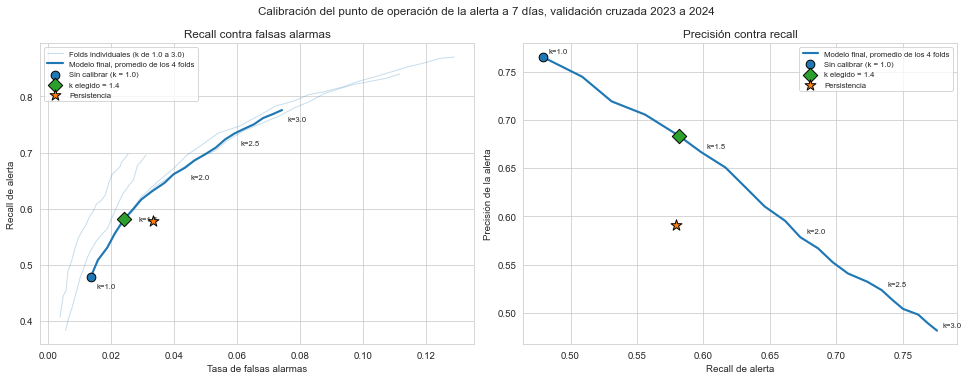

In [39]:
# curva del factor k en validacion: recall contra falsas alarmas y precision contra recall (persistencia como referencia)
fig, ejes = plt.subplots(1, 2, figsize=(14, 5.5))
for i in range(1, 5):
    ejes[0].plot(TABLA_K[f"falsas_alarmas_fold{i}"], TABLA_K[f"recall_fold{i}"], color="tab:blue", alpha=0.25, linewidth=1, label="Folds individuales (k de 1.0 a 3.0)" if i == 1 else None)
ejes[0].plot(TABLA_K["falsas_alarmas_media"], TABLA_K["recall_media"], color="tab:blue", linewidth=2.2, label="Modelo final, promedio de los 4 folds")
ejes[1].plot(TABLA_K["recall_media"], TABLA_K["precision_media"], color="tab:blue", linewidth=2.2, label="Modelo final, promedio de los 4 folds")
for k_etiqueta in [1.0, 1.5, 2.0, 2.5, 3.0]:
    f_ = TABLA_K[TABLA_K["k"] == k_etiqueta].iloc[0]
    ejes[0].annotate(f"k={k_etiqueta:.1f}", (f_["falsas_alarmas_media"], f_["recall_media"]), textcoords="offset points", xytext=(6, -12), fontsize=8)
    ejes[1].annotate(f"k={k_etiqueta:.1f}", (f_["recall_media"], f_["precision_media"]), textcoords="offset points", xytext=(6, 4), fontsize=8)
for eje, (fx, fy) in zip(ejes, [("falsas_alarmas_media", "recall_media"), ("recall_media", "precision_media")]):
    sin_cal, elegido = TABLA_K[TABLA_K["k"] == 1.0].iloc[0], VAL_K
    eje.scatter([sin_cal[fx]], [sin_cal[fy]], color="tab:blue", edgecolor="black", s=80, zorder=4, label="Sin calibrar (k = 1.0)")
    eje.scatter([elegido[fx]], [elegido[fy]], color="tab:green", edgecolor="black", s=110, marker="D", zorder=5, label=f"k elegido = {K_ELEGIDO:.1f}")
    eje.scatter([PERS_VAL[fx]], [PERS_VAL[fy]], color="tab:orange", edgecolor="black", s=140, marker="*", zorder=5, label="Persistencia")
ejes[0].set_xlabel("Tasa de falsas alarmas")
ejes[0].set_ylabel("Recall de alerta")
ejes[0].set_title("Recall contra falsas alarmas")
ejes[1].set_xlabel("Recall de alerta")
ejes[1].set_ylabel("Precisión de la alerta")
ejes[1].set_title("Precisión contra recall")
for eje in ejes:
    eje.legend(loc="best", fontsize=8)
fig.suptitle("Calibración del punto de operación de la alerta a 7 días, validación cruzada 2023 a 2024")
plt.tight_layout()
plt.show()


**Figura 10.** Curvas del factor k sobre la predicción a 7 días en la validación (4 folds): recall contra tasa de falsas alarmas (izquierda) y precisión contra recall (derecha), con el modelo sin calibrar (k = 1.0), el k elegido y la persistencia como referencia. Las líneas tenues son los folds individuales.


In [40]:
# UNICA lectura en 2025 con el k ya fijado en validacion: modelo calibrado, sin calibrar y persistencia
te7_, real7_, pred7_ = PRED_2025[("f1_7d", "ajustado", e7["modelo"], "no aplica", e7["sisam"])]
d25 = pd.DataFrame({"real": real7_, "pred": pred7_, "pers": panel.loc[te7_, "num_incendios_crudo"].to_numpy(float),
                    "umbral": np.where(panel.loc[te7_, "objetivo_seca"].to_numpy() == 1, UMBRAL_SECA, UMBRAL_HUMEDA)})
semanas_2025 = panel.loc[te7_, "semana"].nunique()
M25 = {"calibrado": metricas_k(d25["real"].to_numpy(), K_ELEGIDO * d25["pred"].to_numpy(), d25["umbral"].to_numpy()),
       "sin_calibrar": metricas_k(d25["real"].to_numpy(), d25["pred"].to_numpy(), d25["umbral"].to_numpy()),
       "persistencia": metricas_k(d25["real"].to_numpy(), d25["pers"].to_numpy(), d25["umbral"].to_numpy())}
assert np.isclose(M25["sin_calibrar"]["recall"], valor_2025("f1_7d", "todas", "recall_alerta", e7["modelo"], "ajustado", "no aplica", e7["sisam"]))
VALIDACION_K = {"calibrado": {"recall": VAL_K["recall_media"], "precision": VAL_K["precision_media"], "falsas_alarmas": VAL_K["falsas_alarmas_media"]},
                "sin_calibrar": {c: TABLA_K[TABLA_K["k"] == 1.0].iloc[0][c + "_media"] for c in ["recall", "precision", "falsas_alarmas"]},
                "persistencia": {"recall": PERS_VAL["recall_media"], "precision": PERS_VAL["precision_media"], "falsas_alarmas": PERS_VAL["falsas_alarmas_media"]}}
tabla_alerta = pd.DataFrame({f"{n} ({ev})": [(VALIDACION_K if ev == "validación" else M25)[c][m] for m in ["recall", "precision", "falsas_alarmas"]]
                             for ev in ["validación", "2025"] for n, c in [("modelo calibrado", "calibrado"), ("modelo sin calibrar", "sin_calibrar"), ("persistencia", "persistencia")]},
                            index=["recall", "precisión", "falsas alarmas (tasa)"])
print(f"Alerta a 7 días con k = {K_ELEGIDO:.1f} (validación: promedio de 4 folds; 2025: una sola lectura, {len(d25):,} filas y {semanas_2025} semanas):")
print(tabla_alerta.to_string(float_format=lambda v: f"{v:.4f}"))
print("\nConteos de 2025 (alertas reales:", M25["calibrado"]["tp"] + M25["calibrado"]["fn"], "):")
for n in ["calibrado", "sin_calibrar", "persistencia"]:
    print(f"  {n}: alertas detectadas {M25[n]['tp']}, alertas perdidas {M25[n]['fn']}, falsas alarmas {M25[n]['fp']} ({M25[n]['fp'] / semanas_2025:.2f} por semana)")
ADICIONALES_SEMANA = (M25["calibrado"]["fp"] - M25["sin_calibrar"]["fp"]) / semanas_2025
DETECTADAS_SEMANA = (M25["calibrado"]["tp"] - M25["sin_calibrar"]["tp"]) / semanas_2025
print(f"\nCosto de calibrar en 2025: {ADICIONALES_SEMANA:.2f} falsas alarmas adicionales por semana (de {M25['sin_calibrar']['fp'] / semanas_2025:.2f} a {M25['calibrado']['fp'] / semanas_2025:.2f}) "
      f"a cambio de {DETECTADAS_SEMANA:.2f} alertas reales más detectadas por semana.")
print(f"Frente a la persistencia: {(M25['calibrado']['fp'] - M25['persistencia']['fp']) / semanas_2025:+.2f} falsas alarmas por semana y {(M25['calibrado']['tp'] - M25['persistencia']['tp']) / semanas_2025:+.2f} alertas detectadas por semana.")
ALERTA = {"factor_k": K_ELEGIDO, "umbral_seca": UMBRAL_SECA, "umbral_humeda": UMBRAL_HUMEDA, "regla_de_eleccion": REGLA,
          "definicion": "alerta si factor_k x focos predichos superan el p75 de la temporada de la semana objetivo",
          "rango_probado": [float(KS.min()), float(KS.max()), 0.1],
          "metricas_validacion": {n: {m: float(v) for m, v in c.items()} for n, c in VALIDACION_K.items()},
          "metricas_2025": {n: {**{m: float(c[m]) for m in ["recall", "precision", "falsas_alarmas"]}, "falsas_alarmas_por_semana": float(c["fp"] / semanas_2025)} for n, c in M25.items()},
          "falsas_alarmas_adicionales_por_semana_2025": float(ADICIONALES_SEMANA), "alertas_adicionales_detectadas_por_semana_2025": float(DETECTADAS_SEMANA)}


Alerta a 7 días con k = 1.4 (validación: promedio de 4 folds; 2025: una sola lectura, 27,693 filas y 51 semanas):
                       modelo calibrado (validación)  modelo sin calibrar (validación)  persistencia (validación)  modelo calibrado (2025)  modelo sin calibrar (2025)  persistencia (2025)
recall                                        0.5815                            0.4791                     0.5791                   0.4944                      0.3710               0.5099
precisión                                     0.6835                            0.7651                     0.5908                   0.6006                      0.7003               0.5180
falsas alarmas (tasa)                         0.0241                            0.0136                     0.0333                   0.0144                      0.0069               0.0207

Conteos de 2025 (alertas reales: 1159 ):
  calibrado: alertas detectadas 573, alertas perdidas 586, falsas alarmas 381 (7.47 por sema

### Hallazgos de esta etapa

**Qué se observa**
- **Persistencia en validación** (promedio de 4 folds): recall **0.579**, precisión **0.591** y tasa de falsas alarmas **0.0333**. El modelo final **sin calibrar** (k = 1.0) llega a recall **0.479**, precisión **0.765** y falsas alarmas **0.0136**.
- **Barrido de k** (ver Figura 10): el recall de validación sube de **0.531** con k = 1.2 a **0.581** con k = 1.4, mientras la precisión baja de **0.719** a **0.684** y las falsas alarmas suben de **0.019** a **0.024**.
- **k elegido = 1.4**, el más bajo cuyo recall de validación iguala al de la persistencia (**0.581** frente a **0.579**), con precisión **0.684** y falsas alarmas **0.0241** (desviación **0.0180**). Por fold, el recall es **0.509**, **0.641**, **0.479** y **0.696**, frente a **0.512**, **0.642**, **0.503** y **0.659** de la persistencia: la iguala en promedio, no en cada fold.
- **Una sola lectura en 2025** con k = 1.4: recall **0.494**, precisión **0.601** y falsas alarmas **0.0144**; sin calibrar, **0.371**, **0.700** y **0.0069**; persistencia, **0.510**, **0.518** y **0.0207**. De **1,159** alertas reales, el modelo calibrado detecta **573**, el modelo sin calibrar **430** y la persistencia **591**.
- **Costo:** **3.86** falsas alarmas adicionales por semana (de **3.61** a **7.47**, sobre **51** semanas) a cambio de **2.80** alertas reales más detectadas por semana. Frente a la persistencia, **3.31** falsas alarmas menos por semana (**7.47** frente a **10.78**) y **0.35** alertas menos detectadas por semana.

**Por qué importa**
- El modelo entrenado para minimizar el error promedio se queda corto en los picos; multiplicar su predicción por un factor mueve el punto de operación sin reentrenar y sin cambiar el MAE.
- La calibración recupera gran parte del recall perdido (de **0.371** a **0.494** en 2025) con menos falsas alarmas que la persistencia, pero no alcanza su recall en 2025 (**0.494** frente a **0.510**).

**Qué implica para el modelado**
- El backend debe aplicar `factor_k` = **1.4** sobre la predicción a 7 días solo para la alerta; el MAE y el valor predicho siguen siendo los del modelo.
- **Limitación:** el recall varía mucho entre folds (de **0.479** a **0.696** con el k elegido) y el k se eligió con 2023 y 2024; conviene revisarlo si cambia el régimen de focos.


## 8. Interpretabilidad

Para interpretar el modelo **fuera de muestra** se usa el modelo final reajustado con las filas de entrenamiento del **fold 4** (hasta 2024-05-27) y las filas de validación de ese fold (2024 S2). Se calculan la **importancia por permutación** (top 15) y los valores **SHAP** sobre una muestra de 5,000 filas de validación. No se usa 2025. En el Frente 1 los valores SHAP explican la predicción en escala `log1p`.


Modelo a 7 días: LightGBM; entrenado con 66,246 filas (hasta 2024-05-27), validado con 12,489 filas (2024 S2).
MAE del fold 4 de este modelo: 6.265



Importancia por permutación (aumento del MAE al barajar cada variable), top 15:
                      aumento_MAE  desv
variable                               
num_incendios_mm4           2.582 0.033
num_incendios               2.138 0.012
sem_anio_cos                1.107 0.031
num_incendios_rez1          0.444 0.014
num_incendios_rez2          0.160 0.018
lon                         0.149 0.021
lat                         0.129 0.011
dias_sin_lluvia_nasa        0.122 0.014
precip_acum_30d             0.073 0.011
WS2M                        0.064 0.011
num_incendios_rez3          0.053 0.002
precip_acum_30d_rez4        0.035 0.006
num_incendios_rez4          0.030 0.004
uf_PA                       0.029 0.006
precip_nasa_sem             0.024 0.005


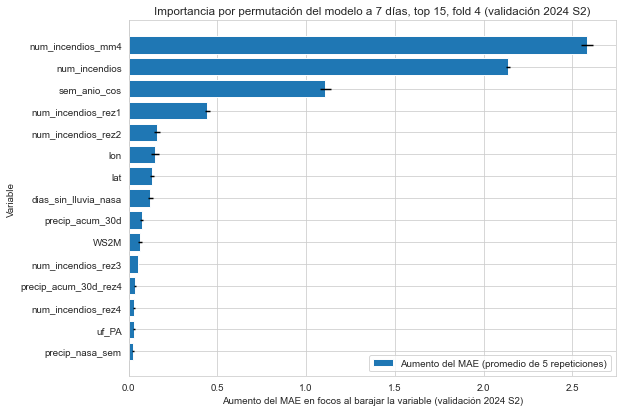

In [41]:
f4 = FOLDS[3]
t7 = ELEGIDOS["f1_7d"]
col7 = LISTAS["f1"][t7["sisam"]]
tr4, va4 = filas_validas("f1_7d", f4["idx_entreno"]), filas_validas("f1_7d", f4["idx_valid"])
modelo7 = crear_f1(t7["modelo"], PARAMS_AJUSTADOS["f1_7d"][t7["modelo"]]).fit(panel.loc[tr4, col7], panel.loc[tr4, "y_7d"])
Xv, yv = panel.loc[va4, col7], panel.loc[va4, "y_7d"]
print(f"Modelo a 7 días: {NOMBRES_MODELO[t7['modelo']]}; entrenado con {len(tr4):,} filas (hasta {f4['entreno'][1].date()}), validado con {len(va4):,} filas (2024 S2).")
print("MAE del fold 4 de este modelo:", f"{float(np.abs(modelo7.predict(Xv) - yv).mean()):.3f}")

perm = permutation_importance(modelo7, Xv, yv, n_repeats=5, random_state=SEMILLA, scoring="neg_mean_absolute_error", n_jobs=-1)
importancia = pd.DataFrame({"variable": col7, "aumento_MAE": perm.importances_mean, "desv": perm.importances_std}).sort_values("aumento_MAE", ascending=False).head(15)
print("\nImportancia por permutación (aumento del MAE al barajar cada variable), top 15:")
mostrar(importancia.set_index("variable"), 3)

fig, ax = plt.subplots(figsize=(9, 6))
d = importancia.sort_values("aumento_MAE")
ax.barh(d["variable"], d["aumento_MAE"], xerr=d["desv"], color="tab:blue", label="Aumento del MAE (promedio de 5 repeticiones)")
ax.set_xlabel("Aumento del MAE en focos al barajar la variable (validación 2024 S2)")
ax.set_ylabel("Variable")
ax.set_title("Importancia por permutación del modelo a 7 días, top 15, fold 4 (validación 2024 S2)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()


**Figura 11.** Aumento del MAE al barajar cada variable en las 15 variables más importantes del modelo a 7 días, calculado con el modelo del fold 4 sobre su validación (2024 S2).


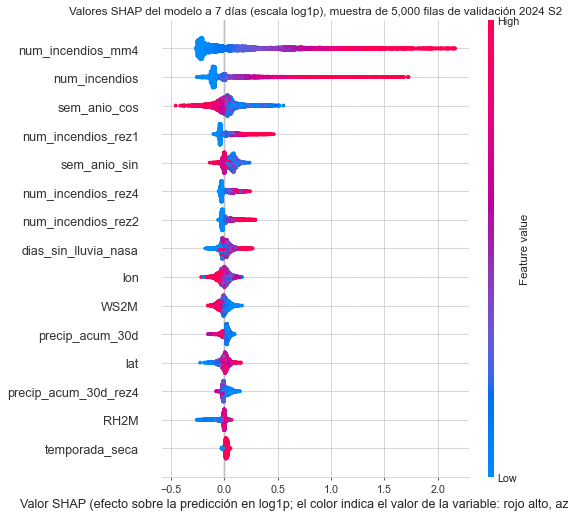

In [42]:
muestra_shap = Xv.sample(5000, random_state=SEMILLA)
explicador = shap.TreeExplainer(modelo7.regressor_)
valores_shap = explicador.shap_values(muestra_shap)
plt.figure(figsize=(10, 7))
shap.summary_plot(valores_shap, muestra_shap, max_display=15, show=False)
plt.title("Valores SHAP del modelo a 7 días (escala log1p), muestra de 5,000 filas de validación 2024 S2")
plt.xlabel("Valor SHAP (efecto sobre la predicción en log1p; el color indica el valor de la variable: rojo alto, azul bajo)")
plt.tight_layout()
plt.show()


**Figura 12.** Valores SHAP de las 15 variables principales del modelo a 7 días, en escala log1p. Cada punto es una fila; el color indica el valor de la variable. Muestra de 5,000 filas de validación (fold 4).


In [43]:
def resumen_shap(valores, datos, n=5):
    # variables con mayor |SHAP| medio y direccion (correlacion entre el valor de la variable y su efecto)
    filas = []
    for j, col in enumerate(datos.columns):
        v = datos[col].to_numpy(float)
        dir_ = np.corrcoef(v, valores[:, j])[0, 1] if v.std() > 0 and valores[:, j].std() > 0 else np.nan
        filas.append({"variable": col, "SHAP_abs_medio": float(np.abs(valores[:, j]).mean()), "correlacion_valor_efecto": dir_})
    t = pd.DataFrame(filas).sort_values("SHAP_abs_medio", ascending=False).head(n)
    t["direccion"] = np.where(t["correlacion_valor_efecto"] > 0.05, "valor alto aumenta la predicción", np.where(t["correlacion_valor_efecto"] < -0.05, "valor alto reduce la predicción", "sin dirección clara"))
    return t.set_index("variable")


print("Las 5 variables principales por SHAP, Frente 1 a 7 días:")
tabla_shap7 = resumen_shap(valores_shap, muestra_shap)
mostrar(tabla_shap7.drop(columns="direccion"), 3)
print(tabla_shap7["direccion"].to_string())
grupos = {"historial de focos": [c for c in col7 if c.startswith("num_incendios")], "clima NASA": [c for c in col7 if c in ("T2M", "RH2M", "WS2M", "precip_nasa_sem", "dias_sin_lluvia_nasa", "precip_acum_30d") or c.startswith(("T2M_", "RH2M_", "precip_", "dias_sin"))],
          "SISAM": [c for c in col7 if c.endswith("_reanalise")], "ubicación y calendario": [c for c in col7 if c in ("lat", "lon", "temporada_seca", "sem_anio_sin", "sem_anio_cos") or c.startswith("uf_")]}
imp_total = np.abs(valores_shap).mean(axis=0)
por_grupo = pd.Series({g: float(imp_total[[col7.index(c) for c in cs]].sum()) for g, cs in grupos.items() if cs}).sort_values(ascending=False)
print("\nSHAP absoluto medio sumado por grupo de variables:")
mostrar((por_grupo / por_grupo.sum() * 100).to_frame("porcentaje_del_SHAP_total"), 1)


Las 5 variables principales por SHAP, Frente 1 a 7 días:
                    SHAP_abs_medio  correlacion_valor_efecto
variable                                                    
num_incendios_mm4            0.388                     0.989
num_incendios                0.188                     0.957
sem_anio_cos                 0.080                    -0.718
num_incendios_rez1           0.070                     0.971
sem_anio_sin                 0.059                    -0.666
variable
num_incendios_mm4     valor alto aumenta la predicción
num_incendios         valor alto aumenta la predicción
sem_anio_cos           valor alto reduce la predicción
num_incendios_rez1    valor alto aumenta la predicción
sem_anio_sin           valor alto reduce la predicción

SHAP absoluto medio sumado por grupo de variables:
                        porcentaje_del_SHAP_total
historial de focos                           57.6
clima NASA                                   22.2
ubicación y calendario        

In [44]:
# Frente 2: importancia por permutacion del modelo final (fold 4) y SHAP de la clase Critico
t2f = ELEGIDOS["f2"]
col2 = LISTAS["f2"][t2f["sisam"]]
tr4b, va4b = filas_validas("f2", f4["idx_entreno"]), filas_validas("f2", f4["idx_valid"])
modelo2 = crear_f2(t2f["modelo"], t2f["tratamiento"], PARAMS_AJUSTADOS["f2"][(t2f["modelo"], t2f["tratamiento"])]).fit(panel.loc[tr4b, col2], panel.loc[tr4b, "clase_t1_ord"].astype(int))
Xv2, yv2 = panel.loc[va4b, col2], panel.loc[va4b, "clase_t1_ord"].astype(int)
print(f"Modelo del Frente 2: {NOMBRES_MODELO[t2f['modelo']]} con {t2f['tratamiento']}; entrenado con {len(tr4b):,} filas y validado con {len(va4b):,}.")
perm2 = permutation_importance(modelo2, Xv2, yv2, n_repeats=5, random_state=SEMILLA, scoring="f1_macro", n_jobs=-1)
imp2 = pd.DataFrame({"variable": col2, "caida_F1_macro": perm2.importances_mean, "desv": perm2.importances_std}).sort_values("caida_F1_macro", ascending=False).head(15)
print("Importancia por permutación (caída del F1 macro al barajar la variable), top 15:")
mostrar(imp2.set_index("variable"), 3)

estimador2 = modelo2.named_steps["modelo"] if hasattr(modelo2, "named_steps") else modelo2
muestra2 = Xv2.sample(min(5000, len(Xv2)), random_state=SEMILLA)
sv = shap.TreeExplainer(estimador2).shap_values(muestra2)
sv_critico = sv[:, :, 3] if np.ndim(sv) == 3 else sv[3]
print("\nLas 5 variables principales por SHAP para la clase Crítico:")
tabla_shap2 = resumen_shap(sv_critico, muestra2)
mostrar(tabla_shap2.drop(columns="direccion"), 3)
print(tabla_shap2["direccion"].to_string())


Modelo del Frente 2: Random Forest con smote; entrenado con 18,997 filas y validado con 6,449.


Importancia por permutación (caída del F1 macro al barajar la variable), top 15:
                           caida_F1_macro  desv
variable                                       
riesgo_fuego_t                      0.209 0.003
precip_acum_30d                     0.028 0.004
dias_sin_lluvia_nasa                0.011 0.001
lon                                 0.008 0.003
num_incendios                       0.007 0.001
sin_riesgo_t                        0.007 0.002
precip_nasa_sem                     0.006 0.001
sem_anio_sin                        0.005 0.001
precip_nasa_sem_rez4                0.004 0.001
WS2M                                0.004 0.001
precip_acum_30d_rez4                0.003 0.001
dias_sin_lluvia_nasa_rez4           0.003 0.001
lat                                 0.003 0.002
uf_AM                               0.003 0.001
dias_sin_lluvia_nasa_rez1           0.003 0.001



Las 5 variables principales por SHAP para la clase Crítico:
                 SHAP_abs_medio  correlacion_valor_efecto
variable                                                 
riesgo_fuego_t            0.125                     0.817
precip_acum_30d           0.066                    -0.713
sin_riesgo_t              0.030                     0.853
lon                       0.029                     0.758
num_incendios             0.025                    -0.817
variable
riesgo_fuego_t     valor alto aumenta la predicción
precip_acum_30d     valor alto reduce la predicción
sin_riesgo_t       valor alto aumenta la predicción
lon                valor alto aumenta la predicción
num_incendios       valor alto reduce la predicción


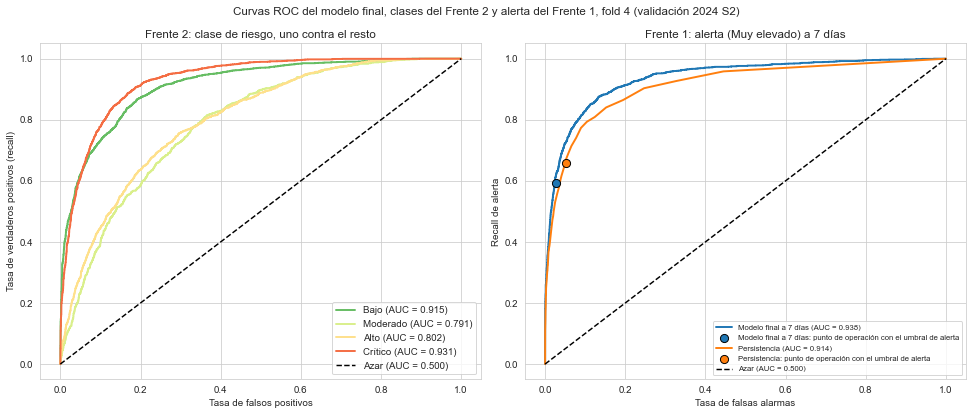

ROC-AUC uno contra el resto del Frente 2 (fold 4): {'Bajo': 0.915, 'Moderado': 0.791, 'Alto': 0.802, 'Crítico': 0.931} | promedio 0.86
ROC-AUC de la alerta del Frente 1 (fold 4): {'Modelo final a 7 días': 0.938, 'Persistencia': 0.914}


In [45]:
# curvas ROC del modelo final (fold 4, validacion 2024 S2): clases del Frente 2 y alerta del Frente 1
proba2 = modelo2.predict_proba(Xv2)
clases2 = list(modelo2.classes_)
colores_clase = dict(zip(CLASES, sns.color_palette("RdYlGn_r", 4)))
auc_clases = {}
fig, ejes = plt.subplots(1, 2, figsize=(14, 6))
for i, clase in enumerate(CLASES):
    fpr, tpr, _ = roc_curve(yv2.to_numpy() == i, proba2[:, clases2.index(i)])
    auc_clases[clase] = auc(fpr, tpr)
    ejes[0].plot(fpr, tpr, color=colores_clase[clase], linewidth=2, label=f"{clase} (AUC = {auc_clases[clase]:.3f})")
ejes[0].plot([0, 1], [0, 1], color="black", linestyle="--", label="Azar (AUC = 0.500)")
ejes[0].set_title("Frente 2: clase de riesgo, uno contra el resto")
ejes[0].set_xlabel("Tasa de falsos positivos")
ejes[0].set_ylabel("Tasa de verdaderos positivos (recall)")
ejes[0].legend(loc="lower right")

umbral_alerta = np.where(panel.loc[va4, "objetivo_seca"].to_numpy() == 1, UMBRAL_SECA, UMBRAL_HUMEDA)
alerta_real = yv.to_numpy() > umbral_alerta
auc_alerta = {}
for etiqueta, puntaje, color in [("Modelo final a 7 días", modelo7.predict(Xv), "tab:blue"), ("Persistencia", panel.loc[va4, "num_incendios_crudo"].to_numpy(float), "tab:orange")]:
    fpr, tpr, _ = roc_curve(alerta_real, puntaje)
    auc_alerta[etiqueta] = auc(fpr, tpr)
    ejes[1].plot(fpr, tpr, color=color, linewidth=2, label=f"{etiqueta} (AUC = {auc_alerta[etiqueta]:.3f})")
    alerta_predicha = puntaje > umbral_alerta
    ejes[1].scatter([(alerta_predicha & ~alerta_real).sum() / (~alerta_real).sum()], [(alerta_predicha & alerta_real).sum() / alerta_real.sum()], color=color, edgecolor="black", s=70, zorder=3,
                    label=f"{etiqueta}: punto de operación con el umbral de alerta")
ejes[1].plot([0, 1], [0, 1], color="black", linestyle="--", label="Azar (AUC = 0.500)")
ejes[1].set_title("Frente 1: alerta (Muy elevado) a 7 días")
ejes[1].set_xlabel("Tasa de falsas alarmas")
ejes[1].set_ylabel("Recall de alerta")
ejes[1].legend(loc="lower right", fontsize=8)
fig.suptitle("Curvas ROC del modelo final, clases del Frente 2 y alerta del Frente 1, fold 4 (validación 2024 S2)")
plt.tight_layout()
plt.show()
print("ROC-AUC uno contra el resto del Frente 2 (fold 4):", {k: round(v, 3) for k, v in auc_clases.items()}, "| promedio", round(float(np.mean(list(auc_clases.values()))), 3))
print("ROC-AUC de la alerta del Frente 1 (fold 4):", {k: round(v, 3) for k, v in auc_alerta.items()})


**Figura 13.** A la izquierda, curvas ROC uno contra el resto de las 4 clases de riesgo del Frente 2 con el modelo final del fold 4. A la derecha, curva ROC de la alerta del Frente 1 a 7 días (modelo final y persistencia), con el punto de operación del umbral de alerta. El AUC está en la leyenda.


In [46]:
# lectura sencilla de la interpretabilidad (SHAP, fold 4) y de las metricas clave del modelo elegido
def sentido_shap(fila):
    return {"valor alto aumenta la predicción": "al subir su valor, sube la predicción", "valor alto reduce la predicción": "al subir su valor, baja la predicción",
            "sin dirección clara": "no tiene una dirección clara"}[fila["direccion"]]


e7, e2_ = ELEGIDOS["f1_7d"], ELEGIDOS["f2"]
print("LECTURA SENCILLA DE LA INTERPRETABILIDAD (modelo entrenado hasta 2024-05-27 y revisado en 2024 S2)")
print(f"\nFrente 1 a 7 días ({NOMBRES_MODELO[e7['modelo']]}, {e7['sisam']} SISAM). Las 5 variables que más influyen:")
for i, (variable, fila) in enumerate(tabla_shap7.iterrows(), start=1):
    print(f"  {i}. {variable}: {sentido_shap(fila)} (efecto medio {fila['SHAP_abs_medio']:.3f}, correlación {fila['correlacion_valor_efecto']:+.2f}).")
m_mae, m_std = valor_cv("f1_7d", "todas", "MAE", e7["modelo"], "ajustado", "no aplica", e7["sisam"])
m_rec, _ = valor_cv("f1_7d", "todas", "recall_alerta", e7["modelo"], "ajustado", "no aplica", e7["sisam"])
m_fal, _ = valor_cv("f1_7d", "todas", "tasa_falsas_alarmas", e7["modelo"], "ajustado", "no aplica", e7["sisam"])
print(f"  Métricas clave en validación: MAE {m_mae:.3f} (desviación {m_std:.3f}), recall de alerta {m_rec:.3f}, falsas alarmas {m_fal:.3f}; AUC de la alerta en el fold 4: {auc_alerta['Modelo final a 7 días']:.3f}.")

print(f"\nFrente 2 ({NOMBRES_MODELO[e2_['modelo']]}, {e2_['tratamiento']}, {e2_['sisam']} SISAM). Las 5 variables que más influyen en que la clase sea Crítico:")
for i, (variable, fila) in enumerate(tabla_shap2.iterrows(), start=1):
    print(f"  {i}. {variable}: {sentido_shap(fila).replace('la predicción', 'la probabilidad de Crítico')} (efecto medio {fila['SHAP_abs_medio']:.3f}, correlación {fila['correlacion_valor_efecto']:+.2f}).")
f1m, f1s = valor_cv("f2", "con_clase_t", "F1_macro", e2_["modelo"], "ajustado", e2_["tratamiento"], e2_["sisam"])
rcm, rcs = valor_cv("f2", "con_clase_t", "recall_critico", e2_["modelo"], "ajustado", e2_["tratamiento"], e2_["sisam"])
print(f"  Métricas clave en validación (filas con clase_t): F1 macro {f1m:.3f} (desviación {f1s:.3f}), recall de Crítico {rcm:.3f} (desviación {rcs:.3f}); AUC de Crítico en el fold 4: {auc_clases['Crítico']:.3f}.")


LECTURA SENCILLA DE LA INTERPRETABILIDAD (modelo entrenado hasta 2024-05-27 y revisado en 2024 S2)

Frente 1 a 7 días (LightGBM, sin SISAM). Las 5 variables que más influyen:
  1. num_incendios_mm4: al subir su valor, sube la predicción (efecto medio 0.388, correlación +0.99).
  2. num_incendios: al subir su valor, sube la predicción (efecto medio 0.188, correlación +0.96).
  3. sem_anio_cos: al subir su valor, baja la predicción (efecto medio 0.080, correlación -0.72).
  4. num_incendios_rez1: al subir su valor, sube la predicción (efecto medio 0.070, correlación +0.97).
  5. sem_anio_sin: al subir su valor, baja la predicción (efecto medio 0.059, correlación -0.67).
  Métricas clave en validación: MAE 3.001 (desviación 2.786), recall de alerta 0.479, falsas alarmas 0.014; AUC de la alerta en el fold 4: 0.938.

Frente 2 (Random Forest, smote, sin SISAM). Las 5 variables que más influyen en que la clase sea Crítico:
  1. riesgo_fuego_t: al subir su valor, sube la probabilidad de Crític

### Hallazgos de esta etapa

**Qué se observa**
- **A 7 días** (modelo del fold 4, validación 2024 S2): la importancia por permutación de `num_incendios_mm4` sube el MAE en **2.582**, la de `num_incendios` en **2.138** y la de `sem_anio_cos` en **1.107**. Por SHAP, las 5 variables principales son `num_incendios_mm4` (**0.388**), `num_incendios` (**0.188**), `sem_anio_cos` (**0.080**), `num_incendios_rez1` (**0.070**) y `sem_anio_sin` (**0.059**). Por grupos: historial de focos **57.6 %**, clima NASA **22.2 %** y ubicación y calendario **20.1 %**.
- **Frente 2:** `riesgo_fuego_t` baja el F1 macro en **0.209** al barajarla; le siguen `precip_acum_30d` (**0.028**) y `dias_sin_lluvia_nasa` (**0.011**). Por SHAP para Crítico: `riesgo_fuego_t` (**0.125**) y `precip_acum_30d` (**0.066**, a más lluvia menos riesgo).
- **Curvas ROC** (ver Figura 13): los AUC del Frente 2 son **0.931** (Crítico), **0.915** (Bajo), **0.802** (Alto) y **0.791** (Moderado). El AUC de la alerta es **0.938** en el modelo final y **0.914** en la persistencia.

**Por qué importa**
- Coincide con el EDA: lo que más pesa es el historial de focos, seguido del clima y la estacionalidad. SISAM no está en la lista de 7 días.
- En el Frente 2 el modelo se apoya sobre todo en el riesgo actual y en la lluvia acumulada, es decir, en el mismo clima con el que INPE calcula el índice.

**Qué implica para el modelado**
- **Limitación:** `riesgo_fuego_promedio` lo calcula INPE a partir de clima, así que la clase del Frente 2 es en parte función del clima. La importancia de `riesgo_fuego_t` y de la lluvia acumulada es esperable y no demuestra por sí sola capacidad predictiva independiente.


## 9. KPI de control: umbrales finales con el modelo final y el punto de operación

Los umbrales de control se recalculan con el **modelo final a 7 días y el punto de operación de la sección 7b** (`k` elegido solo con validación), a partir de las **métricas de validación por fold** (no de 2025), con la misma regla del baseline: el MAE móvil como máximo de la media más una desviación entre folds, el recall de alerta como mínimo de la media menos una desviación, y las falsas alarmas como máximo de la media más una desviación. Se comparan con los umbrales provisionales del baseline. Son una propuesta para validar con el equipo.


In [47]:
filtro = (res["frente"] == "f1_7d") & (res["modelo"] == e7["modelo"]) & (res["variante"] == "ajustado") & (res["sisam"] == e7["sisam"]) & (res["evaluacion"] == "cv_fold")
mae_folds = res[filtro & (res["metrica"] == "MAE")]["valor"]
rec_folds = pd.Series([VAL_K[f"recall_fold{i}"] for i in range(1, 5)])
fal_folds = pd.Series([VAL_K[f"falsas_alarmas_fold{i}"] for i in range(1, 5)])
(mae_m, mae_s), (rec_m, rec_s), (fal_m, fal_s) = (mae_folds.mean(), mae_folds.std()), (rec_folds.mean(), rec_folds.std()), (fal_folds.mean(), fal_folds.std())
umbrales_finales = pd.DataFrame({
    "media_validacion": [mae_m, rec_m, fal_m], "desv_entre_folds": [mae_s, rec_s, fal_s],
    "umbral_final": [mae_m + mae_s, max(0.0, rec_m - rec_s), fal_m + fal_s],
    "umbral_provisional_baseline": [UMBRAL_MAE_MOVIL, UMBRAL_RECALL_ALERTA, UMBRAL_FALSAS_ALARMAS],
}, index=["MAE móvil de 4 semanas (máximo)", "Recall de alerta (mínimo)", "Tasa de falsas alarmas (máximo)"])
umbrales_finales["cambio"] = umbrales_finales["umbral_final"] - umbrales_finales["umbral_provisional_baseline"]
print(f"Modelo final a 7 días: {NOMBRES_MODELO[e7['modelo']]} ({e7['sisam']} SISAM) con k = {K_ELEGIDO:.1f}. Umbrales de control, provisionales contra finales (validación 2023-2024):")
print(umbrales_finales.to_string(float_format=lambda v: f"{v:,.3f}"))
print("\nJustificación de cada cambio:")
print(f"  MAE móvil: media de validación {mae_m:.3f} más una desviación entre folds de {mae_s:.3f}; el modelo final tiene menor MAE que el baseline, pero la dispersión entre folds es grande, así que el máximo cambia de {UMBRAL_MAE_MOVIL:.3f} a {umbrales_finales.iloc[0, 2]:.3f}. El MAE no depende de k.")
print(f"  Recall de alerta: con k = {K_ELEGIDO:.1f} el recall de validación es {rec_m:.3f} (desviación {rec_s:.3f}); el mínimo pasa de {UMBRAL_RECALL_ALERTA:.3f} a {umbrales_finales.iloc[1, 2]:.3f} porque el punto de operación ahora detecta más alertas.")
print(f"  Falsas alarmas: con k = {K_ELEGIDO:.1f} la tasa de validación es {fal_m:.4f} (desviación {fal_s:.4f}); el máximo pasa de {UMBRAL_FALSAS_ALARMAS:.3f} a {umbrales_finales.iloc[2, 2]:.3f}, porque detectar más alertas cuesta más falsas alarmas.")
print("\nComprobación en 2025 (solo informativa, no se usó para fijar los umbrales):")
print(f"  MAE móvil de 4 semanas por encima del umbral final: {(mae_movil > umbrales_finales.iloc[0, 2]).sum()} de {len(mae_movil)} semanas")
print(f"  Recall de alerta en 2025: {M25['calibrado']['recall']:.3f} (mínimo final {umbrales_finales.iloc[1, 2]:.3f}) | falsas alarmas: {M25['calibrado']['falsas_alarmas']:.4f} (máximo final {umbrales_finales.iloc[2, 2]:.3f})")
KPI_CONTROL = {"modelo": f"{NOMBRES_MODELO[e7['modelo']]} {e7['sisam']} SISAM", "factor_k": K_ELEGIDO,
               "regla": "umbrales calculados solo con validacion cruzada (4 folds): MAE movil = media + desviacion; recall de alerta = media - desviacion; falsas alarmas = media + desviacion",
               "mae_movil_4_semanas_maximo": {"final": float(umbrales_finales.iloc[0, 2]), "provisional": UMBRAL_MAE_MOVIL, "media_validacion": float(mae_m), "desv_entre_folds": float(mae_s)},
               "recall_alerta_minimo": {"final": float(umbrales_finales.iloc[1, 2]), "provisional": UMBRAL_RECALL_ALERTA, "media_validacion": float(rec_m), "desv_entre_folds": float(rec_s)},
               "tasa_falsas_alarmas_maximo": {"final": float(umbrales_finales.iloc[2, 2]), "provisional": UMBRAL_FALSAS_ALARMAS, "media_validacion": float(fal_m), "desv_entre_folds": float(fal_s)},
               "comprobacion_2025": {"semanas_mae_movil_sobre_umbral": int((mae_movil > umbrales_finales.iloc[0, 2]).sum()), "semanas_evaluadas": int(len(mae_movil)),
                                     "recall_alerta": float(M25["calibrado"]["recall"]), "tasa_falsas_alarmas": float(M25["calibrado"]["falsas_alarmas"])}}


Modelo final a 7 días: LightGBM (sin SISAM) con k = 1.4. Umbrales de control, provisionales contra finales (validación 2023-2024):
                                 media_validacion  desv_entre_folds  umbral_final  umbral_provisional_baseline  cambio
MAE móvil de 4 semanas (máximo)             3.001             2.786         5.787                        6.408  -0.621
Recall de alerta (mínimo)                   0.581             0.104         0.478                        0.360   0.118
Tasa de falsas alarmas (máximo)             0.024             0.018         0.042                        0.026   0.016

Justificación de cada cambio:
  MAE móvil: media de validación 3.001 más una desviación entre folds de 2.786; el modelo final tiene menor MAE que el baseline, pero la dispersión entre folds es grande, así que el máximo cambia de 6.408 a 5.787. El MAE no depende de k.
  Recall de alerta: con k = 1.4 el recall de validación es 0.581 (desviación 0.104); el mínimo pasa de 0.360 a 0.478 porque 

### Hallazgos de esta etapa

**Qué se observa**
- **Umbrales finales con el modelo final a 7 días y k = 1.4** (validación 2023-2024), provisional contra final: MAE móvil de 4 semanas de como máximo **5.787** (provisional **6.408**; media de validación **3.001** más una desviación de **2.786**), recall de alerta de al menos **0.478** (provisional **0.360**; media **0.581** menos una desviación de **0.104**) y tasa de falsas alarmas de como máximo **0.042** (provisional **0.026**; media **0.024** más una desviación de **0.018**).
- **Comprobación en 2025** (solo informativa): **0** de **48** semanas superan el MAE móvil final; el recall de alerta es **0.494**, sobre el mínimo de **0.478**, y las falsas alarmas son **0.0144**, bajo el máximo de **0.042**.

**Por qué importa**
- El MAE móvil baja porque el modelo final mejora al baseline. El mínimo de recall sube y el máximo de falsas alarmas sube también, porque el punto de operación calibrado detecta más alertas a cambio de más falsas alarmas.

**Qué implica para el modelado**
- Son propuestas para validar con el equipo y quedan guardadas en la clave `kpi_control` de `modelos_metadata.json`. **Limitación:** la desviación entre folds es grande, así que los umbrales de recall y de MAE son amplios.


## 10. Entregables

- `ia_models/modelo_frente1_7d.joblib`, `ia_models/modelo_frente1_30d.joblib` y `ia_models/modelo_frente2.joblib`: modelos finales ajustados con todo el entrenamiento. Los de Frente 1 predicen **focos reales** (el `TransformedTargetRegressor` aplica `log1p` al entrenar y `expm1` al predecir). Se guardan con `joblib.dump(..., compress=3)`.
- `ia_models/modelos_metadata.json`: versión, algoritmo, variables, parámetros, métricas de validación y de 2025, fecha, versiones de librerías y transformación del target. Incluye la clave `alerta` (factor `k`, umbrales y métricas) y la clave `kpi_control` (umbrales de control finales).
- `ia_models/utilidades.py`: funciones propias que usan los modelos guardados (`inv_log1p_no_negativo`, `con_log`, `XGBClasificadorBalanceado`). El notebook las importa de ahí, de modo que `joblib` guarda la referencia al módulo y no a `__main__`.
- `ia_models/requirements.txt`: versiones exactas de las librerías con las que se entrenó.
- `ia_models/probar_carga.py`: prueba de carga en un proceso nuevo, sin el notebook.
- `resultados/avanzado_metricas.csv` (formato largo), `resultados/avanzado_tuning.csv` y `resultados/avanzado_predicciones_2025.csv` (solo el modelo final de cada tarea y la persistencia como referencia).


In [48]:
NOMBRE_ARCHIVO = {"f1_7d": "modelo_frente1_7d.joblib", "f1_30d": "modelo_frente1_30d.joblib", "f2": "modelo_frente2.joblib"}
TAMANOS = {}
for tarea in TAREAS:
    e = ELEGIDOS[tarea]
    variante_clave = (tarea, "ajustado", e["modelo"], e["tratamiento"] if tarea == "f2" else "no aplica", e["sisam"])
    ruta = DIR_MODELOS / NOMBRE_ARCHIVO[tarea]
    joblib.dump(MODELOS_AJUSTADOS[variante_clave], ruta, compress=3)
    TAMANOS[tarea] = ruta.stat().st_size / 1e6
    print(f"Guardado: {ruta.relative_to(BASE)} ({TAMANOS[tarea]:,.2f} MB)")
assert all(t < 50 for t in TAMANOS.values()), "Algún modelo pasa de 50 MB: reducir n_estimators o max_depth"
print("Todos los modelos pesan menos de 50 MB con compress=3.")


Guardado: ia_models\modelo_frente1_7d.joblib (0.81 MB)
Guardado: ia_models\modelo_frente1_30d.joblib (0.65 MB)


Guardado: ia_models\modelo_frente2.joblib (27.74 MB)
Todos los modelos pesan menos de 50 MB con compress=3.


In [49]:
# verificacion: los modelos guardados se cargan de nuevo y reproducen las predicciones de 2025
for tarea in TAREAS:
    e = ELEGIDOS[tarea]
    clave = (tarea, "ajustado", e["modelo"], e["tratamiento"] if tarea == "f2" else "no aplica", e["sisam"])
    modelo = joblib.load(DIR_MODELOS / NOMBRE_ARCHIVO[tarea])
    columnas = LISTAS[frente_de(tarea)][e["sisam"]]
    indices, real, pred_guardada = PRED_2025[clave]
    pred = modelo.predict(panel.loc[indices, columnas]).astype(float)
    assert np.allclose(pred, pred_guardada), f"{tarea}: el modelo guardado no reproduce las predicciones de 2025"
    print(f"OK {tarea}: el modelo cargado reproduce las {len(indices):,} predicciones de 2025 (diferencia máxima {np.abs(pred - pred_guardada).max():.2e})")


OK f1_7d: el modelo cargado reproduce las 27,693 predicciones de 2025 (diferencia máxima 0.00e+00)
OK f1_30d: el modelo cargado reproduce las 27,693 predicciones de 2025 (diferencia máxima 0.00e+00)


OK f2: el modelo cargado reproduce las 6,601 predicciones de 2025 (diferencia máxima 0.00e+00)


In [50]:
def metricas_de(tarea, e):
    # metricas de validacion (promedio y desviacion) y de 2025 del modelo final de la tarea
    sub = "con_clase_t" if tarea == "f2" else "todas"
    variante, trat = "ajustado", (e["tratamiento"] if tarea == "f2" else "no aplica")
    r = res[(res["frente"] == tarea) & (res["modelo"] == e["modelo"]) & (res["variante"] == variante) & (res["tratamiento"] == trat) & (res["sisam"] == e["sisam"]) & (res["subconjunto"] == sub)]
    cv = r[r["evaluacion"] == "cv_fold"].groupby("metrica")["valor"].agg(["mean", "std"])
    p25 = r[r["evaluacion"] == "prueba_2025"].set_index("metrica")["valor"]
    return {"subconjunto": sub, "validacion": {m: {"media": float(cv.loc[m, "mean"]), "desv": float(cv.loc[m, "std"])} for m in cv.index},
            "prueba_2025": {m: float(v) for m, v in p25.items()}}


metadata = {"version_modelos": "1.0.0", "fecha_entrenamiento": datetime.now().strftime("%Y-%m-%d %H:%M:%S"), "semilla": SEMILLA,
            "entrenamiento": {"desde": PARAMS["particiones"]["entrenamiento"][0], "hasta": PARAMS["particiones"]["entrenamiento"][1], "margen_semanas": SEMANAS_MARGEN},
            "versiones_librerias": VERSIONES, "modelos": {}}
for tarea in TAREAS:
    e = ELEGIDOS[tarea]
    params = PARAMS_AJUSTADOS[tarea][(e["modelo"], e["tratamiento"])] if tarea == "f2" else PARAMS_AJUSTADOS[tarea][e["modelo"]]
    metadata["modelos"][tarea] = {
        "archivo": NOMBRE_ARCHIVO[tarea], "algoritmo": NOMBRES_MODELO[e["modelo"]], "tratamiento_desbalance": e["tratamiento"] if tarea == "f2" else None,
        "lista_variables": "con_sisam" if e["sisam"] == "con" else "sin_sisam", "variables": LISTAS[frente_de(tarea)][e["sisam"]], "parametros": params,
        "transformacion_target": ("log1p al entrenar y expm1 con minimo 0 al predecir (el modelo guardado predice focos reales)" if tarea != "f2" else "ninguna: predice la clase ordinal 0 a 3 (Bajo, Moderado, Alto, Crítico)"),
        "origen_parametros": ORIGEN_30D if tarea == "f1_30d" else "busqueda aleatoria de 30 combinaciones con validacion cruzada temporal de 4 folds",
        "tamano_archivo_mb": round(TAMANOS[tarea], 3), "metricas": metricas_de(tarea, e)}
metadata["clases_riesgo"] = {"cortes": [0.40, 0.70, 0.95], "ordinal": ORDINAL}
metadata["alerta"] = ALERTA
metadata["kpi_control"] = KPI_CONTROL
metadata["utilidades"] = {"modulo": "ia_models.utilidades", "nota": "importar este modulo antes de joblib.load; los modelos guardan la referencia a el y no a __main__"}
RUTA_META = DIR_MODELOS / "modelos_metadata.json"
def limpiar(obj):
    # convierte NaN en None para que el JSON sea valido
    if isinstance(obj, dict):
        return {k: limpiar(v) for k, v in obj.items()}
    if isinstance(obj, list):
        return [limpiar(v) for v in obj]
    return None if isinstance(obj, float) and np.isnan(obj) else obj


json.dump(limpiar(metadata), open(RUTA_META, "w", encoding="utf-8"), ensure_ascii=False, indent=2)
print("Guardado:", RUTA_META.relative_to(BASE), f"({RUTA_META.stat().st_size / 1e3:,.1f} KB)")


Guardado: ia_models\modelos_metadata.json (14.5 KB)


In [51]:
# archivos de resultados: metricas en formato largo y predicciones de 2025 (solo modelo final y persistencia)
cv = res[res["evaluacion"] == "cv_fold"].groupby(["frente", "modelo", "variante", "tratamiento", "sisam", "subconjunto", "metrica"])["valor"].agg(["mean", "std"]).reset_index()
largo = pd.concat([cv.rename(columns={"mean": "valor"}).assign(evaluacion="cv_promedio").drop(columns="std"),
                   cv.rename(columns={"std": "valor"}).assign(evaluacion="cv_desviacion").drop(columns="mean"),
                   res[res["evaluacion"] == "prueba_2025"].drop(columns="fold")], ignore_index=True)[
    ["frente", "modelo", "variante", "tratamiento", "sisam", "evaluacion", "subconjunto", "metrica", "valor"]]
RUTA_AV = DIR_RESULTADOS / "avanzado_metricas.csv"
largo.to_csv(RUTA_AV, index=False, encoding="utf-8", float_format="%.6g")
print("Guardado:", RUTA_AV.relative_to(BASE), largo.shape, f"({RUTA_AV.stat().st_size / 1e3:,.1f} KB)")

filas = []
for tarea in TAREAS:
    e = ELEGIDOS[tarea]
    clave = (tarea, "ajustado", e["modelo"], e["tratamiento"] if tarea == "f2" else "no aplica", e["sisam"])
    indices, real, pred = PRED_2025[clave]
    nombre = f"{e['modelo']}_final_{'con' if e['sisam'] == 'con' else 'sin'}_sisam"
    filas.append(pd.DataFrame({"semana": panel.loc[indices, "semana"].dt.strftime("%Y-%m-%d").to_numpy(), "municipio_norm": panel.loc[indices, "municipio_norm"].to_numpy(),
                               "uf": panel.loc[indices, "uf"].to_numpy(), "frente": tarea, "real": np.round(real, 3), "predicho": np.round(pred, 3), "modelo": nombre}))
    te = filas_validas(tarea, idx_prueba)
    pp = persistencia(tarea, te)
    mantener = ~np.isnan(pp)
    filas.append(pd.DataFrame({"semana": panel.loc[te[mantener], "semana"].dt.strftime("%Y-%m-%d").to_numpy(), "municipio_norm": panel.loc[te[mantener], "municipio_norm"].to_numpy(),
                               "uf": panel.loc[te[mantener], "uf"].to_numpy(), "frente": tarea, "real": np.round(panel.loc[te[mantener], OBJETIVO[tarea]].to_numpy(float), 3),
                               "predicho": np.round(pp[mantener], 3), "modelo": "persistencia"}))
salida = pd.concat(filas, ignore_index=True)
RUTA_PRED = DIR_RESULTADOS / "avanzado_predicciones_2025.csv"
salida.to_csv(RUTA_PRED, index=False, encoding="utf-8")
print("Guardado:", RUTA_PRED.relative_to(BASE), salida.shape, f"({RUTA_PRED.stat().st_size / 1e6:,.1f} MB)")
print(salida.groupby(["frente", "modelo"]).size().to_string())
assert salida["semana"].min() >= "2025-01-06" and salida["semana"].max() <= "2025-12-22"


Guardado: resultados\avanzado_metricas.csv (2624, 9) (192.9 KB)


Guardado: resultados\avanzado_predicciones_2025.csv (121286, 7) (7.6 MB)
frente  modelo              
f1_30d  persistencia            27693
        xgb_final_con_sisam     27693
f1_7d   lgbm_final_sin_sisam    27693
        persistencia            27693
f2      persistencia             3913
        rf_final_sin_sisam       6601


In [52]:
# versiones fijas: requirements.txt con las versiones exactas guardadas en modelos_metadata.json y comparacion con las instaladas
import importlib.metadata as im
meta_guardada = json.load(open(RUTA_META, encoding="utf-8"))
PAQUETES = ["scikit-learn", "xgboost", "lightgbm", "imbalanced-learn", "joblib", "numpy", "pandas", "scipy"]
versiones_meta = {p: meta_guardada["versiones_librerias"][p] for p in PAQUETES}
lineas = [f"{p}=={v}" for p, v in versiones_meta.items()]
(DIR_MODELOS / "requirements.txt").write_text(f"# Python {meta_guardada['versiones_librerias']['python']}; versiones exactas de modelos_metadata.json\n" + "\n".join(lineas) + "\n", encoding="utf-8")
print("Guardado:", (DIR_MODELOS / "requirements.txt").relative_to(BASE))
print("\n".join("  " + l for l in lineas))
instaladas = {p: im.version(p) for p in PAQUETES}
tabla_versiones = pd.DataFrame({"requirements.txt": versiones_meta, "instalada en este entorno": instaladas, "coincide": {p: versiones_meta[p] == instaladas[p] for p in PAQUETES}})
print("\nComparación con las versiones instaladas con las que se entrenó:")
print(tabla_versiones.to_string())
assert tabla_versiones["coincide"].all(), "alguna version de requirements.txt no coincide con la instalada"
print("\nTodas las versiones coinciden con las usadas.")


Guardado: ia_models\requirements.txt
  scikit-learn==1.7.2
  xgboost==3.2.0
  lightgbm==4.7.0
  imbalanced-learn==0.14.2
  joblib==1.5.2
  numpy==2.2.4
  pandas==3.1.1
  scipy==1.15.2

Comparación con las versiones instaladas con las que se entrenó:
                 requirements.txt instalada en este entorno  coincide
scikit-learn                1.7.2                     1.7.2      True
xgboost                     3.2.0                     3.2.0      True
lightgbm                    4.7.0                     4.7.0      True
imbalanced-learn           0.14.2                    0.14.2      True
joblib                      1.5.2                     1.5.2      True
numpy                       2.2.4                     2.2.4      True
pandas                      3.1.1                     3.1.1      True
scipy                      1.15.2                    1.15.2      True

Todas las versiones coinciden con las usadas.


In [53]:
# prueba obligatoria en un proceso nuevo: sin el notebook y sin definir nada en __main__
r = subprocess.run([sys.executable, "-I", str(DIR_MODELOS / "probar_carga.py")], capture_output=True, text=True, cwd=str(DIR_MODELOS))
print(r.stdout.strip())
if r.stderr.strip():
    print("stderr:", r.stderr.strip()[-1500:])
assert r.returncode == 0, "la prueba de carga en un proceso nuevo fallo"
print("\nPrueba de carga en proceso nuevo: EN VERDE (los tres modelos reproducen las predicciones de 2025 con diferencia máxima menor a 1e-3).")


Proceso nuevo: __main__ no define funciones del modelo; modulo importado: ia_models.utilidades
OK f1_7d: TransformedTargetRegressor, 27,693 predicciones de 2025, diferencia maxima 5.00e-04 (tolerancia 1e-03)
OK f1_30d: TransformedTargetRegressor, 27,693 predicciones de 2025, diferencia maxima 5.04e-04 (tolerancia 1e-03)
OK f2: Pipeline, 6,601 predicciones de 2025, diferencia maxima 0.00e+00 (tolerancia 1e-03)

Prueba de carga en proceso nuevo: EN VERDE (los tres modelos reproducen las predicciones de 2025 con diferencia máxima menor a 1e-3).


### Hallazgos de esta etapa

**Qué se observa**
- Se guardaron `modelo_frente1_7d.joblib` (**0.81 MB**), `modelo_frente1_30d.joblib` (**0.65 MB**) y `modelo_frente2.joblib` (**27.74 MB**), todos por debajo de 50 MB con `compress=3`. Las funciones propias (`inv_log1p_no_negativo`, `con_log` y `XGBClasificadorBalanceado`) viven en `ia_models/utilidades.py`, así que los modelos guardan la referencia a ese módulo y no a `__main__`.
- Los modelos cargados dentro del notebook reproducen las **27,693** predicciones de 2025 de cada modelo de focos y las **6,601** del Frente 2, con diferencia máxima de cero.
- **Prueba en un proceso nuevo** (sin el notebook): importa `ia_models.utilidades`, carga los tres modelos y reproduce las predicciones de 2025 guardadas, con diferencias máximas de **5.00e-04** (7 días), **5.04e-04** (30 días) y **0.00e+00** (Frente 2), bajo la tolerancia de **1e-03**. La diferencia pequeña viene de que el CSV de predicciones guarda 3 decimales.
- `ia_models/requirements.txt` fija **8** librerías con las versiones exactas de `modelos_metadata.json` y **todas coinciden** con las instaladas.
- También se guardaron `modelos_metadata.json` (**14.5 KB**, con las claves `alerta` y `kpi_control`), `avanzado_metricas.csv` (**2,624** filas), `avanzado_tuning.csv` (**360** combinaciones) y `avanzado_predicciones_2025.csv` (**121,286** filas).

**Por qué importa**
- El backend puede cargar los modelos directamente con `import ia_models.utilidades` y las versiones fijas. Los modelos de focos predicen focos reales (el `log1p` y el `expm1` están dentro del modelo).

**Qué implica para el modelado**
- El modelo a 30 días usa la lista con SISAM, así que el backend necesita las variables de SISAM para esa tarea. La alerta a 7 días se obtiene aplicando `factor_k` a la predicción.


### Conclusiones

- **Mejora frente al baseline:** a 7 días, el MAE de validación baja de **3.274** a **3.001** con el modelo final (LightGBM sin SISAM); a 30 días, de **12.271** a **9.942** (XGBoost con SISAM). En el Frente 2 el F1 macro sube poco (**0.573** frente a **0.555** en las filas con clase de la semana actual).
- **Criterios de éxito:** a 7 días **no se cumplen** (MAE **3.001** frente a **2.946** en validación y **1.270** frente a **1.165** en 2025); a 30 días se cumple en validación (**9.942** frente a **11.044**) pero no en 2025 (**4.616** frente a **4.523**); en el Frente 2 **no se cumplen** (F1 macro **0.572** frente a **0.615** y recall de Crítico **0.503** frente a **0.645**).
- **Frente 2:** el riesgo de fuego es un índice que INPE calcula a partir de clima; el modelo se apoya sobre todo en `riesgo_fuego_t` y en la lluvia acumulada, así que la mejora sobre la persistencia es pequeña.
- **SISAM:** no entra a 7 días ni al Frente 2 y sí entra a 30 días (mejora **1.675 %**).
- **Dónde está el error:** en los picos (sesgo **-19.146** con más de 20 focos) y en la temporada seca (**72.563 %** del error).
- **Alerta:** sin calibrar, el recall de 2025 es **0.371** (persistencia **0.510**). Con el factor **k = 1.4**, elegido solo con validación, sube a **0.494** con falsas alarmas **0.0144** (persistencia **0.0207**); cuesta **3.86** falsas alarmas más por semana y sigue sin alcanzar el recall de la persistencia.
- **Carga y versiones:** los modelos se cargan en un proceso nuevo con `ia_models.utilidades` y reproducen las predicciones de 2025 (diferencia máxima **5.04e-04**, bajo **1e-03**), con versiones fijas en `requirements.txt`.


### Resumen para el informe

- **Modelos y evaluación:** Random Forest, XGBoost y LightGBM con búsqueda aleatoria de **30** combinaciones por modelo, validación cruzada temporal de **4** folds con margen de 4 semanas y prueba 2025 evaluada una sola vez con **39** modelos reajustados. 2026 no se usa.
- **7 días:** el modelo final (LightGBM sin SISAM) tiene MAE **3.001** en validación (baseline **3.274**, persistencia **3.461**) y **1.270** en 2025 (baseline **1.295**). Mejora **8.893 %** al mejor baseline en validación y lo supera en **4** de 4 folds.
- **30 días:** el modelo final (XGBoost con SISAM) tiene MAE **9.942** en validación (baseline **12.271**) y **4.616** en 2025 (baseline **5.025**).
- **Frente 2:** el modelo final (Random Forest con SMOTE sin SISAM) tiene F1 macro **0.572** y recall de Crítico **0.503** en validación (filas con clase de la semana actual), y **0.591** y **0.627** en 2025; la persistencia da **0.555** y **0.545** en validación.
- **Criterios de éxito:** a 7 días y en el Frente 2 **no se cumplen**; a 30 días se cumple solo en validación. No se ajustó nada con 2025.
- **SISAM:** su aporte es pequeño; no entra a 7 días (**0.599 %**) ni al Frente 2, y sí a 30 días (**1.675 %**). **Limitación:** SISAM de 2026 es un pronóstico sin calibrar.
- **Interpretabilidad:** a 7 días domina el historial de focos (**57.6 %** del SHAP), seguido del clima NASA (**22.2 %**). En el Frente 2 pesan `riesgo_fuego_t` y la lluvia acumulada.
- **Errores:** se concentran en la temporada seca (**72.563 %**) y en los picos (sesgo **-19.146** con más de 20 focos); Pará aporta **36.400 %**.
- **Alerta y KPI de control:** con k = 1.4, en 2025 el recall de alerta es **0.494** y las falsas alarmas **0.0144**. Umbrales finales: MAE móvil de 4 semanas de como máximo **5.787** (provisional **6.408**), recall de al menos **0.478** (provisional **0.360**) y falsas alarmas de como máximo **0.042** (provisional **0.026**).
- **Punto de operación de la alerta, en simple:** el modelo se entrena para equivocarse poco en promedio, y por eso se queda corto en los picos: en 2025 detectaba **0.371** de las alertas reales frente a **0.510** de la persistencia. Se multiplicó su predicción por **1.4**, valor elegido solo con 2023 y 2024 (el más bajo que iguala a la persistencia en validación, **0.581** frente a **0.579**). Ahora detecta **0.494** en 2025, **2.80** alertas reales más por semana, y cuesta **3.86** falsas alarmas más por semana (de **3.61** a **7.47**); aun así hay menos falsas alarmas que con la persistencia (**10.78** por semana).
- **Limitaciones:** los parámetros de preparación se ajustaron con todo el entrenamiento y no por fold; los parámetros de 7 días se reutilizan a 30; SMOTE sobre variables binarias genera valores intermedios; y el Frente 2 es en parte función del clima porque `riesgo_fuego_promedio` lo calcula INPE a partir de variables climáticas.
- **Entregables:** modelos en `ia_models/` (**0.81**, **0.65** y **27.74 MB**), con `utilidades.py`, `requirements.txt` y `modelos_metadata.json`; cargan en un proceso nuevo y reproducen las predicciones de 2025. Resultados en `resultados/`.
